# Klasifikasi Penutup Lahan Jawa Timur Berbasis Sentinel-2 dan Perbandingan Algoritma Machine Learning

**Nama** : Rian Renaldy

**NIM** : 240411100053

**Mata kuliah:** Proyek Sains Data

**Aplikasi online:** peta hasil klasifikasi, tabel jumlah piksel, dan akurasi model dapat dibuka langsung di [https://sig-klasifikasi-jatimgit-jr9fczew66fhmldtpgufmi.streamlit.app/](https://sig-klasifikasi-jatimgit-jr9fczew66fhmldtpgufmi.streamlit.app/).

Notebook ini berisi alur lengkap: **pemahaman data → pengumpulan data → deskripsi fitur → eksplorasi data → pemodelan (KNN sebagai dasar) → eksperimen dan perbandingan beberapa model → peta hasil klasifikasi**. Setiap tahap disertai penjelasan agar dapat langsung dipublikasikan pada web statis.

**Daftar isi**
1. Data Understanding (tujuan analisis, wilayah, kelas, band Sentinel-2A, acuan klasifikasi lahan Indonesia)
2. Data Collection (shapefile, penentuan sampel, ekstraksi citra)
3. Deskripsi Fitur dan Rumusnya
4. Eksplorasi Data (EDA)
5. Pemodelan dasar K-Nearest Neighbors (KNN) (data training dan testing, jumlah piksel training/testing)
6. Eksperimen (rasio split, kombinasi fitur, hyperparameter KNN, jumlah data latih) dan perbandingan beberapa model untuk memilih akurasi tertinggi
7. Peta Hasil Klasifikasi (Folium + Google Satellite), koreksi konteks spasial, dan implikasi kebijakan
8. Sistem Informasi: Streamlit dan Web Statis
9. Kesimpulan

# 1. Data Understanding

## 1.1 Latar Belakang
Informasi penggunaan dan tutupan lahan (*Land Use / Land Cover*, LULC) penting untuk perencanaan tata ruang, pemantauan alih fungsi lahan pertanian, pelestarian ekosistem pesisir, dan pengelolaan sumber daya air. Pemetaan manual memerlukan waktu dan biaya besar. Citra satelit multispektral seperti **Sentinel-2A** menyediakan data gratis, berresolusi tinggi (10 m), dan berulang setiap beberapa hari, sehingga cocok untuk klasifikasi lahan secara otomatis dengan teknik *machine learning*.

## 1.2 Tujuan Analisis *Land Use and Land Classification*
1. **Mengklasifikasikan** tutupan/penggunaan lahan di wilayah Jawa Timur ke dalam 6 kelas (sawah, bangunan, mangrove, lahan hijau, perairan terbuka/laut, danau/ranu) berdasarkan nilai reflektansi band Sentinel-2A dan indeks spektralnya.
2. **Memahami karakteristik spektral** tiap kelas lahan, yaitu band dan indeks mana yang paling membedakan satu kelas dari kelas lain.
3. **Membangun dan mengevaluasi model klasifikasi (KNN sebagai dasar, dibandingkan dengan Random Forest, Extra Trees, SVM, Gradient Boosting, dan algoritma lain)** (akurasi, presisi, *recall*, F1-score, Kappa, *confusion matrix*) pada data *training* dan *testing*.
4. **Melakukan eksperimen** terhadap rasio pembagian data, kombinasi fitur, serta hyperparameter KNN (jumlah tetangga $k$, skema bobot, dan metrik jarak) untuk memperoleh konfigurasi terbaik.
5. **Menyajikan peta hasil klasifikasi** di atas citra satelit Google Maps menggunakan Folium agar mudah diinterpretasi secara visual.
6. **Mengaitkan hasil dengan kebijakan**, yaitu luas tiap kelas sebagai bahan analisis perlindungan lahan sawah, pengendalian alih fungsi lahan menjadi bangunan, dan konservasi mangrove (bagian 7.3).

## 1.3 Wilayah Studi
Provinsi **Jawa Timur**, Indonesia (kira-kira 111°–114,6° BT dan 6,5°–8,8° LS). Wilayah ini beragam: pegunungan dan taman nasional (Alas Purwo, Bromo-Tengger), dataran persawahan, kawasan permukiman padat (Surabaya–Sidoarjo–Gresik), pesisir bermangrove, danau/waduk, serta Laut Jawa, Selat Madura, dan Samudra Hindia.

## 1.4 Kelas dan Jumlah Data
Data referensi berupa **shapefile poligon** yang berisi area contoh (*training area*) tiap kelas. Dari tiap poligon diambil titik sampel, lalu nilai pikselnya diekstrak dari citra Sentinel-2A.

| ID | Kelas | Berkas shapefile (ZIP) | Target jumlah sampel |
|---|---|---|---|
| 1 | Sawah | `sawah.zip` | 60 |
| 2 | Bangunan | `bangunan.zip` | 60 |
| 3 | Mangrove | `mangrove.zip` | 60 |
| 4 | Lahan hijau | `lahan_hijau.zip` | 60 |
| 5 | Perairan terbuka (laut) | `laut.zip` | 60 |
| 6 | Danau (ranu) | `danau.zip` | 60 |
| | **Total** | | **360 sampel, 6 kelas** |

> **Catatan Keseimbangan Sampel:** Setiap kelas memiliki 60 poligon dan dari tiap poligon diambil satu titik sampel, sehingga jumlah sampel seimbang pada keenam kelas (60 per kelas). Sampel laut dan danau yang tersebar di berbagai zona penting agar model tidak keliru mengklasifikasikan perairan.

## 1.5 Band pada Sentinel-2A
Sentinel-2A membawa sensor **MSI (MultiSpectral Instrument)** dengan **13 band** pada rentang cahaya tampak sampai inframerah gelombang pendek (SWIR). Lebar sapuan 290 km. Resolusi spasialnya 10 m, 20 m, dan 60 m tergantung band.

| Band | Nama | Panjang gelombang tengah (nm) | Resolusi | Kegunaan utama | Dipakai? |
|---|---|---|---|---|---|
| B1 | Coastal aerosol | 443 | 60 m | Koreksi aerosol atmosfer, studi perairan pesisir | Tidak |
| B2 | Blue (Biru) | 492 | 10 m | Penetrasi air, pembeda tanah/vegetasi, bangunan | **Ya** |
| B3 | Green (Hijau) | 560 | 10 m | Puncak pantulan vegetasi sehat, indeks air | **Ya** |
| B4 | Red (Merah) | 665 | 10 m | Penyerapan klorofil, pembeda vegetasi dan lahan terbuka | **Ya** |
| B5 | Red Edge 1 | 704 | 20 m | Kandungan klorofil, kesehatan vegetasi | **Ya** |
| B6 | Red Edge 2 | 740 | 20 m | Struktur kanopi vegetasi | **Ya** |
| B7 | Red Edge 3 | 783 | 20 m | Struktur kanopi vegetasi | **Ya** |
| B8 | NIR (Near Infrared) | 833 | 10 m | Biomassa vegetasi, pemisah daratan dan air | **Ya** |
| B8A | Narrow NIR (Red Edge 4) | 865 | 20 m | Vegetasi, kadar air tanaman | **Ya** |
| B9 | Water vapour | 945 | 60 m | Koreksi uap air atmosfer | Tidak |
| B10 | SWIR-Cirrus | 1374 | 60 m | Deteksi awan cirrus (tidak ada pada produk Level-2A) | Tidak |
| B11 | SWIR 1 | 1614 | 20 m | Kelembapan vegetasi/tanah, area terbangun, pembeda air | **Ya** |
| B12 | SWIR 2 | 2202 | 20 m | Tanah terbuka, area terbangun, lahan terbakar | **Ya** |

Band B1, B9, dan B10 tidak dipakai karena dirancang untuk koreksi atmosfer dan deteksi awan, bukan untuk membedakan jenis lahan. Produk yang dipakai adalah **Sentinel-2 Level-2A (Surface Reflectance)** dari **Microsoft Planetary Computer**, yaitu citra yang sudah dikoreksi atmosfer sehingga nilainya berupa reflektansi permukaan (0 sampai 1).

## 1.6 Alur Kerja
```
Shapefile (6 kelas) → titik sampel → ekstraksi nilai band Sentinel-2A (Planetary Computer)
   → hitung indeks spektral → dataset fitur (CSV) → EDA
   → split train/test → StandardScaler + K-Nearest Neighbors (KNN) → evaluasi → eksperimen
   → prediksi piksel pada area studi → peta Folium di atas Google Satellite
```

## 1.7 Acuan Klasifikasi Lahan di Indonesia
Klasifikasi lahan di Indonesia tidak berhenti pada sawah dan bukan sawah. Acuan yang dipakai adalah standar penutup lahan nasional:

* **SNI 7645-1:2014 Klasifikasi Penutup Lahan** (Badan Informasi Geospasial) untuk skala kecil dan menengah, yang membagi penutup lahan menjadi daerah bervegetasi (pertanian, hutan, semak, dan lainnya), daerah tak bervegetasi (lahan terbangun dan lahan terbuka), serta perairan.
* **Klasifikasi penutupan lahan Kementerian Lingkungan Hidup dan Kehutanan (KLHK)** dengan 23 kelas, antara lain hutan lahan kering, hutan mangrove, sawah, tambak, permukiman, dan tubuh air.

Enam kelas pada notebook ini adalah penyederhanaan kelas-kelas tersebut sesuai tujuan analisis dan ketersediaan data sampel:

| Kelas notebook | Padanan pada SNI 7645-1:2014 | Padanan pada klasifikasi KLHK |
|---|---|---|
| Sawah | Daerah bervegetasi: pertanian (sawah) | Sawah |
| Bangunan | Daerah tak bervegetasi: lahan terbangun | Permukiman dan lahan terbangun |
| Mangrove | Daerah bervegetasi: hutan mangrove | Hutan mangrove |
| Lahan hijau | Daerah bervegetasi: hutan lahan kering, semak, dan vegetasi lain | Hutan lahan kering, semak/belukar |
| Perairan terbuka (laut) | Perairan: laut | Tubuh air |
| Danau (ranu) | Perairan: danau dan waduk | Tubuh air |

# 2. Data Collection

## 2.1 Persiapan Lingkungan dan Konfigurasi
Citra diambil dari **Microsoft Planetary Computer** melalui API **STAC** (koleksi `sentinel-2-l2a`, reflektansi permukaan). Layanan ini gratis dan untuk pemakaian pada notebook ini **tidak memerlukan akun, token, maupun kredensial**, sehingga tidak ada kuota *Processing Units* yang bisa habis. Citra disimpan dalam format *Cloud Optimized GeoTIFF* sehingga hanya bagian yang dibutuhkan (satu piksel untuk titik sampel, satu ubin untuk peta) yang dibaca, bukan seluruh file scene yang berukuran ratusan MB.

Pengolahan (masking awan, komposit median, dan konversi reflektansi) dijalankan di komputer atau *runtime* Anda, bukan di server penyedia citra. Karena itu proses pembuatan peta (bagian 7) membutuhkan waktu dan koneksi internet yang stabil.

Sesuaikan juga `DATA_DIR`: folder induk tempat data sampel berada. Letakkan enam shapefile di folder tersebut dalam bentuk `.zip` bernama kelas (`sawah.zip`, `bangunan.zip`, `mangrove.zip`, `lahan_hijau.zip`, `laut.zip`, `danau.zip`). ZIP diekstrak otomatis dan nama berkas di dalamnya bebas. Notebook juga menerima folder bernama kelas atau berkas `.shp` bernama kelas. Pencarian tidak membedakan huruf besar-kecil dan mengabaikan garis bawah.


In [1]:
# Jalankan sel ini sekali untuk memasang pustaka yang dibutuhkan (boleh dilewati jika sudah terpasang).
# Jika setelah instalasi masih muncul ModuleNotFoundError, restart kernel lalu jalankan ulang dari atas.
%pip install -q geopandas folium seaborn scikit-learn pystac-client planetary-computer rasterio odc-stac xarray dask scipy xgboost lightgbm

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 41.8/41.8 kB 2.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.1/44.1 kB 1.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 159.6/159.6 kB 6.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 58.7/58.7 kB 2.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 117.3/117.3 kB 6.0 MB/s eta 0:00:00


In [2]:
import os, math, time, glob, shutil, warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import geopandas as gpd
import folium
from folium.raster_layers import ImageOverlay
from shapely.geometry import Point
from IPython.display import display, Markdown

from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.model_selection import (train_test_split, RepeatedStratifiedKFold,
                                     cross_val_score, GridSearchCV)
from sklearn.metrics import (accuracy_score, classification_report, confusion_matrix,
                             cohen_kappa_score, f1_score)

# ----------------- KONFIGURASI (SESUAIKAN) -----------------
SIMPAN_KE_DRIVE   = True                           # True: simpan hasil di Google Drive agar tidak hilang saat sesi Colab berakhir
NAMA_FOLDER_DRIVE = "klasifikasi_jatim"            # folder di "Drive Saya" (MyDrive)

try:
    import google.colab                            # noqa: F401
    DI_COLAB = True
except ImportError:
    DI_COLAB = False

if DI_COLAB and SIMPAN_KE_DRIVE:
    from google.colab import drive
    drive.mount("/content/drive")                  # jendela izin muncul sekali
    FOLDER_KERJA = f"/content/drive/MyDrive/{NAMA_FOLDER_DRIVE}"
    os.makedirs(FOLDER_KERJA, exist_ok=True)
    for z in glob.glob("*.zip"):                   # salin ZIP shapefile yang diunggah ke Colab (sekali saja)
        tujuan = os.path.join(FOLDER_KERJA, os.path.basename(z))
        if not os.path.exists(tujuan):
            shutil.copy(z, tujuan)
else:
    FOLDER_KERJA = "."
print("Folder kerja (data dan hasil disimpan di sini):", os.path.abspath(FOLDER_KERJA))

DATA_DIR    = FOLDER_KERJA                         # folder berisi shapefile (ZIP)
TANGGAL_MULAI, TANGGAL_AKHIR = "2025-01-01", "2025-12-31"   # periode citra
MAX_CLOUD   = 30                                   # maks. % awan per scene
HANYA_SENTINEL_2A = False                          # False = semua Sentinel-2 (2A/2B/2C, sensor MSI sama); True = hanya 2A
SEED        = 42                                   # agar hasil dapat direproduksi
CSV_DATASET = os.path.join(FOLDER_KERJA, "dataset_sentinel2_jatim.csv")
ULANGI_EKSTRAKSI = False                           # True: paksa ambil ulang dari Planetary Computer
# ------------------------------------------------------------

# id : nama kelas, berkas shapefile, target sampel, warna peta
KELAS = {
    1: dict(nama="Sawah",                   file="sawah",        n=60, warna="#FFD92F"),
    2: dict(nama="Bangunan",                file="bangunan",     n=60, warna="#E41A1C"),
    3: dict(nama="Mangrove",                file="mangrove",     n=60, warna="#8E44AD"),
    4: dict(nama="Lahan hijau",             file="lahan_hijau",  n=60, warna="#2E7D32"),
    5: dict(nama="Perairan terbuka (laut)", file="laut",          n=60, warna="#0D47A1"),
    6: dict(nama="Danau (ranu)",             file="danau",        n=60, warna="#4FC3F7"),
}
# nama kelas pada CSV hasil eksekusi lama -> nama baru (CSV di Drive tetap bisa dipakai, tidak perlu ekstraksi ulang)
NAMA_LAMA   = {"Lahan Hijau": "Lahan hijau", "Perairan Terbuka (Laut)": "Perairan terbuka (laut)", "Danau": "Danau (ranu)"}
NAMA_KELAS  = [v["nama"] for v in KELAS.values()]
WARNA_KELAS = {v["nama"]: v["warna"] for v in KELAS.values()}
print("Jumlah kelas:", len(KELAS), "->", NAMA_KELAS)

Mounted at /content/drive
Folder kerja (data dan hasil disimpan di sini): /content/drive/MyDrive/klasifikasi_jatim
Jumlah kelas: 6 -> ['Sawah', 'Bangunan', 'Mangrove', 'Lahan hijau', 'Perairan terbuka (laut)', 'Danau (ranu)']


**Berkas yang tersimpan di folder kerja (Google Drive bila `SIMPAN_KE_DRIVE = True`)** sehingga sesi berikutnya tidak perlu mengunggah ulang atau memproses ulang:

| Berkas | Dibuat oleh | Dipakai ulang untuk |
|---|---|---|
| `sawah.zip`, `bangunan.zip`, ... (6 ZIP shapefile) | disalin otomatis dari Colab | membaca data sampel |
| `dataset_sentinel2_jatim.csv` | ekstraksi band titik sampel (bagian 3.3) | melewati ekstraksi 15–40 menit |
| `batas_provinsi.geojson` | bagian 7.0 | melewati unduhan batas wilayah |
| `label_peta.npz` | prediksi peta (bagian 7.1) | melanjutkan/melewati prediksi ubin |
| `hasil_klasifikasi_jatim.html` | peta Folium (bagian 7.2) | ditanam di web statis |
| `jumlah_piksel_per_sampel.csv` | bagian 5.2.1 | tabel piksel per sampel |
| `model_terbaik.joblib`, `streamlit_app/` | bagian 8 | deploy Streamlit |

## 2.2 Membaca Shapefile
Shapefile dibaca langsung dari ZIP kelasnya. Setiap shapefile berisi poligon area contoh. Seluruh shapefile memiliki file `.prj` yang menyatakan sistem koordinat **WGS84 geografis (EPSG:4326)**, dengan satuan derajat (111–114 BT, −6 s.d. −9 LS). Kode tetap memeriksa CRS dan mengonversinya ke EPSG:4326 bila berbeda. Poligon yang tidak valid diperbaiki dengan `buffer(0)`.

In [3]:
import zipfile
from pathlib import Path

def baca_shp(path):
    g = gpd.read_file(path)
    g = g.set_crs(4326) if g.crs is None else g.to_crs(4326)
    g = g[g.geometry.notnull() & ~g.geometry.is_empty].copy()
    g["geometry"] = g.geometry.apply(lambda x: x if x.is_valid else x.buffer(0))
    return g[["geometry"]].reset_index(drop=True)

def _norm(teks):
    return teks.lower().replace(" ", "").replace("_", "").replace("-", "")

ALIAS = {"laut": ["lautan"], "lahan_hijau": ["lahanhijau", "hutan_atau_lahan_hijau"]}   # nama lain yang diterima

def _shp_pertama(folder):
    daftar = sorted(Path(folder).rglob("*.shp"))
    return str(daftar[0]) if daftar else None

def cari_shp(nama):
    """Mencari shapefile kelas `nama` di DATA_DIR dengan urutan: (1) <nama>.zip, (2) folder bernama <nama>,
    (3) berkas <nama>.shp. Nama tidak membedakan huruf besar-kecil dan mengabaikan garis bawah.
    Isi ZIP atau folder boleh memakai nama berkas apa pun (mis. input.shp)."""
    target = {_norm(nama)} | {_norm(a) for a in ALIAS.get(nama, [])}
    ekstrak = Path(DATA_DIR) / "_shp_ekstrak"
    for root, dirs, files in os.walk(DATA_DIR):
        dirs[:] = [d for d in dirs if d != "_shp_ekstrak"]
        for f in sorted(files):
            if f.lower().endswith(".zip") and _norm(f[:-4]) in target:
                tujuan = ekstrak / _norm(f[:-4])
                with zipfile.ZipFile(os.path.join(root, f)) as zf:
                    zf.extractall(tujuan)
                p = _shp_pertama(tujuan)
                if p:
                    return p
    for root, dirs, files in os.walk(DATA_DIR):
        dirs[:] = [d for d in dirs if d != "_shp_ekstrak"]
        for d in dirs:
            if _norm(d) in target:
                p = _shp_pertama(os.path.join(root, d))
                if p:
                    return p
        for f in files:
            if f.lower().endswith(".shp") and _norm(f[:-4]) in target:
                return os.path.join(root, f)
    raise FileNotFoundError(f"Shapefile kelas '{nama}' tidak ditemukan di '{os.path.abspath(DATA_DIR)}'. "
                            f"Letakkan {nama}.zip, folder {nama}/, atau {nama}.shp di folder tersebut.")

jalur_shp = {k: cari_shp(v["file"]) for k, v in KELAS.items()}
for k, p in jalur_shp.items():
    print(f"{KELAS[k]['nama']:<26} -> {p}")
poligon = {k: baca_shp(p) for k, p in jalur_shp.items()}

ringkas = []
for k, v in KELAS.items():
    g = poligon[k]
    luas_ha = g.to_crs(32749).area.sum() / 10_000      # UTM 49S, untuk luas dalam hektar
    b = g.total_bounds
    ringkas.append({"ID": k, "Kelas": v["nama"], "Jumlah poligon": len(g),
                    "Total luas (ha)": round(luas_ha, 1), "Target sampel": v["n"],
                    "BT min": round(b[0], 3), "LS min": round(b[1], 3),
                    "BT maks": round(b[2], 3), "LS maks": round(b[3], 3)})
display(pd.DataFrame(ringkas).set_index("ID"))

Sawah                      -> /content/drive/MyDrive/klasifikasi_jatim/_shp_ekstrak/sawah/input.shp
Bangunan                   -> /content/drive/MyDrive/klasifikasi_jatim/_shp_ekstrak/bangunan/input.shp
Mangrove                   -> /content/drive/MyDrive/klasifikasi_jatim/_shp_ekstrak/mangrove/input.shp
Lahan hijau                -> /content/drive/MyDrive/klasifikasi_jatim/_shp_ekstrak/lahanhijau/input.shp
Perairan terbuka (laut)    -> /content/drive/MyDrive/klasifikasi_jatim/_shp_ekstrak/laut/input.shp
Danau (ranu)               -> /content/drive/MyDrive/klasifikasi_jatim/_shp_ekstrak/danau/input.shp


,Kelas,Jumlah poligon,Total luas (ha),Target sampel,BT min,LS min,BT maks,LS maks
ID,,,,,,,,
1,Sawah,60,18514.5,60,111.528,-7.698,112.703,-7.090
2,Bangunan,60,2867.1,60,111.097,-8.236,114.375,-6.891
3,Mangrove,60,1608.1,60,112.328,-8.617,114.342,-6.847
4,Lahan hijau,60,59972.5,60,111.538,-8.754,114.595,-7.614
5,Perairan terbuka (laut),60,121781.0,60,110.968,-8.650,114.468,-6.683
6,Danau (ranu),60,2436.7,60,111.214,-8.198,113.536,-5.769


## 2.3 Penentuan Titik Sampel
Dari setiap kelas diambil titik sampel sesuai target (60 titik per kelas): total 360 sampel.

* Jika jumlah poligon **≥ target**, dipilih poligon secara acak dan diambil **satu titik representatif di dalam poligon** (`representative_point`, dijamin berada di dalam poligon). Dengan satu titik per poligon, sampel tersebar dan tidak saling berdekatan.
* Jika jumlah poligon **< target**, semua poligon dipakai, kekurangannya ditambah titik acak di dalam poligon.

Pemilihan acak memakai `SEED` tetap agar hasil bisa direproduksi.

In [4]:
rng = np.random.default_rng(SEED)

def titik_acak(poly, rng, maks=300):
    minx, miny, maxx, maxy = poly.bounds
    for _ in range(maks):
        p = Point(rng.uniform(minx, maxx), rng.uniform(miny, maxy))
        if poly.contains(p):
            return p
    return poly.representative_point()

def ambil_sampel(gdf, n, rng):
    polys = list(gdf.geometry)
    urutan = rng.permutation(len(polys))
    hasil = []
    if len(polys) >= n:
        for i in urutan[:n]:
            hasil.append((polys[i].representative_point(), int(i)))
    else:
        for i in urutan:
            hasil.append((polys[i].representative_point(), int(i)))
        while len(hasil) < n:
            i = int(rng.integers(len(polys)))
            hasil.append((titik_acak(polys[i], rng), i))
    return hasil

baris = []
for k, v in KELAS.items():
    for p, pid in ambil_sampel(poligon[k], v["n"], rng):
        baris.append({"kelas_id": k, "kelas": v["nama"], "poligon_id": pid, "lon": p.x, "lat": p.y})
df_titik = pd.DataFrame(baris).reset_index(drop=True)
df_titik.index.name = "idx"
print("Total titik sampel:", len(df_titik))
display(df_titik["kelas"].value_counts().reindex(NAMA_KELAS).to_frame("jumlah titik"))

Total titik sampel: 360


,jumlah titik
kelas,
Sawah,60
Bangunan,60
Mangrove,60
Lahan hijau,60
Perairan terbuka (laut),60
Danau (ranu),60


### 2.3.1 Peta Sebaran Sampel

Poligon dan titik sampel ditampilkan di atas citra satelit Google. Tiap kelas berada pada lapisan terpisah yang dapat dihidupkan atau dimatikan lewat kotak centang di pojok kanan atas. Arahkan kursor ke poligon atau titik untuk melihat kelas dan ID-nya.

In [5]:
from folium.plugins import Fullscreen

GOOGLE_SAT = "https://mt1.google.com/vt/lyrs=s&x={x}&y={y}&z={z}"
GOOGLE_HYB = "https://mt1.google.com/vt/lyrs=y&x={x}&y={y}&z={z}"

def swatch(nama, warna):
    return f'<span style="background:{warna};opacity:.85;display:inline-block;width:12px;height:12px;border:1px solid #333"></span> {nama}'

def peta_dasar(bounds=None):
    m = folium.Map(location=[-7.75, 112.6], zoom_start=8, tiles=None, control_scale=True)
    folium.TileLayer(GOOGLE_SAT, attr="Google", name="Satelit Google", max_zoom=20).add_to(m)
    folium.TileLayer(GOOGLE_HYB, attr="Google", name="Satelit + label Google", max_zoom=20, show=False).add_to(m)
    folium.TileLayer("OpenStreetMap", name="OpenStreetMap", show=False).add_to(m)
    Fullscreen().add_to(m)
    if bounds is not None:
        m.fit_bounds([[bounds[1], bounds[0]], [bounds[3], bounds[2]]])
    return m

# Gabungkan poligon semua kelas menjadi satu GeoDataFrame (uid, kelas_id, kelas, geometry)
poligon_semua = pd.concat(
    [gpd.GeoDataFrame({"uid": [f"{v['file']}-{j}" for j in range(len(poligon[k]))],
                       "kelas_id": k, "kelas": v["nama"]},
                      geometry=poligon[k].geometry.values, crs=4326)
     for k, v in KELAS.items()], ignore_index=True)

m_sampel = peta_dasar(poligon_semua.total_bounds)
for kid, k in KELAS.items():
    fg = folium.FeatureGroup(name=swatch(k["nama"], k["warna"]), show=True).add_to(m_sampel)
    sub = poligon_semua[poligon_semua.kelas_id == kid]
    folium.GeoJson(sub[["uid", "kelas", "geometry"]].to_json(),
                   style_function=lambda f, c=k["warna"]: {"color": c, "weight": 2, "fillColor": c, "fillOpacity": 0.5},
                   tooltip=folium.GeoJsonTooltip(fields=["kelas", "uid"], aliases=["Kelas:", "ID:"])).add_to(fg)
    for _, r in df_titik[df_titik.kelas_id == kid].iterrows():        # titik sampel yang dipakai (satu per poligon)
        folium.CircleMarker([r.lat, r.lon], radius=4, color="white", weight=1, fill=True,
                            fill_color=k["warna"], fill_opacity=1,
                            tooltip=f'{k["nama"]} (poligon {int(r.poligon_id)})').add_to(fg)
folium.LayerControl(position="topright", collapsed=False).add_to(m_sampel)
m_sampel

## 2.4 Pengambilan Citra Sentinel-2A (Microsoft Planetary Computer)
Citra diambil dari katalog **STAC Microsoft Planetary Computer** pada koleksi **Sentinel-2 L2A** (reflektansi permukaan). Langkah pengolahannya sama untuk titik sampel (bagian 3.3) dan peta seluruh Jawa Timur (bagian 7), sehingga data latih dan data prediksi berasal dari sumber dan perlakuan yang sama:

1. **Filter:** periode tanggal dan persentase tutupan awan per scene (`MAX_CLOUD`). Pilihan `HANYA_SENTINEL_2A` membuang citra dari satelit lain (2B/2C) memakai nama scene (berawalan `S2A`).
2. **Pemilihan scene:** diambil scene dengan tutupan awan terendah (12 scene per titik sampel). Untuk peta, diambil 5 scene terbersih untuk setiap tile MGRS yang tercakup ubin, sehingga seluruh wilayah tertutup citra.
3. **Masking awan:** memakai band **SCL** (*Scene Classification Layer*). Piksel kelas 3 (bayangan awan), 8 dan 9 (awan), 10 (cirrus), serta 11 (salju/es) dibuang.
4. **Konversi reflektansi:** nilai DN dikonversi menjadi reflektansi 0 sampai 1 dengan $\rho = DN \times 0{,}0001 - 0{,}1$ (*scale* dan *offset* dari metadata STAC).
5. **Komposit median:** nilai **median** dari seluruh citra bersih dihitung per piksel dan per band, sehingga sisa awan dan *noise* musiman berkurang.
6. **Penyeragaman resolusi:** band 20 m (B5, B6, B7, B8A, B11, B12) disampel ulang ke grid permintaan. Titik sampel dibaca pada piksel aslinya, sedangkan peta dibuat pada resolusi `SKALA_PETA` (120 m).
7. **Hasil:** 10 band reflektansi (0 sampai 1). Ke-8 **indeks spektral** (bagian 3) dihitung di Python dari band tersebut.

> Band B2, B3, B4, B8 pada katalog STAC bernama `B02`, `B03`, `B04`, `B08`; pada notebook ini dinamai ulang menjadi `B2`, `B3`, `B4`, `B8` agar singkat.

> **Catatan versi ini:** seluruh data citra (titik sampel dan peta) berasal dari Microsoft Planetary Computer. Layanan Copernicus Data Space (Sentinel Hub) tidak dipakai lagi karena kuota *Processing Units* akun gratis terbatas.

> **Catatan satelit:** judul notebook menyebut Sentinel-2A, tetapi dengan `HANYA_SENTINEL_2A = False` scene dari Sentinel-2A, 2B, dan 2C ikut dipakai. Ketiganya membawa sensor MSI yang sama (band, panjang gelombang, dan resolusi sama) sehingga dapat digabung, dan ini memperbanyak scene bebas awan. Bila dosen mensyaratkan hanya Sentinel-2A, set `HANYA_SENTINEL_2A = True`, hapus `dataset_sentinel2_jatim.csv` dan `label_peta.npz` di folder kerja, lalu jalankan ulang ekstraksi dan peta.


# 3. Deskripsi Fitur dan Rumusnya

Fitur yang dikeluarkan ada **18**, terdiri dari **10 band asli** (reflektansi) dan **8 indeks spektral** hasil turunan. Notasi: $\rho_{B2}$ adalah reflektansi band B2, dst.

## 3.1 Fitur Band Asli (10 fitur)
| Fitur | Deskripsi | Satuan |
|---|---|---|
| `B2` | Reflektansi Biru (492 nm) | 0–1 |
| `B3` | Reflektansi Hijau (560 nm) | 0–1 |
| `B4` | Reflektansi Merah (665 nm) | 0–1 |
| `B5` | Reflektansi *Red Edge* 1 (704 nm) | 0–1 |
| `B6` | Reflektansi *Red Edge* 2 (740 nm) | 0–1 |
| `B7` | Reflektansi *Red Edge* 3 (783 nm) | 0–1 |
| `B8` | Reflektansi NIR (833 nm) | 0–1 |
| `B8A` | Reflektansi *Narrow* NIR (865 nm) | 0–1 |
| `B11` | Reflektansi SWIR 1 (1614 nm) | 0–1 |
| `B12` | Reflektansi SWIR 2 (2202 nm) | 0–1 |

Nilai asli (DN) pada produk Level-2A dikonversi dengan $\rho = DN \times 0{,}0001 - 0{,}1$ (*scale* dan *offset* dari metadata STAC; DN = 0 berarti tanpa data). Karena offset negatif, perairan yang sangat gelap dapat bernilai sedikit di bawah nol; nilai tersebut dibatasi minimal $0{,}0001$ (lihat catatan di bawah).

## 3.2 Fitur Indeks Spektral (8 fitur)

| Fitur | Nama lengkap | Rumus | Rentang | Interpretasi |
|---|---|---|---|---|
| `NDVI` | Normalized Difference Vegetation Index | $\dfrac{\rho_{B8}-\rho_{B4}}{\rho_{B8}+\rho_{B4}}$ | −1 s.d. 1 | Tinggi = vegetasi rapat/hijau; rendah atau negatif = air, bangunan, tanah |
| `NDWI` | Normalized Difference Water Index (McFeeters) | $\dfrac{\rho_{B3}-\rho_{B8}}{\rho_{B3}+\rho_{B8}}$ | −1 s.d. 1 | Positif = permukaan air; negatif = vegetasi/lahan |
| `MNDWI` | Modified NDWI (Xu) | $\dfrac{\rho_{B3}-\rho_{B11}}{\rho_{B3}+\rho_{B11}}$ | −1 s.d. 1 | Lebih baik memisahkan air dari area terbangun dibanding NDWI |
| `NDBI` | Normalized Difference Built-up Index | $\dfrac{\rho_{B11}-\rho_{B8}}{\rho_{B11}+\rho_{B8}}$ | −1 s.d. 1 | Tinggi = area terbangun/lahan terbuka |
| `NDRE` | Normalized Difference Red Edge | $\dfrac{\rho_{B8}-\rho_{B5}}{\rho_{B8}+\rho_{B5}}$ | −1 s.d. 1 | Sensitif terhadap klorofil dan kondisi kanopi |
| `EVI` | Enhanced Vegetation Index | $2{,}5\cdot\dfrac{\rho_{B8}-\rho_{B4}}{\rho_{B8}+6\rho_{B4}-7{,}5\rho_{B2}+1}$ | ≈ −1 s.d. 1 | Vegetasi dengan koreksi atmosfer/tanah; tidak mudah jenuh pada kanopi rapat |
| `SAVI` | Soil Adjusted Vegetation Index | $1{,}5\cdot\dfrac{\rho_{B8}-\rho_{B4}}{\rho_{B8}+\rho_{B4}+0{,}5}$ | ≈ −1,5 s.d. 1,5 | Vegetasi dengan koreksi pengaruh latar tanah (faktor $L=0{,}5$) |
| `BSI` | Bare Soil Index | $\dfrac{(\rho_{B11}+\rho_{B4})-(\rho_{B8}+\rho_{B2})}{(\rho_{B11}+\rho_{B4})+(\rho_{B8}+\rho_{B2})}$ | −1 s.d. 1 | Tinggi = tanah terbuka/permukaan terbangun |

**Catatan fitur:**
* **Pembatasan nilai ekstrem:** tanpa pembatasan, nilai indeks dapat jauh keluar rentang teoritis −1 s.d. 1 (misalnya NDVI −6,7, NDBI 14,3, NDRE −13) karena reflektansi air gelap mendekati atau di bawah nol sehingga penyebut rasio nyaris nol. `tambah_indeks()` membatasi reflektansi minimal 0,0001 dan indeks pada rentang teoritisnya (`KLIP_INDEKS = True`). Ini penting bagi KNN dan SVM yang peka terhadap skala. Indeks pada CSV di Drive dihitung ulang dari band saat dimuat, sehingga tidak perlu ekstraksi ulang.
* Indeks vegetasi (NDVI, EVI, SAVI, NDRE) saling berkorelasi tinggi karena memakai band yang sama. Hal ini dibahas pada EDA karena memengaruhi asumsi Naive Bayes.
* Indeks air (NDWI, MNDWI) sangat berguna untuk memisahkan **laut dan danau** dari kelas daratan. Pemisahan **laut vs danau** lebih sulit karena keduanya sama-sama air, sehingga pada akhirnya dibantu perbedaan kekeruhan/klorofil (band B3, B4, B5).
* Indeks `NDMI` tidak dipakai karena nilainya identik dengan `−NDBI` (informasinya redundan).

In [6]:
# ---------- Daftar fitur ----------
BAND_ASLI = ["B2", "B3", "B4", "B5", "B6", "B7", "B8", "B8A", "B11", "B12"]
INDEKS    = ["NDVI", "NDWI", "MNDWI", "NDBI", "NDRE", "EVI", "SAVI", "BSI"]
FITUR_SEMUA = BAND_ASLI + INDEKS
KLIP_INDEKS = True    # True: reflektansi >= 0,0001 dan indeks dibatasi pada rentang teoritisnya (mencegah nilai ekstrem pada air gelap)

def tambah_indeks(d):
    """Menghitung 8 indeks spektral dari DataFrame berisi kolom band B2..B12 (reflektansi 0-1)."""
    d = d.copy()
    e = 1e-9                                           # menghindari pembagian dengan nol
    if KLIP_INDEKS:
        for b in BAND_ASLI:
            d[b] = d[b].clip(lower=1e-4)               # reflektansi tidak boleh nol/negatif
    nd = lambda a, b: (a - b) / (a + b + e)
    d["NDVI"]  = nd(d["B8"], d["B4"])
    d["NDWI"]  = nd(d["B3"], d["B8"])
    d["MNDWI"] = nd(d["B3"], d["B11"])
    d["NDBI"]  = nd(d["B11"], d["B8"])
    d["NDRE"]  = nd(d["B8"], d["B5"])
    d["EVI"]   = 2.5 * (d["B8"] - d["B4"]) / (d["B8"] + 6 * d["B4"] - 7.5 * d["B2"] + 1)
    d["SAVI"]  = 1.5 * (d["B8"] - d["B4"]) / (d["B8"] + d["B4"] + 0.5)
    d["BSI"]   = (((d["B11"] + d["B4"]) - (d["B8"] + d["B2"])) /
                  ((d["B11"] + d["B4"]) + (d["B8"] + d["B2"]) + e))
    if KLIP_INDEKS:
        for f in ("NDVI", "NDWI", "MNDWI", "NDBI", "NDRE", "EVI", "BSI"):
            d[f] = d[f].clip(-1, 1)
        d["SAVI"] = d["SAVI"].clip(-1.5, 1.5)
    return d

print("Fitur yang dihasilkan (%d):" % len(FITUR_SEMUA), FITUR_SEMUA)


Fitur yang dihasilkan (18): ['B2', 'B3', 'B4', 'B5', 'B6', 'B7', 'B8', 'B8A', 'B11', 'B12', 'NDVI', 'NDWI', 'MNDWI', 'NDBI', 'NDRE', 'EVI', 'SAVI', 'BSI']


## 3.3 Ekstraksi Nilai Fitur pada Titik Sampel
Nilai band untuk setiap titik sampel diambil dari **Microsoft Planetary Computer** (STAC API, koleksi `sentinel-2-l2a`, reflektansi permukaan). Langkah per titik:

1. **Pencarian scene:** semua scene yang menutupi titik pada periode `TANGGAL_MULAI` sampai `TANGGAL_AKHIR` dengan tutupan awan di bawah `MAX_CLOUD`. Bila `HANYA_SENTINEL_2A = True`, hanya scene berawalan `S2A` yang dipakai.
2. **Pemilihan scene:** diambil `MAKS_SCENE` scene dengan tutupan awan terendah.
3. **Masking awan:** nilai band **SCL** di titik dibaca; scene dibuang bila kelasnya 3 (bayangan awan), 8, 9 (awan), 10 (cirrus), atau 11 (salju/es).
4. **Konversi:** nilai DN setiap band dikonversi menjadi reflektansi (0 sampai 1) memakai *scale* dan *offset* dari metadata STAC.
5. **Komposit median:** median dari seluruh scene bersih dihitung per band. Setelah itu 8 indeks spektral dihitung dari band tersebut.

Dengan 360 titik sampel, proses ini membutuhkan waktu sekitar 15 sampai 40 menit. Hasilnya disimpan ke CSV sehingga bila notebook dijalankan ulang, data dibaca dari CSV (kecuali `ULANGI_EKSTRAKSI = True` atau isi CSV kosong).

Titik yang tidak punya piksel bersih pada scene terpilih akan bernilai kosong dan dibuang pada langkah berikutnya.

Dataset disimpan sebagai CSV di `FOLDER_KERJA` (Google Drive bila memakai Colab). Pada penjalanan berikutnya, CSV dimuat langsung bila masih cocok dengan titik sampel saat ini; bila tidak ada atau tidak cocok, ekstraksi dilakukan ulang.

In [7]:
# ---------- Ekstraksi nilai band di titik sampel: Microsoft Planetary Computer ----------
import pystac_client, planetary_computer as pc, rasterio
from rasterio.warp import transform
from concurrent.futures import ThreadPoolExecutor

PEKERJA    = 8      # jumlah titik yang diproses paralel
MAKS_SCENE = 12     # jumlah scene paling bersih (awan terendah) per titik
SCL_BURUK  = {3, 8, 9, 10, 11}   # bayangan awan, awan, cirrus, salju/es (sama dengan yang dipakai pada pembuatan peta, bagian 7)
ASET = {"B2": "B02", "B3": "B03", "B4": "B04", "B5": "B05", "B6": "B06",
        "B7": "B07", "B8": "B08", "B8A": "B8A", "B11": "B11", "B12": "B12"}   # nama notebook -> nama aset STAC

katalog = pystac_client.Client.open(
    "https://planetarycomputer.microsoft.com/api/stac/v1", modifier=pc.sign_inplace)

def _piksel(href, lon, lat):
    """Nilai mentah (DN) piksel tepat di koordinat titik."""
    with rasterio.open(href) as src:
        x, y = transform("EPSG:4326", src.crs, [lon], [lat])
        return next(src.sample([(x[0], y[0])]))[0]

def ekstrak_pc(lon, lat):
    """Median reflektansi 10 band dari scene bersih di sekitar titik (lon, lat)."""
    items = None
    for percobaan in range(3):
        try:
            hasil = katalog.search(
                collections=["sentinel-2-l2a"],
                intersects={"type": "Point", "coordinates": [lon, lat]},
                datetime=f"{TANGGAL_MULAI}/{TANGGAL_AKHIR}",
                query={"eo:cloud_cover": {"lt": MAX_CLOUD}})
            items = list(hasil.items())
            break
        except Exception:
            time.sleep(3)
    if not items:
        return [np.nan] * len(BAND_ASLI)
    if HANYA_SENTINEL_2A:
        items = [i for i in items if i.id.startswith("S2A")]
    items = sorted(items, key=lambda i: i.properties["eo:cloud_cover"])[:MAKS_SCENE]

    baris = []
    with rasterio.Env(GDAL_DISABLE_READDIR_ON_OPEN="EMPTY_DIR",
                      CPL_VSIL_CURL_ALLOWED_EXTENSIONS=".tif,.tiff",
                      GDAL_HTTP_MAX_RETRY="3", GDAL_HTTP_RETRY_DELAY="1"):
        for it in items:
            try:
                if int(_piksel(it.assets["SCL"].href, lon, lat)) in SCL_BURUK:
                    continue
                nilai = []
                for a in ASET.values():
                    dn = _piksel(it.assets[a].href, lon, lat)
                    if dn == 0:
                        raise ValueError("nodata")
                    rb = it.assets[a].extra_fields.get("raster:bands", [{}])[0]
                    nilai.append(dn * rb.get("scale", 1e-4) + rb.get("offset", -0.1))
                baris.append(nilai)
            except Exception:
                continue
    return list(np.median(baris, axis=0)) if baris else [np.nan] * len(BAND_ASLI)

def _ekstrak_satu(r):
    return ekstrak_pc(r.lon, r.lat)

def ekstrak_titik(df_titik):
    baris = list(df_titik.itertuples())
    hasil = []
    with ThreadPoolExecutor(max_workers=PEKERJA) as ex:
        for k, nilai in enumerate(ex.map(_ekstrak_satu, baris), start=1):
            hasil.append(nilai)
            print(f"\rTitik {k}/{len(baris)}", end="")
    print()
    return pd.DataFrame(hasil, columns=BAND_ASLI, index=df_titik.index)

# ---------- Muat CSV bila ada dan isinya valid; kalau tidak, ekstraksi ulang ----------
df = None
if os.path.exists(CSV_DATASET) and not ULANGI_EKSTRAKSI:
    df_csv = pd.read_csv(CSV_DATASET)
    cocok = (len(df_csv) == len(df_titik) and {"lon", "lat"} <= set(df_csv.columns)
             and np.allclose(df_csv[["lon", "lat"]].to_numpy(), df_titik[["lon", "lat"]].to_numpy(), atol=1e-6))
    if cocok and set(FITUR_SEMUA) <= set(df_csv.columns) and df_csv[FITUR_SEMUA].notna().all(axis=1).any():
        df = df_csv
        print("Dataset dimuat dari", CSV_DATASET)
    else:
        print(f"{CSV_DATASET} tidak cocok dengan titik sampel saat ini atau tidak valid, ekstraksi diulang.")

if df is None:
    df_band = ekstrak_titik(df_titik)
    if df_band.isna().all(axis=None):
        raise RuntimeError("Semua titik gagal diekstraksi. CSV tidak disimpan; periksa koneksi ke Planetary Computer.")
    df = tambah_indeks(df_titik.join(df_band)).reset_index(drop=True)
    df.to_csv(CSV_DATASET, index=False)
    print("Dataset diekstraksi dari Microsoft Planetary Computer dan disimpan ke", CSV_DATASET)

df["kelas"] = df["kelas"].replace(NAMA_LAMA)       # samakan nama kelas dengan CSV hasil eksekusi lama
df = tambah_indeks(df)                             # hitung ulang indeks dari band (konsisten dengan KLIP_INDEKS)
df = df.replace([np.inf, -np.inf], np.nan)
sebelum = len(df)
df = df.dropna(subset=FITUR_SEMUA).reset_index(drop=True)      # buang titik tanpa data bersih
print(f"Sampel awal: {sebelum} | sampel valid: {len(df)} | dibuang (nodata/awan): {sebelum-len(df)}")
if len(df) == 0:
    raise RuntimeError("Tidak ada sampel valid. Jangan lanjut ke sel berikutnya.")
display(df.head())

Dataset dimuat dari /content/drive/MyDrive/klasifikasi_jatim/dataset_sentinel2_jatim.csv
Sampel awal: 360 | sampel valid: 360 | dibuang (nodata/awan): 0


,kelas_id,kelas,poligon_id,lon,lat,B2,B3,B4,B5,B6,...,B11,B12,NDVI,NDWI,MNDWI,NDBI,NDRE,EVI,SAVI,BSI
0,1,Sawah,28,112.424758,-7.436396,0.0629,0.08795,0.06985,0.13520,0.26375,...,0.2184,0.12415,0.611998,-0.534841,-0.425820,-0.141172,0.364363,0.445134,0.384309,-0.101115
1,1,Sawah,55,112.630264,-7.420998,0.0516,0.05700,0.06175,0.07795,0.16180,...,0.1605,0.07625,0.487233,-0.517154,-0.475862,-0.054770,0.393503,0.252344,0.237599,-0.018655
2,1,Sawah,18,112.197880,-7.527434,0.0464,0.05590,0.05180,0.07765,0.20295,...,0.1334,0.05745,0.646416,-0.623696,-0.409403,-0.287774,0.512937,0.393272,0.358260,-0.216582
3,1,Sawah,24,112.308612,-7.468204,0.0589,0.06860,0.05630,0.09330,0.19020,...,0.1307,0.06930,0.637826,-0.575495,-0.311591,-0.321568,0.463639,0.430843,0.366815,-0.252747
4,1,Sawah,7,111.954932,-7.598581,0.0528,0.06140,0.06240,0.11210,0.16470,...,0.1409,0.09760,0.378795,-0.385693,-0.392981,0.008590,0.105347,0.170338,0.162862,0.030411


# 4. Eksplorasi Data (EDA)

## 4.1 Jumlah Data per Kelas

Jumlah kelas : 6
Jumlah data  : 360


,jumlah sampel
kelas,
Sawah,60
Bangunan,60
Mangrove,60
Lahan hijau,60
Perairan terbuka (laut),60
Danau (ranu),60


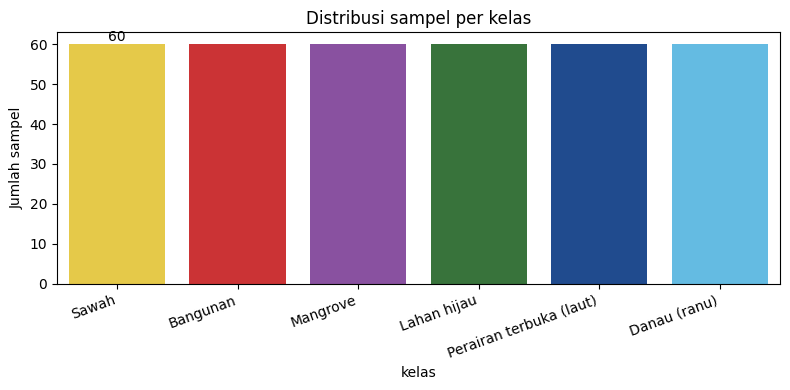

In [8]:
jml = df["kelas"].value_counts().reindex(NAMA_KELAS)
print("Jumlah kelas :", df["kelas"].nunique())
print("Jumlah data  :", len(df))
display(jml.to_frame("jumlah sampel"))

plt.figure(figsize=(8, 4))
ax = sns.barplot(x=jml.index, y=jml.values, palette=[WARNA_KELAS[k] for k in jml.index])
ax.bar_label(ax.containers[0])
plt.xticks(rotation=20, ha="right"); plt.ylabel("Jumlah sampel"); plt.title("Distribusi sampel per kelas")
plt.tight_layout(); plt.show()

## 4.2 Statistik Deskriptif Fitur
Tabel berikut menunjukkan rata-rata, simpangan baku, nilai minimum, dan maksimum seluruh fitur. Nilai rata-rata per kelas membantu melihat fitur mana yang membedakan kelas.

In [9]:
display(df[FITUR_SEMUA].describe().T.round(4))
print("\nRata-rata fitur per kelas:")
display(df.groupby("kelas")[FITUR_SEMUA].mean().reindex(NAMA_KELAS).round(3))

,count,mean,std,min,25%,50%,75%,max
B2,360.0,0.0539,0.0430,0.0107,0.0315,0.0425,0.0607,0.4528
B3,360.0,0.0708,0.0434,0.0149,0.0500,0.0628,0.0780,0.4598
B4,360.0,0.0551,0.0530,0.0050,0.0273,0.0357,0.0622,0.4692
B5,360.0,0.0882,0.0542,0.0025,0.0412,0.0903,0.1137,0.5300
B6,360.0,0.1621,0.1088,0.0001,0.0265,0.1908,0.2448,0.4929
B7,360.0,0.1887,0.1305,0.0001,0.0273,0.2180,0.2892,0.5668
B8,360.0,0.1878,0.1348,0.0001,0.0227,0.2118,0.2948,0.6100
B8A,360.0,0.2013,0.1429,0.0001,0.0228,0.2314,0.3155,0.6171
B11,360.0,0.1263,0.0983,0.0038,0.0193,0.1283,0.1834,0.5452
B12,360.0,0.0805,0.0861,0.0026,0.0139,0.0554,0.0921,0.5240



Rata-rata fitur per kelas:


,B2,B3,B4,B5,B6,B7,B8,B8A,B11,B12,NDVI,NDWI,MNDWI,NDBI,NDRE,EVI,SAVI,BSI
kelas,,,,,,,,,,,,,,,,,,
Sawah,0.054,0.073,0.061,0.104,0.196,0.230,0.226,0.247,0.161,0.090,0.555,-0.497,-0.371,-0.159,0.354,0.344,0.308,-0.113
Bangunan,0.110,0.127,0.143,0.165,0.203,0.220,0.216,0.233,0.278,0.245,0.232,-0.291,-0.400,0.126,0.141,0.144,0.133,0.129
Mangrove,0.034,0.061,0.033,0.100,0.261,0.311,0.312,0.335,0.114,0.044,0.803,-0.669,-0.300,-0.464,0.509,0.553,0.491,-0.404
Lahan hijau,0.031,0.052,0.030,0.087,0.256,0.312,0.321,0.340,0.167,0.077,0.832,-0.723,-0.535,-0.309,0.567,0.570,0.508,-0.279
Perairan terbuka (laut),0.060,0.062,0.035,0.033,0.022,0.023,0.019,0.019,0.014,0.012,-0.266,0.500,0.588,-0.177,-0.247,-0.054,-0.043,-0.244
Danau (ranu),0.034,0.051,0.029,0.039,0.034,0.036,0.033,0.034,0.023,0.014,-0.297,0.494,0.512,0.007,-0.388,-0.001,-0.006,-0.091


## 4.3 Tanda Tangan Spektral (*Spectral Signature*)
Grafik ini memperlihatkan rata-rata reflektansi tiap kelas pada tiap band. Perhatikan pola khas berikut:
* **Vegetasi (sawah, lahan hijau, mangrove):** pantulan rendah di merah (B4, klorofil menyerap), melonjak tajam di *red edge* dan NIR (B5–B8A), lalu turun di SWIR.
* **Air (laut, danau):** reflektansi rendah dan terus menurun ke arah NIR dan SWIR, karena air menyerap hampir semua energi inframerah.
* **Bangunan:** reflektansi relatif tinggi dan datar di seluruh band, dengan SWIR yang lebih tinggi dibanding vegetasi.

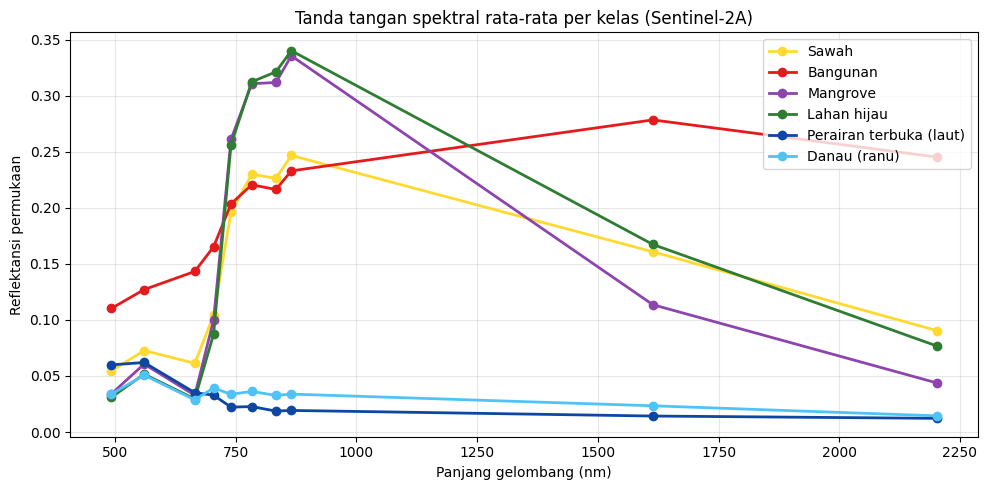

In [10]:
panjang_gelombang = [492, 560, 665, 704, 740, 783, 833, 865, 1614, 2202]
rata = df.groupby("kelas")[BAND_ASLI].mean().reindex(NAMA_KELAS)

plt.figure(figsize=(10, 5))
for k in NAMA_KELAS:
    plt.plot(panjang_gelombang, rata.loc[k].values, marker="o", lw=2, label=k, color=WARNA_KELAS[k])
plt.xlabel("Panjang gelombang (nm)"); plt.ylabel("Reflektansi permukaan")
plt.title("Tanda tangan spektral rata-rata per kelas (Sentinel-2A)")
plt.grid(alpha=.3); plt.legend(); plt.tight_layout(); plt.show()

## 4.4 Sebaran Indeks Spektral per Kelas
*Boxplot* menunjukkan seberapa baik sebuah indeks memisahkan kelas. Indeks yang kotaknya tidak saling tumpang tindih antar kelas adalah pembeda yang baik.

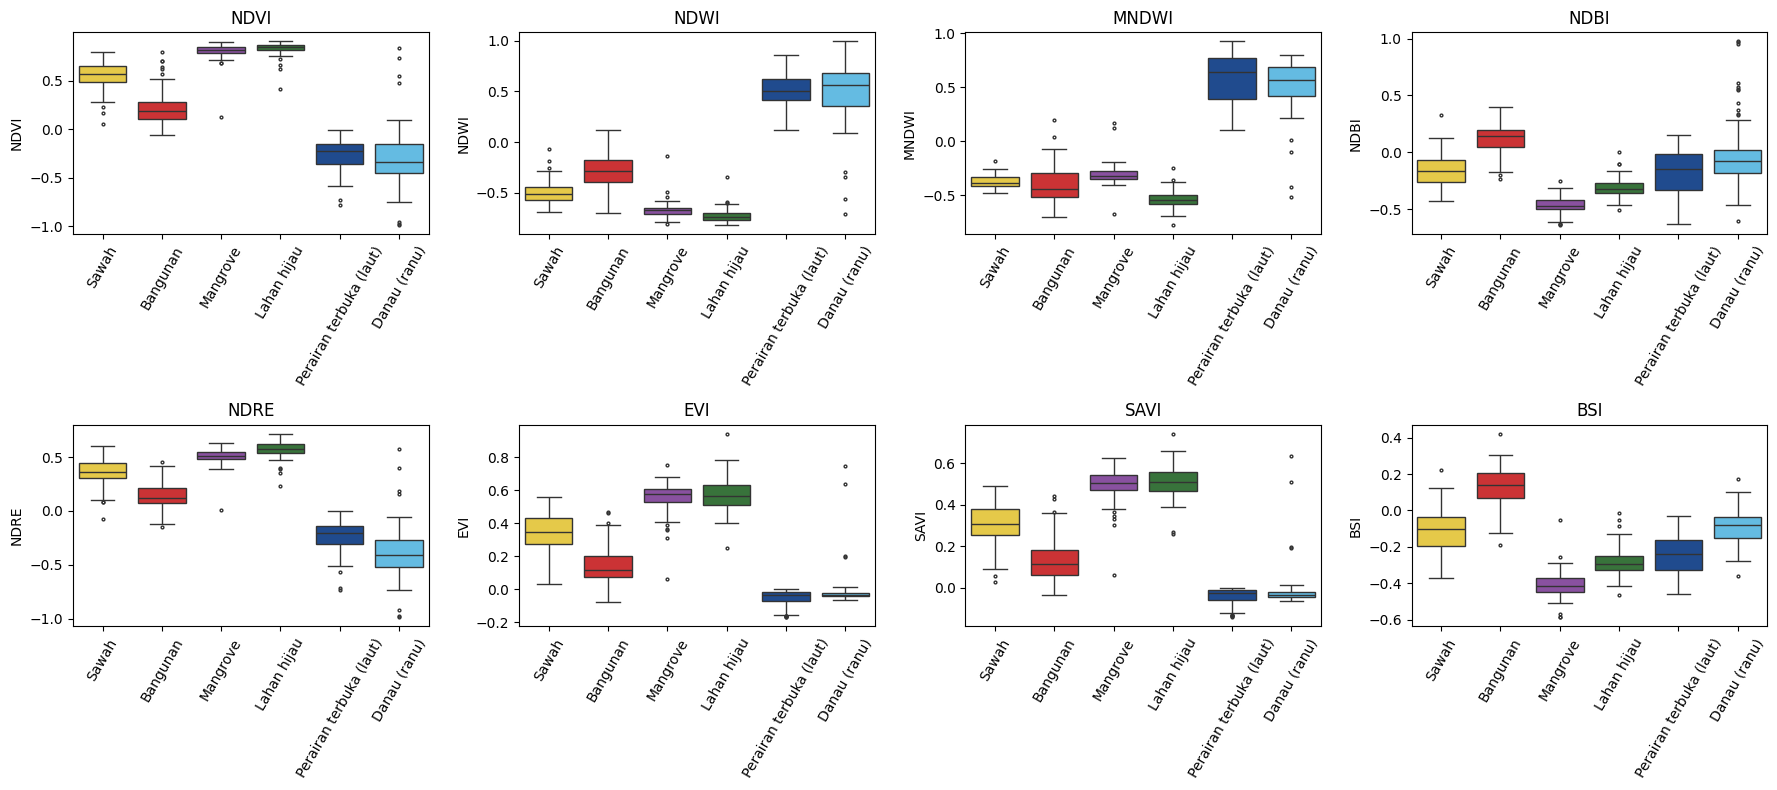

In [11]:
fig, axes = plt.subplots(2, 4, figsize=(18, 8))
for ax, f in zip(axes.ravel(), INDEKS):
    sns.boxplot(data=df, x="kelas", y=f, order=NAMA_KELAS, palette=WARNA_KELAS, ax=ax, fliersize=2)
    ax.set_title(f); ax.set_xlabel(""); ax.tick_params(axis="x", rotation=60)
plt.tight_layout(); plt.show()

## 4.5 Korelasi Antar Fitur
Berbeda dengan Naive Bayes yang menuntut asumsi independensi bersyarat (*conditional independence*), algoritma **K-Nearest Neighbors (KNN)** bekerja berdasarkan jarak multi-dimensi (seperti Euclidean atau Manhattan distance). Namun, multikolinearitas dan terutama **perbedaan skala antarfitur** sangat mempengaruhi metrik jarak pada KNN. Nilai band reflektansi berkisar antara 0.0 s.d. 0.4, sedangkan indeks spektral seperti NDVI berkisar antara -1.0 s.d. +1.0. Jika tidak dinormalisasi, fitur dengan varians atau magnitudo lebih besar akan mendominasi perhitungan jarak. Oleh karena itu, standarisasi fitur (`StandardScaler`) menjadi tahapan wajib sebelum menghitung ketetanggaan terdekat.

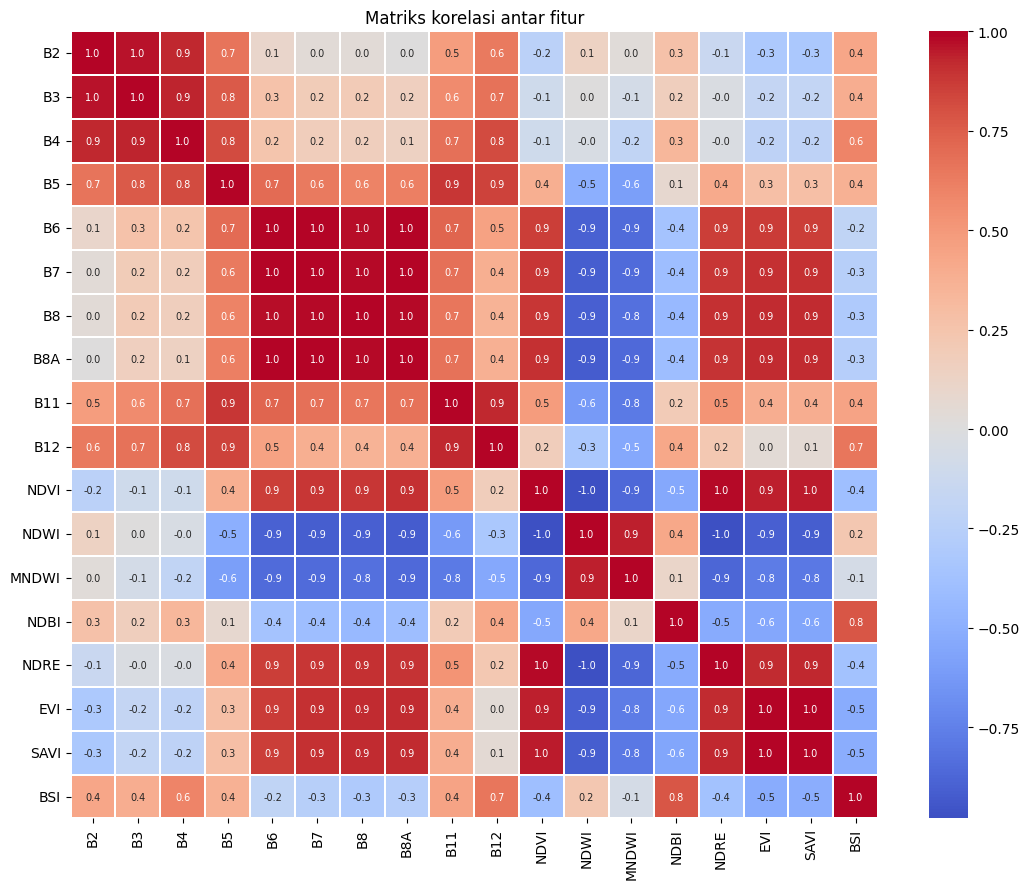

In [12]:
plt.figure(figsize=(11, 9))
sns.heatmap(df[FITUR_SEMUA].corr(), cmap="coolwarm", center=0, annot=True, fmt=".1f",
            annot_kws={"size": 7}, linewidths=.3)
plt.title("Matriks korelasi antar fitur"); plt.tight_layout(); plt.show()

# 5. Pemodelan Dasar: K-Nearest Neighbors (KNN)

## 5.1 Algoritma K-Nearest Neighbors (KNN)
**K-Nearest Neighbors (KNN)** adalah algoritma pembelajaran terbimbing non-parametrik berbasis kedekatan (*instance-based learning*). Berbeda dengan Naive Bayes yang mengasumsikan distribusi data Gaussian (kurva lonceng normal), KNN tidak membuat asumsi apriori mengenai bentuk distribusi data, sehingga sangat cocok untuk data penginderaan jauh yang sering kali multimodal atau condong (*skewed*).

Prinsip kerja KNN:
1. Menghitung jarak antara sampel uji terhadap seluruh sampel data latih dalam ruang fitur berdimensi $N$.
2. Menggunakan metrik jarak seperti:
   * **Jarak Euclidean:** $d(p, q) = \sqrt{\sum_{i=1}^n (p_i - q_i)^2}$
   * **Jarak Manhattan:** $d(p, q) = \sum_{i=1}^n |p_i - q_i|$
3. Memilih $k$ tetangga dengan jarak terpendek.
4. Menentukan kelas sampel uji melalui mayoritas suara (*majority voting*):
   * *Uniform voting*: setiap tetangga memiliki bobot suara yang sama ($1$).
   * *Distance-weighted voting*: tetangga yang lebih dekat memiliki bobot lebih besar ($w_i = 1 / d_i$), yang membuat batas keputusan lebih halus dan tahan terhadap *outlier*.

### Peran Kunci `StandardScaler`
Karena band Sentinel-2A bernilai antara $0.0 - 0.4$ sedangkan indeks spektral bernilai antara $-1.0 - +1.0$, standarisasi dengan `StandardScaler` wajib dilakukan agar semua fitur berada pada skala yang sama ($\mu=0, \sigma=1$). Hal ini mencegah fitur dengan skala lebih besar mendominasi perhitungan jarak.

## 5.2 Pembagian Data Training dan Testing
Data dibagi menjadi **80% data training** (untuk membangun model KNN) dan **20% data testing** (untuk menguji performa pada data yang belum pernah dilihat). Pembagian memakai `stratify=y` agar proporsi keenam kelas tetap sama di kedua bagian.

> KNN dipakai sebagai model dasar (*baseline*). Perbandingan dengan algoritma lain untuk mencari akurasi tertinggi ada pada bagian 6.5.

In [13]:
UKURAN_TEST = 0.20
X = df[FITUR_SEMUA]
y = df["kelas"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=UKURAN_TEST, stratify=y, random_state=SEED)

tabel_split = pd.DataFrame({
    "Total":    y.value_counts(),
    "Training": y_train.value_counts(),
    "Testing":  y_test.value_counts(),
}).reindex(NAMA_KELAS)
tabel_split.loc["TOTAL"] = tabel_split.sum()
print(f"Jumlah kelas        : {y.nunique()}")
print(f"Jumlah data training: {len(X_train)} ({len(X_train)/len(X):.0%})")
print(f"Jumlah data testing : {len(X_test)} ({len(X_test)/len(X):.0%})")
display(tabel_split.astype(int))

Jumlah kelas        : 6
Jumlah data training: 288 (80%)
Jumlah data testing : 72 (20%)


,Total,Training,Testing
kelas,,,
Sawah,60,48,12
Bangunan,60,48,12
Mangrove,60,48,12
Lahan hijau,60,48,12
Perairan terbuka (laut),60,48,12
Danau (ranu),60,48,12
TOTAL,360,288,72


### 5.2.1 Jumlah Piksel Training dan Testing

Pada notebook ini **satu sampel = satu titik = satu piksel** Sentinel-2 (nilai band dibaca tepat pada koordinat titik; piksel 10 m untuk B2, B3, B4, B8 dan 20 m untuk band lainnya). Karena itu jumlah piksel training/testing sama dengan jumlah sampel training/testing. Sel berikut menampilkan:

1. jumlah piksel **per sampel** (tiap titik/poligon): berada di *Training* atau *Testing*, beserta jumlah piksel 10 m yang sebenarnya tersedia di dalam poligon sumbernya (luas poligon ÷ 100 m²);
2. jumlah piksel **per kelas**: training, testing, dan total;
3. **seluruh jumlah piksel** training dan testing;
4. pemeriksaan kebocoran data: poligon yang sama tidak boleh menyumbang piksel ke training sekaligus testing.

**Catatan:** jumlah piksel *Training* dan *Testing* per kelas tidak harus tepat 80:20 bila `n` (target sampel) per kelas diubah. Bila Anda menaikkan `n` di atas jumlah poligon (untuk eksperimen jumlah data), titik tambahan diambil acak di dalam poligon yang sama; pada kondisi itu pembagian acak per titik dapat membocorkan piksel poligon yang sama ke dua set, dan pemeriksaan kebocoran di atas akan melaporkannya.


Estimasi jumlah piksel training dan testing berdasarkan total piksel di poligon:


,% Training,% Testing,Piksel Training (Poligon),Piksel Testing (Poligon),Piksel tersedia di poligon
Sawah,80.0,20.0,1481160.0,370290.0,1851450.0
Bangunan,80.0,20.0,229371.0,57343.0,286714.0
Mangrove,80.0,20.0,128649.0,32162.0,160811.0
Lahan hijau,80.0,20.0,4797802.0,1199450.0,5997252.0
Perairan terbuka (laut),80.0,20.0,9742478.0,2435619.0,12178097.0
Danau (ranu),80.0,20.0,194937.0,48734.0,243671.0
TOTAL,80.0,20.0,16574397.0,4143598.0,20717995.0


Seluruh piksel training (poligon): 16574397 | seluruh piksel testing (poligon): 4143598 | total: 20717995
Poligon yang muncul di training dan testing sekaligus: 0


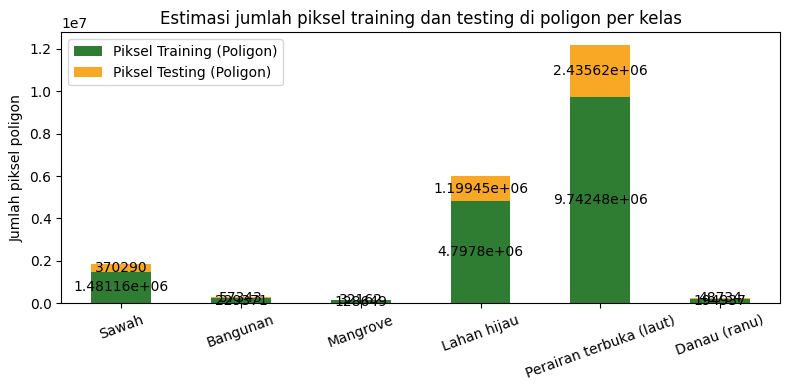

In [14]:
# ---------- Jumlah piksel Training dan Testing Berdasarkan Total Piksel Poligon ----------
df_split = df[["kelas_id", "kelas", "poligon_id", "lon", "lat"]].copy()
df_split["split"] = np.where(df_split.index.isin(X_train.index), "Training", "Testing")
df_split["jumlah_piksel"] = 1         # 1 titik sampel = 1 piksel

# Piksel 10 m yang tersedia di dalam poligon sumber
_piksel_poligon = {k: (g.to_crs(32749).area / 100).round().astype(int).to_dict() for k, g in poligon.items()}
df_split["piksel_dalam_poligon"] = [_piksel_poligon[k][p] for k, p in zip(df_split["kelas_id"], df_split["poligon_id"])]

# (1) Per sampel (disimpan ke CSV seperti sebelumnya)
tabel_per_sampel = (df_split[["kelas", "poligon_id", "split", "jumlah_piksel", "piksel_dalam_poligon"]]
                    .assign(kelas=lambda d: pd.Categorical(d["kelas"], NAMA_KELAS, ordered=True))
                    .sort_values(["kelas", "split", "poligon_id"], ascending=[True, False, True])
                    .reset_index(drop=True))
tabel_per_sampel.index += 1
tabel_per_sampel.index.name = "No"
tabel_per_sampel.to_csv(os.path.join(FOLDER_KERJA, "jumlah_piksel_per_sampel.csv"))

# (2) Hitung rasio/proporsi split dari sampel per kelas
sampel_pivot = df_split.pivot_table(index="kelas", columns="split", values="jumlah_piksel", aggfunc="sum", fill_value=0)
sampel_pivot = sampel_pivot.reindex(index=NAMA_KELAS, columns=["Training", "Testing"], fill_value=0)
sampel_pivot["Total Sampel"] = sampel_pivot["Training"] + sampel_pivot["Testing"]

# Hitung persentase/rasio dari sampel
sampel_pivot["Rasio Training"] = sampel_pivot["Training"] / sampel_pivot["Total Sampel"]
sampel_pivot["Rasio Testing"] = sampel_pivot["Testing"] / sampel_pivot["Total Sampel"]

# (3) Ambil total piksel tersedia di poligon per kelas
total_piksel_poligon_per_kelas = df_split.groupby("kelas")["piksel_dalam_poligon"].sum().reindex(NAMA_KELAS)

# (4) Buat tabel akhir berdasarkan total piksel poligon dikalikan rasio split
tabel_piksel = pd.DataFrame(index=NAMA_KELAS)
tabel_piksel["Piksel tersedia di poligon"] = total_piksel_poligon_per_kelas

tabel_piksel["Piksel Training (Poligon)"] = (tabel_piksel["Piksel tersedia di poligon"] * sampel_pivot["Rasio Training"]).round().astype(int)
tabel_piksel["Piksel Testing (Poligon)"] = (tabel_piksel["Piksel tersedia di poligon"] * sampel_pivot["Rasio Testing"]).round().astype(int)

# Total piksel gabungan (untuk perhitungan persentase di balik layar)
total_piksel_gabungan = tabel_piksel["Piksel Training (Poligon)"] + tabel_piksel["Piksel Testing (Poligon)"]

tabel_piksel["% Training"] = (100 * tabel_piksel["Piksel Training (Poligon)"] / total_piksel_gabungan).round(1)
tabel_piksel["% Testing"] = (100 * tabel_piksel["Piksel Testing (Poligon)"] / total_piksel_gabungan).round(1)

# Tambahkan baris TOTAL
tabel_piksel.loc["TOTAL"] = tabel_piksel.sum(numeric_only=True)

# Hitung ulang persentase baris TOTAL
tot_train = tabel_piksel.loc["TOTAL", "Piksel Training (Poligon)"]
tot_test = tabel_piksel.loc["TOTAL", "Piksel Testing (Poligon)"]
tot_all = tot_train + tot_test
tabel_piksel.loc["TOTAL", "% Training"] = round(100 * tot_train / tot_all, 1) if tot_all > 0 else 0
tabel_piksel.loc["TOTAL", "% Testing"] = round(100 * tot_test / tot_all, 1) if tot_all > 0 else 0

# Susun ulang urutan kolom sesuai permintaan Anda
tabel_piksel = tabel_piksel[[
    "% Training",
    "% Testing",
    "Piksel Training (Poligon)",
    "Piksel Testing (Poligon)",
    "Piksel tersedia di poligon"
]]

print("\nEstimasi jumlah piksel training dan testing berdasarkan total piksel di poligon:")
display(tabel_piksel)

N_PX_TRAIN = int(tabel_piksel.loc["TOTAL", "Piksel Training (Poligon)"])
N_PX_TEST = int(tabel_piksel.loc["TOTAL", "Piksel Testing (Poligon)"])
print(f"Seluruh piksel training (poligon): {N_PX_TRAIN} | seluruh piksel testing (poligon): {N_PX_TEST} | total: {N_PX_TRAIN + N_PX_TEST}")

# (4) Kebocoran data: poligon yang menyumbang piksel ke training DAN testing
kunci = df_split["kelas_id"].astype(str) + "-" + df_split["poligon_id"].astype(str)
bocor = set(kunci[df_split["split"] == "Training"]) & set(kunci[df_split["split"] == "Testing"])
print(f"Poligon yang muncul di training dan testing sekaligus: {len(bocor)}")
if bocor:
    print("PERINGATAN: ada poligon yang menyumbang lebih dari satu piksel dan terbagi ke dua set. "
          "Ganti pembagian data menjadi per poligon (GroupShuffleSplit) agar akurasi tidak terlalu optimistis.")

# Plot
ax = tabel_piksel.iloc[:-1][["Piksel Training (Poligon)", "Piksel Testing (Poligon)"]].plot(
    kind="bar", stacked=True, figsize=(8, 4), rot=20, color=["#2E7D32", "#F9A825"]
)
ax.bar_label(ax.containers[0], label_type="center"); ax.bar_label(ax.containers[1], label_type="center")
ax.set_ylabel("Jumlah piksel poligon"); ax.set_title("Estimasi jumlah piksel training dan testing di poligon per kelas")
plt.tight_layout(); plt.show()

In [15]:
# ---------- Tabel jumlah piksel per sampel: Training dan Testing dipisah, berdampingan, dan bisa digulir ----------
from IPython.display import HTML

def _bagian(split):
    d = (tabel_per_sampel[tabel_per_sampel["split"] == split]
         .drop(columns="split").reset_index(drop=True))
    d.index += 1
    d.index.name = "No"
    return d

def _kotak(d, judul):
    return (f'<div style="flex:1;min-width:320px"><b>{judul} ({len(d)} sampel)</b>'
            f'<div style="max-height:380px;overflow-y:auto;border:1px solid #bbb;margin-top:4px">'
            f'{d.to_html(border=0)}</div></div>')

print("Jumlah piksel per sampel (360 baris pada konfigurasi awal; berkas lengkap: jumlah_piksel_per_sampel.csv di folder kerja/Drive).")
print("Gulir tiap tabel untuk melihat seluruh baris.")
display(HTML(
    "<style>.kotak-piksel thead th{position:sticky;top:0;background:#eee;color:#000}</style>"
    '<div class="kotak-piksel" style="display:flex;gap:16px;flex-wrap:wrap">'
    + _kotak(_bagian("Training"), "Training") + _kotak(_bagian("Testing"), "Testing")
    + "</div>"))


Jumlah piksel per sampel (360 baris pada konfigurasi awal; berkas lengkap: jumlah_piksel_per_sampel.csv di folder kerja/Drive).
Gulir tiap tabel untuk melihat seluruh baris.


,kelas,poligon_id,jumlah_piksel,piksel_dalam_poligon
No,,,,
1,Sawah,1,1,41619
2,Sawah,2,1,59961
3,Sawah,3,1,51231
4,Sawah,4,1,119276
5,Sawah,5,1,52224
6,Sawah,7,1,15560
7,Sawah,8,1,44967
8,Sawah,9,1,34268
9,Sawah,10,1,45022


## 5.3 Pelatihan dan Evaluasi Model
Metrik evaluasi yang digunakan (TP = *true positive*, FP = *false positive*, FN = *false negative*):

* **Akurasi** = $\frac{\text{TP}+\text{TN}}{\text{Total}}$: proporsi prediksi yang benar secara keseluruhan.
* **Presisi** = $\frac{\text{TP}}{\text{TP}+\text{FP}}$: dari semua yang diprediksi kelas X, berapa yang benar-benar X.
* **Recall** = $\frac{\text{TP}}{\text{TP}+\text{FN}}$: dari semua yang sebenarnya kelas X, berapa yang berhasil terdeteksi.
* **F1-score** = $2 \times \frac{\text{Presisi} \times \text{Recall}}{\text{Presisi}+\text{Recall}}$: rata-rata harmonik presisi dan recall.
* **Cohen's Kappa**: mengukur kesepakatan prediksi di atas peluang acak ($>0.8$ sangat baik).
* **Confusion Matrix**: tabel silang antara kelas aktual dan prediksi untuk melihat kelas mana yang sering tertukar.

,Akurasi,Kappa,F1 macro
Dataset,,,
Training,1.0000,1.00,1.0000
Testing,0.9583,0.95,0.9577



--- Laporan Klasifikasi Data Testing (Baseline KNN k=5) ---
                         precision    recall  f1-score   support

                  Sawah       0.92      1.00      0.96        12
               Bangunan       1.00      1.00      1.00        12
               Mangrove       0.92      1.00      0.96        12
            Lahan hijau       0.91      0.83      0.87        12
Perairan terbuka (laut)       1.00      1.00      1.00        12
           Danau (ranu)       1.00      0.92      0.96        12

               accuracy                           0.96        72
              macro avg       0.96      0.96      0.96        72
           weighted avg       0.96      0.96      0.96        72



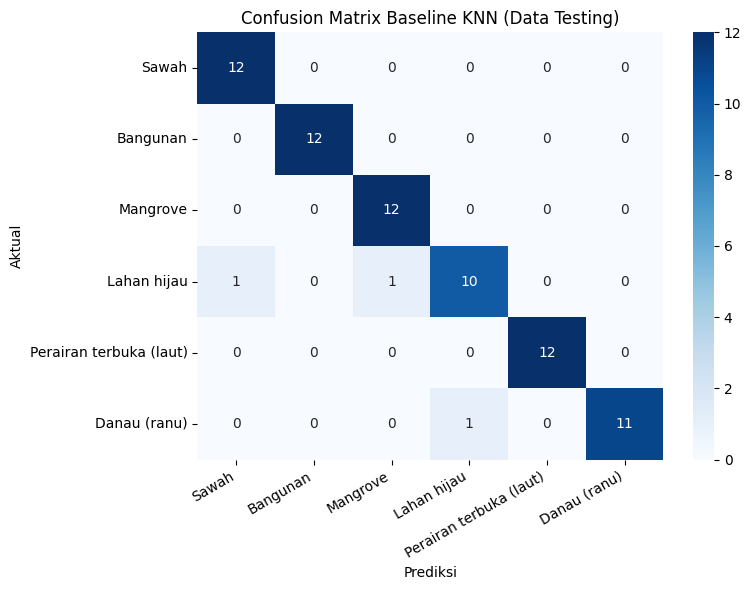

In [16]:
# Model baseline KNN (k=5, weights='distance') dengan StandardScaler
model_baseline = Pipeline([
    ("scaler", StandardScaler()),
    ("knn", KNeighborsClassifier(n_neighbors=5, weights="distance"))
])
model_baseline.fit(X_train, y_train)

pred_train = model_baseline.predict(X_train)
pred_test  = model_baseline.predict(X_test)

def metrik(y_true, y_pred):
    return {
        "Akurasi": accuracy_score(y_true, y_pred),
        "Kappa":   cohen_kappa_score(y_true, y_pred),
        "F1 macro": f1_score(y_true, y_pred, average="macro"),
    }

ringkas_eval = pd.DataFrame([
    {"Dataset": "Training", **metrik(y_train, pred_train)},
    {"Dataset": "Testing",  **metrik(y_test,  pred_test)},
]).set_index("Dataset")
display(ringkas_eval.round(4))

print("\n--- Laporan Klasifikasi Data Testing (Baseline KNN k=5) ---")
print(classification_report(y_test, pred_test, labels=NAMA_KELAS, zero_division=0))

cm = confusion_matrix(y_test, pred_test, labels=NAMA_KELAS)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=NAMA_KELAS, yticklabels=NAMA_KELAS)
plt.xlabel("Prediksi"); plt.ylabel("Aktual"); plt.title("Confusion Matrix Baseline KNN (Data Testing)")
plt.xticks(rotation=30, ha="right"); plt.tight_layout(); plt.show()

**Cara membaca hasil:** Karena KNN dengan `weights='distance'` mengukur jarak langsung ke titik latih, akurasi pada data training umumnya mencapai 100% (jarak titik ke dirinya sendiri adalah 0). Oleh karena itu, performa sejati model dinilai dari metrik **data testing** dan evaluasi **Repeated Cross-Validation**.

# 6. Eksperimen
Karena jumlah data kecil, eksperimen dievaluasi dengan **Repeated Stratified 5-Fold Cross-Validation (10 pengulangan = 50 evaluasi)** sehingga hasilnya lebih stabil daripada satu kali pembagian.

## 6.1 Eksperimen Rasio Training:Testing
Membandingkan rasio pembagian data. Setiap rasio diulang 30 kali dengan *seed* berbeda, lalu diambil rata-rata dan simpangan bakunya.

In [17]:
hasil_rasio = []
for ts in [0.10, 0.20, 0.30, 0.40]:
    skor = []
    for r in range(10):
        X_tr, X_te, y_tr, y_te = train_test_split(
            X, y, test_size=ts, stratify=y, random_state=SEED + r)
        m = Pipeline([
            ("scaler", StandardScaler()),
            ("knn", KNeighborsClassifier(n_neighbors=5, weights="distance"))
        ]).fit(X_tr, y_tr)
        skor.append(accuracy_score(y_te, m.predict(X_te)))
    hasil_rasio.append({
        "Rasio train:test": f"{int((1-ts)*100)}:{int(ts*100)}",
        "Ukuran test": ts,
        "Akurasi rata-rata": np.mean(skor),
        "Std": np.std(skor),
    })
tab_rasio = pd.DataFrame(hasil_rasio)
display(tab_rasio.round(4))

,Rasio train:test,Ukuran test,Akurasi rata-rata,Std
0,90:10,0.1,0.9389,0.0389
1,80:20,0.2,0.9389,0.0312
2,70:30,0.3,0.9296,0.0216
3,60:40,0.4,0.9250,0.0188


## 6.2 Eksperimen Kombinasi Fitur
Membandingkan apakah penambahan indeks spektral dan band Sentinel-2A meningkatkan kinerja KNN dibanding hanya memakai band mentah atau indeks saja.

In [18]:
from sklearn.model_selection import cross_validate

cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=10, random_state=SEED)

skenario_fitur = {
    "A. 4 band 10 m (B2,B3,B4,B8)":            ["B2", "B3", "B4", "B8"],
    "B. 10 band Sentinel-2A":                  BAND_ASLI,
    "C. 8 indeks spektral":                    INDEKS,
    "D. Indeks pilihan (NDVI,MNDWI,NDBI,BSI)": ["NDVI", "MNDWI", "NDBI", "BSI"],
    "E. Band + indeks (18 fitur)":             FITUR_SEMUA,
}
hasil_fitur = []
for nama, cols in skenario_fitur.items():
    pip = Pipeline([
        ("scaler", StandardScaler()),
        ("knn", KNeighborsClassifier(n_neighbors=5, weights="distance"))
    ])
    hasil_cv = cross_validate(pip, df[cols], y, cv=cv, n_jobs=-1,
                              scoring={"acc": "accuracy", "f1": "f1_macro"})
    s, f = hasil_cv["test_acc"], hasil_cv["test_f1"]
    hasil_fitur.append({"Skenario": nama, "Jumlah fitur": len(cols),
                        "Akurasi CV": s.mean(), "Std": s.std(), "F1 macro CV": f.mean()})
tab_fitur = pd.DataFrame(hasil_fitur).sort_values("Akurasi CV", ascending=False).reset_index(drop=True)
display(tab_fitur.round(4))

FITUR_FINAL_NAMA = tab_fitur.loc[0, "Skenario"]
FITUR_FINAL = skenario_fitur[FITUR_FINAL_NAMA]
print("\nSkenario fitur terbaik:", FITUR_FINAL_NAMA, f"({len(FITUR_FINAL)} fitur)")

,Skenario,Jumlah fitur,Akurasi CV,Std,F1 macro CV
0,E. Band + indeks (18 fitur),18,0.9258,0.0285,0.9267
1,B. 10 band Sentinel-2A,10,0.9200,0.0301,0.9202
2,C. 8 indeks spektral,8,0.8833,0.0344,0.8838
3,"D. Indeks pilihan (NDVI,MNDWI,NDBI,BSI)",4,0.8831,0.0344,0.8833
4,"A. 4 band 10 m (B2,B3,B4,B8)",4,0.8156,0.0407,0.8150



Skenario fitur terbaik: E. Band + indeks (18 fitur) (18 fitur)


## 6.3 Eksperimen Hyperparameter KNN (Nilai k, Bobot, dan Metrik Jarak)
Kinerja model KNN sangat dipengaruhi oleh tiga hyperparameter utama:
1. **Jumlah tetangga ($k$):** Nilai $k$ terlalu kecil (misal $k=1$) rentan terhadap *noise* dan *overfitting*, sedangkan $k$ terlalu besar menghaluskan batas keputusan (*underfitting*).
2. **Skema bobot (`weights`):** Membandingkan `'uniform'` (bobot sama) dengan `'distance'` (bobot berbanding terbalik dengan jarak).
3. **Metrik jarak (`metric`):** Membandingkan `'euclidean'` (garis lurus L2) dengan `'manhattan'` (jarak kota L1).

Hyperparameter terbaik dicari menggunakan *Grid Search* dengan validasi silang berulang (*Repeated Stratified 5-Fold CV*) pada kombinasi fitur terbaik.

,k,weights,metric,Akurasi CV,Std
0,7,distance,euclidean,0.9278,0.0286
1,3,distance,euclidean,0.9261,0.0296
2,5,distance,euclidean,0.9258,0.0285
3,3,uniform,euclidean,0.9239,0.0296
4,9,distance,euclidean,0.9233,0.0274
5,5,distance,manhattan,0.9208,0.0306
6,3,distance,manhattan,0.9197,0.0318
7,5,uniform,euclidean,0.9197,0.0297
8,7,distance,manhattan,0.9194,0.0314
9,3,uniform,manhattan,0.9189,0.0321


Hyperparameter terbaik: k=7, weights='distance', metric='euclidean' | Akurasi CV: 0.9278


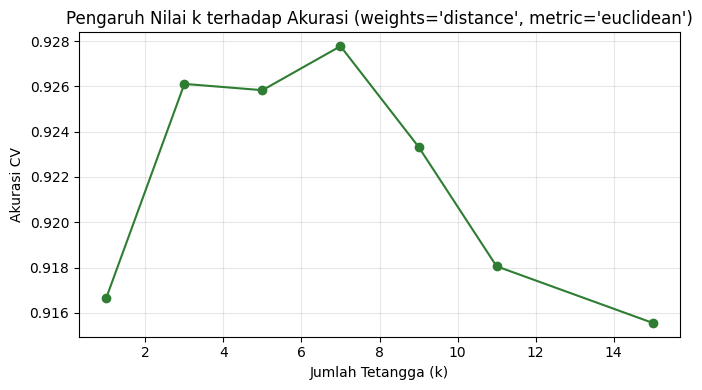

In [19]:
param_grid = {
    "knn__n_neighbors": [1, 3, 5, 7, 9, 11, 15],
    "knn__weights": ["uniform", "distance"],
    "knn__metric": ["euclidean", "manhattan"]
}
pip_grid = Pipeline([
    ("scaler", StandardScaler()),
    ("knn", KNeighborsClassifier())
])
grid = GridSearchCV(pip_grid, param_grid, cv=cv, scoring="accuracy", n_jobs=-1)
grid.fit(df[FITUR_FINAL], y)

tab_knn = pd.DataFrame(grid.cv_results_)[["param_knn__n_neighbors", "param_knn__weights", "param_knn__metric", "mean_test_score", "std_test_score"]]
tab_knn = tab_knn.rename(columns={
    "param_knn__n_neighbors": "k",
    "param_knn__weights": "weights",
    "param_knn__metric": "metric",
    "mean_test_score": "Akurasi CV",
    "std_test_score": "Std"
}).sort_values("Akurasi CV", ascending=False).reset_index(drop=True)
display(tab_knn.head(10).round(4))

BEST_K       = grid.best_params_["knn__n_neighbors"]
BEST_WEIGHTS = grid.best_params_["knn__weights"]
BEST_METRIC  = grid.best_params_["knn__metric"]
print(f"Hyperparameter terbaik: k={BEST_K}, weights='{BEST_WEIGHTS}', metric='{BEST_METRIC}' | Akurasi CV: {grid.best_score_:.4f}")

# Visualisasi pengaruh k terhadap akurasi untuk bobot dan metrik terbaik
res_df = pd.DataFrame(grid.cv_results_)
sub_res = res_df[(res_df["param_knn__weights"] == BEST_WEIGHTS) &
                 (res_df["param_knn__metric"] == BEST_METRIC)].sort_values("param_knn__n_neighbors")

plt.figure(figsize=(7, 4))
plt.plot(sub_res["param_knn__n_neighbors"].astype(int), sub_res["mean_test_score"], marker="o", color="#2E7D32")
plt.xlabel("Jumlah Tetangga (k)"); plt.ylabel("Akurasi CV"); plt.grid(alpha=0.3)
plt.title(f"Pengaruh Nilai k terhadap Akurasi (weights='{BEST_WEIGHTS}', metric='{BEST_METRIC}')")
plt.tight_layout(); plt.show()

## 6.4 Model KNN Terbaik (Hasil Grid Search)
Model KNN memakai kombinasi fitur dan hyperparameter KNN terbaik hasil eksperimen. Evaluasi akhir dilakukan pada data *testing* (pembagian 80:20 yang sama seperti bagian 5.2).

Akurasi testing model final KNN : 0.9583
Kappa                           : 0.9500
F1 macro                        : 0.9577

                         precision    recall  f1-score   support

                  Sawah       0.92      1.00      0.96        12
               Bangunan       1.00      1.00      1.00        12
               Mangrove       0.92      1.00      0.96        12
            Lahan hijau       0.91      0.83      0.87        12
Perairan terbuka (laut)       1.00      1.00      1.00        12
           Danau (ranu)       1.00      0.92      0.96        12

               accuracy                           0.96        72
              macro avg       0.96      0.96      0.96        72
           weighted avg       0.96      0.96      0.96        72



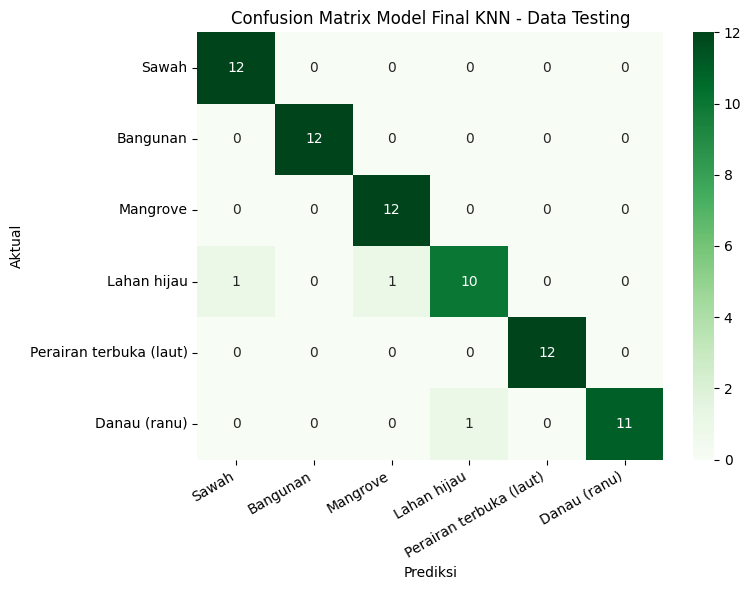

In [20]:
model_final = Pipeline([
    ("scaler", StandardScaler()),
    ("knn", KNeighborsClassifier(n_neighbors=BEST_K, weights=BEST_WEIGHTS, metric=BEST_METRIC))
]).fit(X_train[FITUR_FINAL], y_train)

pred_final = model_final.predict(X_test[FITUR_FINAL])

AKURASI_FINAL = accuracy_score(y_test, pred_final)
KAPPA_FINAL   = cohen_kappa_score(y_test, pred_final)
F1_FINAL      = f1_score(y_test, pred_final, average="macro")

print(f"Akurasi testing model final KNN : {AKURASI_FINAL:.4f}")
print(f"Kappa                           : {KAPPA_FINAL:.4f}")
print(f"F1 macro                        : {F1_FINAL:.4f}\n")
print(classification_report(y_test, pred_final, labels=NAMA_KELAS, zero_division=0))

cm = confusion_matrix(y_test, pred_final, labels=NAMA_KELAS)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Greens", xticklabels=NAMA_KELAS, yticklabels=NAMA_KELAS)
plt.xlabel("Prediksi"); plt.ylabel("Aktual"); plt.title("Confusion Matrix Model Final KNN - Data Testing")
plt.xticks(rotation=30, ha="right"); plt.tight_layout(); plt.show()

## 6.5 Perbandingan Beberapa Model Klasifikasi
Untuk memperoleh model dengan akurasi tertinggi, KNN (hasil *Grid Search*) dibandingkan dengan algoritma klasifikasi lain pada kombinasi fitur terbaik. Semua model diuji dengan **Repeated Stratified 5-Fold CV yang sama** (50 evaluasi) dan **data testing 80:20 yang sama** dengan bagian 5.2. Model terbaik dipilih berdasarkan **akurasi CV tertinggi**, karena lebih stabil daripada satu kali pembagian pada data berjumlah 360 sampel; akurasi testing dipakai sebagai pembanding dan pemutus bila nilainya sama.

| Model | Prinsip kerja |
|---|---|
| **KNN** | Kelas ditentukan dari $k$ tetangga terdekat pada ruang fitur yang distandarkan |
| **Random Forest** | Banyak pohon keputusan pada sampel acak data dan fitur; kelas akhir ditentukan suara terbanyak |
| **Extra Trees** | Mirip Random Forest, tetapi ambang pemisahan dipilih acak sehingga varians lebih rendah |
| **Hist Gradient Boosting** | Pohon dibangun berurutan, tiap pohon memperbaiki galat model sebelumnya |
| **SVM (kernel RBF)** | Batas pemisah dengan margin terbesar pada ruang fitur hasil kernel $K(x,x')=\exp(-\gamma\lVert x-x'\rVert^2)$ |
| **Naive Bayes (Gaussian)** | Klasifikasi probabilistik dengan asumsi fitur saling bebas dan berdistribusi normal |
| **XGBoost, LightGBM** | *Gradient boosting* dengan regularisasi (ikut dibandingkan bila pustakanya terpasang) |

,Model,Akurasi CV,Std CV,F1 macro CV,Akurasi Testing,Kappa Testing,F1 macro Testing,Waktu (dtk)
0,SVM (RBF),0.9364,0.0294,0.9365,0.9722,0.9667,0.9722,1.0
1,Extra Trees,0.9306,0.0298,0.9308,0.9722,0.9667,0.9722,20.5
2,KNN (hasil Grid Search),0.9278,0.0286,0.9286,0.9583,0.9500,0.9577,0.5
3,Random Forest,0.9183,0.0308,0.9181,0.9444,0.9333,0.9443,30.9
4,Hist Gradient Boosting,0.9128,0.0286,0.9124,0.9444,0.9333,0.9443,39.3
5,XGBoost,0.9114,0.0303,0.9112,0.9306,0.9167,0.9304,31.1
6,LightGBM,0.9114,0.0284,0.9110,0.9583,0.9500,0.9583,17.5
7,Naive Bayes (Gaussian),0.8039,0.0321,0.7838,0.8611,0.8333,0.8444,0.6



Model dengan akurasi CV tertinggi: SVM (RBF) (akurasi CV 0.9364, akurasi testing 0.9722)


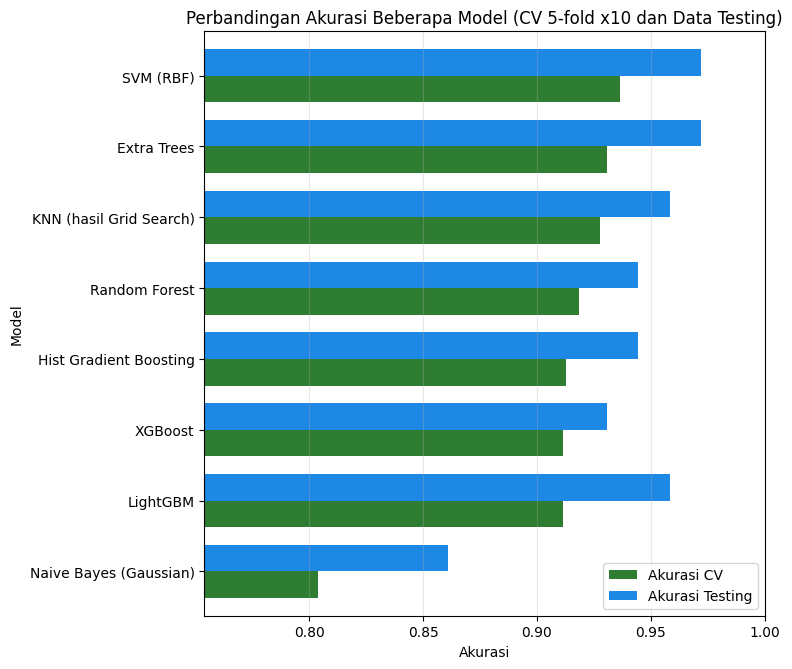

In [21]:
from sklearn.base import BaseEstimator, ClassifierMixin, clone
from sklearn.preprocessing import LabelEncoder
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier, HistGradientBoostingClassifier
from sklearn.svm import SVC
from sklearn.naive_bayes import GaussianNB

class KlasifikatorLabel(BaseEstimator, ClassifierMixin):
    """Pembungkus agar XGBoost/LightGBM dapat memakai label teks (kelas) langsung."""
    def __init__(self, estimator=None):
        self.estimator = estimator
    def fit(self, X, y):
        self.le_ = LabelEncoder().fit(y)
        self.est_ = clone(self.estimator).fit(X, self.le_.transform(y))
        self.classes_ = self.le_.classes_
        return self
    def predict(self, X):
        return self.le_.inverse_transform(self.est_.predict(X))

MODEL_KANDIDAT = {
    "KNN (hasil Grid Search)": Pipeline([("scaler", StandardScaler()),
        ("m", KNeighborsClassifier(n_neighbors=BEST_K, weights=BEST_WEIGHTS, metric=BEST_METRIC))]),
    "Random Forest":          RandomForestClassifier(n_estimators=300, random_state=SEED),
    "Extra Trees":            ExtraTreesClassifier(n_estimators=300, random_state=SEED),
    "Hist Gradient Boosting": HistGradientBoostingClassifier(max_iter=200, learning_rate=0.08, random_state=SEED),
    "SVM (RBF)":              Pipeline([("scaler", StandardScaler()), ("m", SVC(kernel="rbf", C=10, gamma="scale"))]),
    "Naive Bayes (Gaussian)": Pipeline([("scaler", StandardScaler()), ("m", GaussianNB())]),
}
try:
    from xgboost import XGBClassifier
    MODEL_KANDIDAT["XGBoost"] = KlasifikatorLabel(XGBClassifier(
        n_estimators=300, max_depth=6, learning_rate=0.08, subsample=0.9, colsample_bytree=0.9,
        random_state=SEED, eval_metric="mlogloss"))
except ImportError:
    print("xgboost tidak terpasang, dilewati")
try:
    from lightgbm import LGBMClassifier
    MODEL_KANDIDAT["LightGBM"] = KlasifikatorLabel(LGBMClassifier(
        n_estimators=300, learning_rate=0.08, random_state=SEED, verbose=-1))
except ImportError:
    print("lightgbm tidak terpasang, dilewati")

Xf_train, Xf_test, Xf_all = X_train[FITUR_FINAL], X_test[FITUR_FINAL], df[FITUR_FINAL]
baris = []
for nama, mdl in MODEL_KANDIDAT.items():
    t0 = time.time()
    cvr = cross_validate(mdl, Xf_all, y, cv=cv, n_jobs=-1, scoring={"acc": "accuracy", "f1": "f1_macro"})
    pr = clone(mdl).fit(Xf_train, y_train).predict(Xf_test)
    baris.append({"Model": nama,
                  "Akurasi CV": cvr["test_acc"].mean(), "Std CV": cvr["test_acc"].std(),
                  "F1 macro CV": cvr["test_f1"].mean(),
                  "Akurasi Testing": accuracy_score(y_test, pr), "Kappa Testing": cohen_kappa_score(y_test, pr),
                  "F1 macro Testing": f1_score(y_test, pr, average="macro"),
                  "Waktu (dtk)": round(time.time() - t0, 1)})
tab_model = (pd.DataFrame(baris).sort_values(["Akurasi CV", "Akurasi Testing"], ascending=False)
             .reset_index(drop=True))
display(tab_model.round(4))

MODEL_TERBAIK_NAMA = tab_model.loc[0, "Model"]
print(f"\nModel dengan akurasi CV tertinggi: {MODEL_TERBAIK_NAMA} "
      f"(akurasi CV {tab_model.loc[0, 'Akurasi CV']:.4f}, akurasi testing {tab_model.loc[0, 'Akurasi Testing']:.4f})")

tt = tab_model.set_index("Model")[["Akurasi CV", "Akurasi Testing"]].iloc[::-1]
ax = tt.plot.barh(figsize=(8, 0.6 * len(tt) + 2), color=["#2E7D32", "#1E88E5"], width=0.75)
ax.set_xlim(max(0, tt.min().min() - 0.05), 1.0); ax.set_xlabel("Akurasi"); ax.grid(axis="x", alpha=0.3)
ax.set_title("Perbandingan Akurasi Beberapa Model (CV 5-fold x10 dan Data Testing)")
plt.tight_layout(); plt.show()

## 6.6 Model Terbaik dan Evaluasi Akhir
Model dengan akurasi CV tertinggi pada bagian 6.5 dilatih pada data *training* (80%) dan dievaluasi pada data *testing* (20%) yang sama seperti bagian 5.2. Model yang sama kemudian dilatih ulang dengan seluruh data berlabel untuk membuat peta pada bagian 7.

Model terbaik                  : SVM (RBF)
Akurasi testing model terbaik  : 0.9722
Kappa                          : 0.9667
F1 macro                       : 0.9722

                         precision    recall  f1-score   support

                  Sawah       0.92      1.00      0.96        12
               Bangunan       1.00      1.00      1.00        12
               Mangrove       1.00      1.00      1.00        12
            Lahan hijau       0.92      0.92      0.92        12
Perairan terbuka (laut)       1.00      1.00      1.00        12
           Danau (ranu)       1.00      0.92      0.96        12

               accuracy                           0.97        72
              macro avg       0.97      0.97      0.97        72
           weighted avg       0.97      0.97      0.97        72



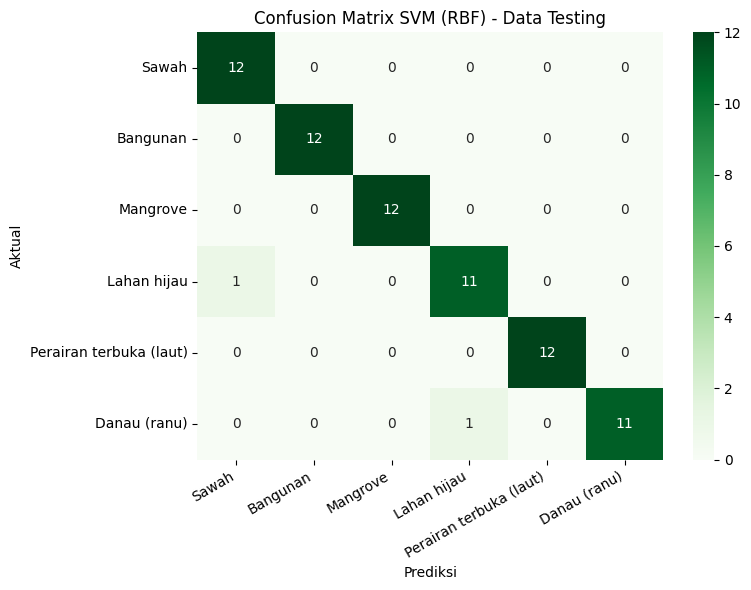

In [22]:
PIPA_TERBAIK = clone(MODEL_KANDIDAT[MODEL_TERBAIK_NAMA])
for kunci in list(PIPA_TERBAIK.get_params()):
    if kunci.endswith("n_jobs"):
        PIPA_TERBAIK.set_params(**{kunci: -1})            # percepat prediksi raster

model_final = clone(PIPA_TERBAIK).fit(Xf_train, y_train)
pred_final = model_final.predict(Xf_test)

AKURASI_FINAL = accuracy_score(y_test, pred_final)
KAPPA_FINAL   = cohen_kappa_score(y_test, pred_final)
F1_FINAL      = f1_score(y_test, pred_final, average="macro")

print(f"Model terbaik                  : {MODEL_TERBAIK_NAMA}")
print(f"Akurasi testing model terbaik  : {AKURASI_FINAL:.4f}")
print(f"Kappa                          : {KAPPA_FINAL:.4f}")
print(f"F1 macro                       : {F1_FINAL:.4f}\n")
print(classification_report(y_test, pred_final, labels=NAMA_KELAS, zero_division=0))

cm = confusion_matrix(y_test, pred_final, labels=NAMA_KELAS)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Greens", xticklabels=NAMA_KELAS, yticklabels=NAMA_KELAS)
plt.xlabel("Prediksi"); plt.ylabel("Aktual"); plt.title(f"Confusion Matrix {MODEL_TERBAIK_NAMA} - Data Testing")
plt.xticks(rotation=30, ha="right"); plt.tight_layout(); plt.show()

## 6.7 Eksperimen Jumlah Data Latih
Jumlah data tidak ditetapkan, sehingga pengaruhnya diuji lewat eksperimen: model terbaik (bagian 6.6) dilatih dengan jumlah sampel latih per kelas yang berbeda, lalu seluruhnya dinilai pada **data testing yang sama** (20% data, 12 sampel per kelas). Pada tiap jumlah, sampel latih dipilih acak dari data latih dan percobaan diulang `ULANGAN_JUMLAH` kali dengan pembagian data berbeda; nilai yang ditampilkan adalah rata-rata dan simpangan bakunya. Pembagian yang sama dipakai untuk semua jumlah pada satu pengulangan, sehingga perbandingannya berpasangan.

,Sampel latih per kelas,Total sampel latih,Akurasi,Std,F1 macro
0,6,36,0.8694,0.0784,0.8680
1,12,72,0.9278,0.0276,0.9281
2,24,144,0.9417,0.0262,0.9419
3,36,216,0.9472,0.0345,0.9476
4,48,288,0.9458,0.0274,0.9459


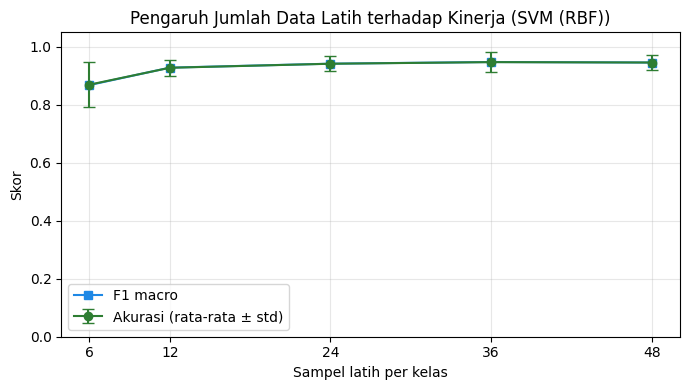


**Interpretasi:** akurasi SVM (RBF) naik dari **86.94%** pada 6 sampel latih per kelas
menjadi **94.58%** pada 48 sampel per kelas. Akurasi mencapai nilai tertinggi (selisih paling banyak
1 poin persentase) mulai **24 sampel latih per kelas**; penambahan data setelah itu memberi peningkatan yang kecil.


In [23]:
JUMLAH_LATIH   = [6, 12, 24, 36, 48]   # sampel latih per kelas (48 = seluruh data latih pada pembagian 80:20)
ULANGAN_JUMLAH = 10                      # pengulangan acak untuk tiap jumlah

MODEL_JUMLAH = MODEL_KANDIDAT[MODEL_TERBAIK_NAMA]
Xf = df[FITUR_FINAL]
baris = []
for n in JUMLAH_LATIH:
    acc, f1m = [], []
    for r in range(ULANGAN_JUMLAH):
        X_tr, X_te, y_tr, y_te = train_test_split(Xf, y, test_size=UKURAN_TEST, stratify=y, random_state=SEED + r)
        rng = np.random.default_rng(SEED + r)
        pilih = np.concatenate([
            rng.choice(np.where(y_tr.values == k)[0], size=min(n, int((y_tr.values == k).sum())), replace=False)
            for k in NAMA_KELAS])
        pred = clone(MODEL_JUMLAH).fit(X_tr.iloc[pilih], y_tr.iloc[pilih]).predict(X_te)
        acc.append(accuracy_score(y_te, pred))
        f1m.append(f1_score(y_te, pred, average="macro"))
    baris.append({"Sampel latih per kelas": n, "Total sampel latih": n * len(NAMA_KELAS),
                  "Akurasi": np.mean(acc), "Std": np.std(acc), "F1 macro": np.mean(f1m)})
tab_jumlah = pd.DataFrame(baris)
display(tab_jumlah.round(4))

fig, ax = plt.subplots(figsize=(7, 4))
ax.errorbar(tab_jumlah["Sampel latih per kelas"], tab_jumlah["Akurasi"], yerr=tab_jumlah["Std"],
            marker="o", capsize=4, color="#2E7D32", label="Akurasi (rata-rata ± std)")
ax.plot(tab_jumlah["Sampel latih per kelas"], tab_jumlah["F1 macro"], marker="s", color="#1E88E5", label="F1 macro")
ax.set_xlabel("Sampel latih per kelas"); ax.set_ylabel("Skor"); ax.set_ylim(0, 1.05)
ax.set_xticks(tab_jumlah["Sampel latih per kelas"]); ax.grid(alpha=0.3); ax.legend()
ax.set_title(f"Pengaruh Jumlah Data Latih terhadap Kinerja ({MODEL_TERBAIK_NAMA})")
plt.tight_layout(); plt.show()

# Interpretasi otomatis
akurasi_max = tab_jumlah["Akurasi"].max()
n_cukup = int(tab_jumlah.loc[tab_jumlah["Akurasi"] >= akurasi_max - 0.01, "Sampel latih per kelas"].min())
a_kecil, a_besar = tab_jumlah["Akurasi"].iloc[0], tab_jumlah["Akurasi"].iloc[-1]
display(Markdown(f"""
**Interpretasi:** akurasi {MODEL_TERBAIK_NAMA} naik dari **{a_kecil:.2%}** pada {JUMLAH_LATIH[0]} sampel latih per kelas
menjadi **{a_besar:.2%}** pada {JUMLAH_LATIH[-1]} sampel per kelas. Akurasi mencapai nilai tertinggi (selisih paling banyak
1 poin persentase) mulai **{n_cukup} sampel latih per kelas**; penambahan data setelah itu memberi peningkatan yang kecil.
"""))

# 7. Peta Hasil Klasifikasi (Model Terbaik + Folium + Google Satellite)

## 7.1 Prediksi Piksel pada Area Studi
Model terbaik (bagian 6.6) yang telah dilatih digunakan untuk memprediksi seluruh piksel citra pada Area of Interest (AOI). Karena area studi Jawa Timur luas (jutaan piksel), proses dilakukan secara bertahap per ubin (*tile*) untuk menghemat memori dan menstabilkan permintaan citra ke Planetary Computer.

## 7.0 Batas Wilayah Jawa Timur
Peta hasil klasifikasi dibatasi pada wilayah **Jawa Timur saja**, yaitu daratan provinsi (termasuk Madura dan pulau-pulau lainnya) beserta perairannya. Batas administrasi provinsi diambil dari **geoBoundaries** (lisensi CC BY 4.0). Perairan dihitung sejauh **12 mil laut (22,2 km)** dari garis pantai, sesuai kewenangan daerah provinsi di laut menurut UU No. 23 Tahun 2014. Daratan provinsi tetangga (Jawa Tengah, DI Yogyakarta, Bali) dikeluarkan dari wilayah ini, sehingga yang diklasifikasi hanyalah Jawa Timur beserta perairannya. Garis batas perairan dengan provinsi tetangga adalah pendekatan, bukan batas hukum resmi.

Bila tidak ada koneksi internet, letakkan berkas batas seluruh provinsi (GeoJSON, shapefile, atau ZIP) bernama `batas_provinsi.*` di `DATA_DIR`. Berkas harus memuat kolom nama provinsi dan polygon provinsi tetangga.

Berkas batas yang diunduh disimpan sebagai `batas_provinsi.geojson` di folder kerja (Drive), sehingga eksekusi berikutnya membacanya dari sana dan tidak mengunduh ulang.


Batas provinsi dibaca dari berkas lokal: batas_provinsi.geojson
Luas wilayah (darat + perairan 22.2 km): 98,875 km2
AOI [barat, selatan, timur, utara]: [110.691, -8.986, 116.475, -4.838]
Provinsi tetangga yang dikeluarkan: ['Bali', 'Central Java', 'South Kalimantan', 'Special Region of Yogyakarta', 'West Nusa Tenggara']


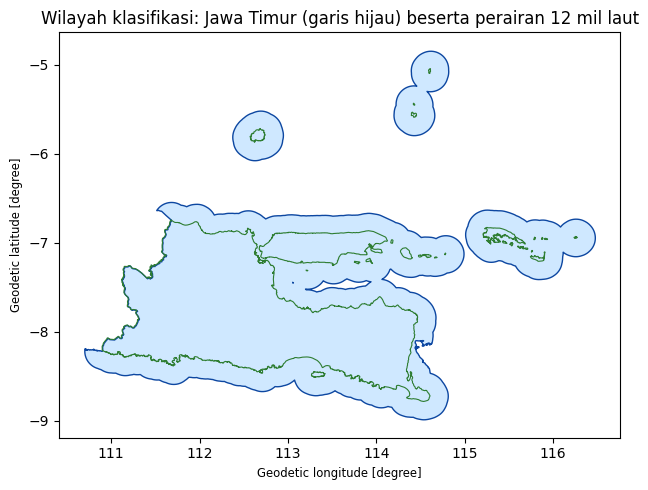

In [24]:
import io
import requests
from shapely.ops import unary_union

JARAK_LAUT_KM = 22.2          # 12 mil laut dari garis pantai
NAMA_PROVINSI = "jawatimur"   # nama provinsi (tanpa spasi, huruf kecil)
EPSG_UTM = 32749              # UTM 49S: satuan meter untuk menghitung jarak 12 mil laut

def _norm_nama(t):
    return str(t).lower().replace(" ", "").replace("_", "").replace("-", "")

def muat_batas_provinsi():
    lokal = next((p for p in Path(DATA_DIR).glob("batas_provinsi*")
                  if p.suffix.lower() in (".geojson", ".json", ".shp", ".gpkg", ".zip")), None)
    if lokal is not None:
        print("Batas provinsi dibaca dari berkas lokal:", lokal.name)
        return gpd.read_file(f"zip://{lokal}" if lokal.suffix.lower() == ".zip" else lokal)
    meta = requests.get("https://www.geoboundaries.org/api/current/gbOpen/IDN/ADM1/", timeout=60).json()
    meta = meta[0] if isinstance(meta, list) else meta
    url = meta.get("simplifiedGeometryGeoJSON") or meta["gjDownloadURL"]
    r = requests.get(url, timeout=180)
    r.raise_for_status()
    try:
        with open(os.path.join(FOLDER_KERJA, "batas_provinsi.geojson"), "wb") as f:
            f.write(r.content)                      # simpan di folder kerja (Drive) agar tidak diunduh ulang
    except Exception:
        pass
    print("Batas provinsi diunduh dari geoBoundaries dan disimpan di", FOLDER_KERJA)
    return gpd.read_file(io.BytesIO(r.content))

prov = muat_batas_provinsi()
prov = prov.set_crs(4326) if prov.crs is None else prov.to_crs(4326)
prov = prov[prov.geometry.notna() & ~prov.geometry.is_empty].copy()
prov["geometry"] = prov.geometry.buffer(0)

kolom_nama = next((c for c in ("shapeName", "NAME_1", "PROVINSI", "Provinsi", "WADMPR", "NAMOBJ", "nama", "NAME")
                   if c in prov.columns), None)
if kolom_nama is None:
    raise ValueError(f"Kolom nama provinsi tidak ditemukan. Kolom tersedia: {list(prov.columns)}")
is_jatim = prov[kolom_nama].map(_norm_nama).isin([NAMA_PROVINSI, "eastjava"])
if not is_jatim.any():
    raise ValueError(f"Provinsi Jawa Timur tidak ditemukan. Nama tersedia: {sorted(prov[kolom_nama].astype(str))}")

jatim = prov[is_jatim]
bb = jatim.total_bounds
lain = prov[~is_jatim].cx[bb[0] - 1:bb[2] + 1, bb[1] - 1:bb[3] + 1]      # provinsi tetangga di sekitar Jawa Timur

jatim_utm = unary_union(jatim.to_crs(EPSG_UTM).geometry)
zona = jatim_utm.buffer(JARAK_LAUT_KM * 1000)                            # daratan + perairan 12 mil laut
tetangga = unary_union(lain.to_crs(EPSG_UTM).geometry) if len(lain) else None
area_utm = zona.difference(tetangga) if tetangga is not None else zona
AREA_JATIM = gpd.GeoSeries([area_utm], crs=EPSG_UTM).to_crs(4326).iloc[0]

b = AREA_JATIM.bounds
AOI = [round(b[0] - 0.005, 3), round(b[1] - 0.005, 3), round(b[2] + 0.005, 3), round(b[3] + 0.005, 3)]
print(f"Luas wilayah (darat + perairan {JARAK_LAUT_KM} km): {area_utm.area / 1e6:,.0f} km2")
print(f"AOI [barat, selatan, timur, utara]: {AOI}")
print("Provinsi tetangga yang dikeluarkan:", sorted(lain[kolom_nama].astype(str)))

ax = gpd.GeoSeries([AREA_JATIM], crs=4326).plot(figsize=(9, 5), color="#cfe8ff", edgecolor="#0D47A1")
jatim.boundary.plot(ax=ax, color="#2E7D32", linewidth=0.8)
ax.set_title("Wilayah klasifikasi: Jawa Timur (garis hijau) beserta perairan 12 mil laut")
plt.tight_layout(); plt.show()

### Fungsi pengambilan komposit median untuk peta
Sel berikut mendefinisikan `ambil_median()`, yaitu fungsi yang membaca komposit median 10 band untuk satu ubin dari Planetary Computer (STAC + `odc-stac`). Langkahnya sama dengan penjelasan pada bagian 2.4: pilih scene dengan awan terendah, buang piksel awan memakai SCL, ubah DN menjadi reflektansi, lalu hitung median per band. Sel ini membutuhkan objek `katalog` dan `ASET` dari bagian 3.3. Scene dipilih **per tile MGRS** (bukan hanya yang paling bersih secara keseluruhan), sehingga seluruh ubin tertutup citra; bila masih ada piksel kosong karena awan, komposit cadangan dengan batas awan yang lebih longgar dipakai untuk mengisinya.

In [25]:
# ---------- Komposit median per ubin: Microsoft Planetary Computer ----------
import xarray as xr
import odc.stac
from odc.geo.geobox import GeoBox
import dask

# Pengaturan kecepatan (tidak mengubah hasil): bacaan citra adalah pekerjaan jaringan (I/O), sehingga
# memakai lebih banyak thread dan pengaturan GDAL yang disarankan untuk data cloud.
try:
    odc.stac.configure_rio(cloud_defaults=True, verbose=False)
except Exception:
    pass
dask.config.set(scheduler="threads", num_workers=16)

PEKERJA_UBIN    = 3     # jumlah ubin yang diproses paralel (kecil saja agar memori aman dan tidak terkena rate limit)
MAKS_SCENE_MGRS = 5     # jumlah scene paling bersih untuk SETIAP tile MGRS yang tercakup ubin (menjamin seluruh ubin tertutup)
MAX_CLOUD_CADANGAN = 70 # batas awan per scene pada komposit cadangan (mengisi piksel yang masih kosong)
MAKS_SCENE_CADANGAN = 10
AMBANG_KOSONG   = 0.02  # komposit cadangan dipakai bila > 2% piksel ubin masih kosong
SCL_PETA_BURUK  = [0, 3, 8, 9, 10, 11]   # nodata, bayangan awan, awan, cirrus, salju/es

def _tile_mgrs(item):
    t = item.properties.get("s2:mgrs_tile")
    if t:
        return str(t)
    bagian = [p for p in item.id.split("_") if len(p) == 6 and p.startswith("T")]
    return bagian[0] if bagian else "?"

def _pilih_scene(items, per_tile):
    """Ambil `per_tile` scene dengan awan terendah untuk setiap tile MGRS (bukan hanya yang terbersih secara keseluruhan)."""
    terpilih = {}
    for it in sorted(items, key=lambda i: i.properties["eo:cloud_cover"]):
        daftar = terpilih.setdefault(_tile_mgrs(it), [])
        if len(daftar) < per_tile:
            daftar.append(it)
    return [it for daftar in terpilih.values() for it in daftar]

def _komposit(bbox, ukuran, maks_cloud, per_tile):
    barat, selatan, timur, utara = bbox
    w, h = ukuran
    hasil = katalog.search(
        collections=["sentinel-2-l2a"],
        bbox=[barat, selatan, timur, utara],
        datetime=f"{TANGGAL_MULAI}/{TANGGAL_AKHIR}",
        query={"eo:cloud_cover": {"lt": maks_cloud}})
    items = list(hasil.items())
    if HANYA_SENTINEL_2A:
        items = [i for i in items if i.id.startswith("S2A")]
    if not items:
        return np.full((h, w, len(BAND_ASLI)), np.nan, dtype=np.float32)
    items = _pilih_scene(items, per_tile)

    gbox = GeoBox.from_bbox((barat, selatan, timur, utara), "EPSG:4326", shape=(h, w))
    nama_aset = list(ASET.values())
    resampling = {a: "bilinear" for a in nama_aset}
    resampling["SCL"] = "nearest"
    ds = odc.stac.load(items, bands=nama_aset + ["SCL"], geobox=gbox,
                       groupby="solar_day", chunks={"x": 512, "y": 512},
                       resampling=resampling)

    buruk = ds["SCL"].isin(SCL_PETA_BURUK)
    lapisan = []
    for a in nama_aset:
        x = ds[a].astype("float32")
        x = x.where(x > 0)                 # DN 0 = nodata
        x = x * 1e-4 - 0.1                 # DN -> reflektansi (scale 0,0001 dan offset -0,1)
        x = x.where(~buruk)                # buang piksel awan/bayangan
        lapisan.append(x.median("time", skipna=True))
    arr = xr.concat(lapisan, dim="band").compute().values      # (10, tinggi, lebar)
    return np.moveaxis(arr, 0, -1).astype(np.float32)          # (tinggi, lebar, 10)

def ambil_median(bbox, ukuran):
    """Komposit median 10 band untuk satu ubin.
    bbox   = (barat, selatan, timur, utara) dalam derajat (EPSG:4326)
    ukuran = (lebar, tinggi) dalam piksel
    Hasil  : array float32 (tinggi, lebar, 10); NaN bila tidak ada piksel bersih.
    Langkah 1: scene bersih per tile MGRS (MAX_CLOUD). Langkah 2 (bila masih ada piksel kosong):
    komposit cadangan dengan batas awan lebih longgar hanya untuk mengisi piksel yang kosong."""
    arr = _komposit(bbox, ukuran, MAX_CLOUD, MAKS_SCENE_MGRS)
    kosong = np.isnan(arr[..., 0])
    if kosong.mean() > AMBANG_KOSONG:
        cadangan = _komposit(bbox, ukuran, MAX_CLOUD_CADANGAN, MAKS_SCENE_CADANGAN)
        isi = kosong & ~np.isnan(cadangan[..., 0])
        arr[isi] = cadangan[isi]
    return arr


In [26]:
from concurrent.futures import ThreadPoolExecutor, as_completed
from rasterio import features
from rasterio.transform import from_origin

import os

# AOI dan batas wilayah Jawa Timur (AREA_JATIM) ditentukan pada bagian 7.0
SKALA_PETA  = 120                             # resolusi piksel (meter)
TILE_PX     = 500                             # ukuran ubin (piksel) per permintaan
ULANGI_PETA = False                           # True: abaikan hasil lama dan hitung ulang semua ubin
SUMBER_PETA = "planetary_computer_v3"            # penanda sumber citra; hasil lama dari sumber lain tidak dilanjutkan
# Tanda model dan data: hasil lama hanya dilanjutkan bila model, fitur, dan data latih sama
TANDA_PETA  = f"{MODEL_TERBAIK_NAMA}|{','.join(FITUR_FINAL)}|{len(df)}|{float(df[FITUR_FINAL].to_numpy().sum()):.4f}"
FILE_PETA   = os.path.join(FOLDER_KERJA, "label_peta.npz")

# Latih ulang model terbaik (bagian 6.5) dengan seluruh data berlabel
model_peta = clone(PIPA_TERBAIK).fit(df[FITUR_FINAL], df["kelas"])

def hex_ke_rgb(h):
    h = h.lstrip("#"); return [int(h[i:i+2], 16) for i in (0, 2, 4)]

def klasifikasi_aoi(aoi, skala, tile_px, model, fitur):
    """Mengklasifikasi AOI per ubin. Ubin diunduh paralel; ubin yang sudah terisi dilewati (smart resume)."""
    barat, selatan, timur, utara = aoi
    dx = skala / 111320.0                                  # meter -> derajat
    W = int(math.ceil((timur - barat) / dx))
    H = int(math.ceil((utara - selatan) / dx))
    n_tile = math.ceil(H / tile_px) * math.ceil(W / tile_px)
    print(f"Raster {W} x {H} piksel ({W*H:,} piksel), dibagi menjadi {n_tile} ubin")

    kode = {nama: i for i, nama in enumerate(NAMA_KELAS)}
    # Mask wilayah Jawa Timur (darat + perairan): piksel di luar wilayah tidak diklasifikasi
    mask = features.rasterize([(AREA_JATIM, 1)], out_shape=(H, W), transform=from_origin(barat, utara, dx, dx),
                              fill=0, dtype="uint8").astype(bool)
    batas = [[utara - H*dx, barat], [utara, barat + W*dx]]  # [[selatan, barat], [utara, timur]]

    # Lanjutkan hasil sebagian sebelumnya bila ada (hanya bila berasal dari Planetary Computer)
    label = np.full((H, W), -1, dtype=np.int8)
    if os.path.exists(FILE_PETA) and not ULANGI_PETA:
        try:
            z_lama = np.load(FILE_PETA, allow_pickle=True)
            sumber_lama = str(z_lama["sumber"]) if "sumber" in z_lama.files else ""
            tanda_lama = str(z_lama["tanda"]) if "tanda" in z_lama.files else ""
            if sumber_lama != SUMBER_PETA or tanda_lama != TANDA_PETA:
                print("Berkas peta lama dibuat dengan sumber, model, atau data yang berbeda; diabaikan dan dihitung ulang dari awal.")
            elif z_lama["label"].shape == (H, W):
                label = z_lama["label"].copy()
                print(f"Melanjutkan raster yang sudah ada ({np.sum(label != -1) / (H*W):.1%} piksel sudah terisi)")
        except Exception:
            pass
    label[~mask] = -1

    def simpan():
        np.savez_compressed(FILE_PETA, label=label, batas=np.array(batas), aoi=np.array(AOI),
                            skala=SKALA_PETA, fitur=np.array(FITUR_FINAL), sumber=SUMBER_PETA, tanda=TANDA_PETA)

    # Daftar ubin yang masih perlu dikerjakan (ubin yang >90% wilayahnya sudah terisi dilewati)
    tugas, n = [], 0
    for r0 in range(0, H, tile_px):
        for c0 in range(0, W, tile_px):
            n += 1
            r1, c1 = min(r0 + tile_px, H), min(c0 + tile_px, W)
            m_ubin = mask[r0:r1, c0:c1]
            if not m_ubin.any():
                continue                                    # ubin di luar wilayah Jawa Timur
            if np.mean(label[r0:r1, c0:c1][m_ubin] != -1) <= 0.9:
                tugas.append((n, r0, r1, c0, c1))
    print(f"Ubin diproses: {len(tugas)} dari {n_tile} (sisanya di luar Jawa Timur atau sudah ada)")

    def unduh_ubin(t):
        nomor, r0, r1, c0, c1 = t
        bbox = (barat + c0*dx, utara - r1*dx, barat + c1*dx, utara - r0*dx)   # (barat, selatan, timur, utara)
        for percobaan in range(3):
            try:
                return t, ambil_median(bbox, (c1 - c0, r1 - r0)), None
            except Exception as e:
                msg = f"{type(e).__name__}: {e}"
                if percobaan == 2:
                    return t, None, msg
                time.sleep(10)

    gagal, selesai = [], 0
    if tugas:
        with ThreadPoolExecutor(max_workers=PEKERJA_UBIN) as ex:
            futures = [ex.submit(unduh_ubin, t) for t in tugas]
            for fu in as_completed(futures):
                (nomor, r0, r1, c0, c1), arr, msg = fu.result()
                selesai += 1
                print(f"\rUbin selesai {selesai}/{len(tugas)}                    ", end="")
                if arr is None:
                    gagal.append((r0, c0, msg))
                    print(f"\n[Galat Ubin {nomor}]: {msg[:250]}")
                    continue
                h, w = arr.shape[:2]
                d = tambah_indeks(pd.DataFrame(arr.reshape(-1, len(BAND_ASLI)), columns=BAND_ASLI))
                d = d.replace([np.inf, -np.inf], np.nan)
                valid = d[FITUR_SEMUA].notna().all(axis=1).values
                if valid.any():
                    pred = model.predict(d.loc[valid, fitur])
                    kk = np.full(h * w, -1, dtype=np.int8)
                    kk[valid] = [kode[p] for p in pred]
                    kk = kk.reshape(h, w)
                    kk[~mask[r0:r0+h, c0:c0+w]] = -1         # buang piksel di luar wilayah
                    label[r0:r0+h, c0:c0+w] = kk
                if selesai % 4 == 0:
                    simpan()                                # simpan progres agar aman bila terputus
        simpan()

    print()
    if gagal:
        print(f"PERINGATAN: {len(gagal)} ubin gagal diunduh.\nContoh galat:\n{gagal[0][2]}")
    return label, batas

# Jalankan klasifikasi dan lengkapi ubin yang tersisa
label_peta, batas_peta = klasifikasi_aoi(AOI, SKALA_PETA, TILE_PX, model_peta, FITUR_FINAL)
np.savez_compressed(FILE_PETA, label=label_peta, batas=np.array(batas_peta), aoi=np.array(AOI),
                    skala=SKALA_PETA, fitur=np.array(FITUR_FINAL), sumber=SUMBER_PETA, tanda=TANDA_PETA)
print("Ukuran raster hasil:", label_peta.shape)


Raster 5366 x 3848 piksel (20,648,368 piksel), dibagi menjadi 88 ubin
Melanjutkan raster yang sudah ada (33.7% piksel sudah terisi)
Ubin diproses: 0 dari 88 (sisanya di luar Jawa Timur atau sudah ada)

Ukuran raster hasil: (3848, 5366)


### Pengisian Celah Kecil dan Pemeriksaan Cakupan
Piksel yang tetap kosong di dalam wilayah Jawa Timur (misalnya tertutup awan sepanjang periode) diisi dengan kelas piksel terklasifikasi **terdekat**, tetapi hanya bila jaraknya tidak lebih dari `ISI_MAKS_PX` piksel (sekitar 1 km pada resolusi 120 m). Celah yang lebih luas tidak diisi dan dilaporkan sebagai ubin dengan cakupan rendah; jalankan ulang sel prediksi di atas untuk mengulang ubin tersebut.

In [27]:
from scipy import ndimage as ndi

ISI_MAKS_PX = 8        # celah selebar-lebarnya ~8 piksel (~1 km) diisi kelas terdekat

H, W = label_peta.shape
dx_ = SKALA_PETA / 111320.0
mask_peta = features.rasterize([(AREA_JATIM, 1)], out_shape=(H, W),
                               transform=from_origin(AOI[0], AOI[3], dx_, dx_), fill=0, dtype="uint8").astype(bool)

cakupan_awal = ((label_peta >= 0) & mask_peta).sum() / mask_peta.sum()
kosong = (label_peta < 0) & mask_peta
if kosong.any():
    jarak, (ir, ic) = ndi.distance_transform_edt(label_peta < 0, return_indices=True)
    isi = kosong & (jarak <= ISI_MAKS_PX)
    label_peta = label_peta.copy()
    label_peta[isi] = label_peta[ir[isi], ic[isi]]
    del jarak, ir, ic
cakupan_akhir = ((label_peta >= 0) & mask_peta).sum() / mask_peta.sum()
print(f"Cakupan wilayah Jawa Timur terklasifikasi: {cakupan_awal:.2%} -> {cakupan_akhir:.2%} setelah pengisian celah kecil")

# Ubin dengan cakupan rendah (bila ada)
rendah = []
for r0 in range(0, H, TILE_PX):
    for c0 in range(0, W, TILE_PX):
        m_ubin = mask_peta[r0:r0+TILE_PX, c0:c0+TILE_PX]
        if m_ubin.any():
            frak = (label_peta[r0:r0+TILE_PX, c0:c0+TILE_PX][m_ubin] >= 0).mean()
            if frak < 0.98:
                rendah.append((r0 // TILE_PX, c0 // TILE_PX, round(float(frak), 3)))
if rendah:
    print("Ubin (baris, kolom, cakupan) yang masih berlubang:", rendah)
    print("Jalankan ulang sel prediksi di atas untuk mengulang ubin tersebut.")
else:
    print("Semua ubin di dalam wilayah Jawa Timur terisi.")

np.savez_compressed(FILE_PETA, label=label_peta, batas=np.array(batas_peta), aoi=np.array(AOI),
                    skala=SKALA_PETA, fitur=np.array(FITUR_FINAL), sumber=SUMBER_PETA, tanda=TANDA_PETA)

Cakupan wilayah Jawa Timur terklasifikasi: 100.00% -> 100.00% setelah pengisian celah kecil
Semua ubin di dalam wilayah Jawa Timur terisi.


## 7.1.1 Koreksi Konteks Spasial (Post-processing)

Hasil klasifikasi per piksel hanya melihat nilai spektral, sedangkan **laut dan danau sama-sama air** sehingga mudah tertukar. Pada eksekusi sebelumnya kelas Danau menempati sekitar 6% area kajian (kira-kira 6.400 km²), padahal danau/waduk di Jawa Timur luasnya jauh lebih kecil; ini tanda kuat bahwa sebagian perairan laut atau pesisir terklasifikasi sebagai danau.

Koreksi memakai data bantu batas daratan Jawa Timur (geoBoundaries, bagian 7.0) dengan tiga aturan sederhana:

1. piksel **Danau** yang berada lebih jauh dari `TOLERANSI_PANTAI_KM` **di luar** daratan diubah menjadi **Perairan terbuka (laut)**;
2. piksel **Laut** yang berada lebih jauh dari `TOLERANSI_PANTAI_KM` **di dalam** daratan diubah menjadi **Danau (ranu)**;
3. piksel **Sawah, Bangunan, Mangrove, dan Lahan hijau** yang berada lebih jauh dari `TOLERANSI_DARAT_KM` (bawaan 2 km) **di luar** daratan diubah menjadi **Perairan terbuka (laut)**, karena kelas-kelas tersebut tidak mungkin berada di tengah laut (misalnya piksel "Bangunan" akibat pantulan sunglint atau tepi sapuan citra).

Toleransi diperlukan karena batas geoBoundaries versi sederhana tidak mengikuti garis pantai secara presisi. Hasil sebelum dan sesudah koreksi dibandingkan pada tabel. Aturan ini adalah asumsi geografis, bukan hasil model; nonaktifkan dengan `TERAPKAN_KOREKSI_SPASIAL = False` bila tidak diinginkan. Perairan pesisir dangkal/tambak yang berada dalam toleransi atau di daratan tidak tersentuh aturan ini.

In [28]:
from scipy import ndimage as ndi

TERAPKAN_KOREKSI_SPASIAL = True
TOLERANSI_PANTAI_KM = 1.0   # batas untuk aturan Danau <-> Laut
TOLERANSI_DARAT_KM  = 2.0   # batas jarak (km) di luar daratan; kelas darat melewati batas ini diubah menjadi Laut (ubah sesuai kebutuhan)

IDX_LAUT, IDX_DANAU = NAMA_KELAS.index("Perairan terbuka (laut)"), NAMA_KELAS.index("Danau (ranu)")
IDX_DARAT = [NAMA_KELAS.index(n) for n in ("Sawah", "Bangunan", "Mangrove", "Lahan hijau")]
if "label_peta_mentah" in globals():
    label_peta = label_peta_mentah.copy()      # sel ini dijalankan ulang: mulai lagi dari hasil mentah
else:
    label_peta_mentah = label_peta.copy()
_Hc, _Wc = label_peta.shape
_ha_piksel = SKALA_PETA ** 2 * math.cos(math.radians((AOI[1] + AOI[3]) / 2)) / 10_000

def _luas_per_kelas(lbl):
    n = np.bincount(lbl[lbl >= 0].astype(int), minlength=len(NAMA_KELAS))
    return pd.Series(n * _ha_piksel, index=NAMA_KELAS)

if TERAPKAN_KOREKSI_SPASIAL:
    _dx = SKALA_PETA / 111320.0
    darat = features.rasterize([(g, 1) for g in jatim.geometry], out_shape=(_Hc, _Wc),
                               transform=from_origin(AOI[0], AOI[3], _dx, _dx), fill=0, dtype="uint8").astype(bool)
    px_tol = TOLERANSI_PANTAI_KM * 1000 / SKALA_PETA
    jarak_luar = ndi.distance_transform_edt(~darat)               # jarak (piksel) ke daratan untuk piksel di luar daratan
    px_darat = TOLERANSI_DARAT_KM * 1000 / SKALA_PETA
    danau_di_laut = (label_peta == IDX_DANAU) & (jarak_luar > px_tol)
    darat_di_laut = np.isin(label_peta, IDX_DARAT) & (jarak_luar > px_darat)
    laut_di_darat = (label_peta == IDX_LAUT) & (ndi.distance_transform_edt(darat) > px_tol)
    label_peta[danau_di_laut] = IDX_LAUT
    label_peta[darat_di_laut] = IDX_LAUT
    label_peta[laut_di_darat] = IDX_DANAU
    print(f"Piksel Danau -> Laut (danau di luar daratan): {int(danau_di_laut.sum()):,}")
    print(f"Piksel Sawah/Bangunan/Mangrove/Lahan hijau -> Laut (> {TOLERANSI_DARAT_KM:g} km di luar daratan): {int(darat_di_laut.sum()):,}")
    print(f"Piksel Laut -> Danau (laut di dalam daratan): {int(laut_di_darat.sum()):,}")
    del darat, jarak_luar, danau_di_laut, darat_di_laut, laut_di_darat

banding = pd.DataFrame({"Luas sebelum (ha)": _luas_per_kelas(label_peta_mentah),
                        "Luas sesudah (ha)": _luas_per_kelas(label_peta)}).round(1)
banding["Selisih (ha)"] = (banding["Luas sesudah (ha)"] - banding["Luas sebelum (ha)"]).round(1)
display(banding)

Piksel Danau -> Laut (danau di luar daratan): 68,571
Piksel Sawah/Bangunan/Mangrove/Lahan hijau -> Laut (> 2 km di luar daratan): 140,365
Piksel Laut -> Danau (laut di dalam daratan): 1,495


,Luas sebelum (ha),Luas sesudah (ha),Selisih (ha)
Sawah,1424195.0,1423358.7,-836.3
Bangunan,994988.8,797445.7,-197543.1
Mangrove,65904.4,63994.5,-1909.9
Lahan hijau,2506015.1,2505647.7,-367.4
Perairan terbuka (laut),4741555.2,5038099.2,296544.0
Danau (ranu),220580.0,124692.6,-95887.4


In [29]:
# Ubah kode kelas -> gambar RGBA (piksel tanpa data/awan dibuat transparan)
H, W = label_peta.shape
rgba = np.zeros((H, W, 4), dtype=np.uint8)
for idx, nama in enumerate(NAMA_KELAS):
    rgba[label_peta == idx] = hex_ke_rgb(WARNA_KELAS[nama]) + [255]

# Statistik luas hasil klasifikasi pada AOI
lat_tengah = (AOI[1] + AOI[3]) / 2
luas_piksel_ha = (SKALA_PETA * SKALA_PETA * math.cos(math.radians(lat_tengah))) / 10_000
jumlah = np.bincount(label_peta[label_peta >= 0].astype(int), minlength=len(NAMA_KELAS))
tab_luas = pd.DataFrame({"Jumlah piksel": jumlah}, index=NAMA_KELAS)
tab_luas["Luas (ha)"] = (tab_luas["Jumlah piksel"] * luas_piksel_ha).round(1)
tab_luas["Persentase (%)"] = (100 * tab_luas["Jumlah piksel"] / max(tab_luas["Jumlah piksel"].sum(), 1)).round(2)
print(f"Piksel tanpa data: {(label_peta < 0).sum():,} dari {label_peta.size:,}")
display(tab_luas)

Piksel tanpa data: 13,685,794 dari 20,648,368


,Jumlah piksel,Luas (ha),Persentase (%)
Sawah,995680,1423358.7,14.30
Bangunan,557836,797445.7,8.01
Mangrove,44766,63994.5,0.64
Lahan hijau,1752772,2505647.7,25.17
Perairan terbuka (laut),3524294,5038099.2,50.62
Danau (ranu),87226,124692.6,1.25


## 7.2 Peta Interaktif Folium dengan Latar Google Satellite
Peta memakai **tile Google Maps Satellite** sebagai peta dasar (`lyrs=s`; tersedia juga *Hybrid* `lyrs=y` yang menambah label jalan dan tempat). Hasil klasifikasi seluruh Jawa Timur ditumpuk di atasnya, dan **setiap kelas menjadi satu lapisan sendiri** (sawah, bangunan, mangrove, lahan hijau, perairan terbuka/laut, danau). Tiap lapisan dapat dihidupkan atau dimatikan lewat kotak centang di pojok kanan atas, sekaligus berfungsi sebagai legenda warna. Sebaran titik sampel ditampilkan terpisah pada bagian 2.3.1.

Peta disimpan: /content/drive/MyDrive/klasifikasi_jatim/hasil_klasifikasi_jatim.html (dapat ditanam di web statis lewat <iframe>)



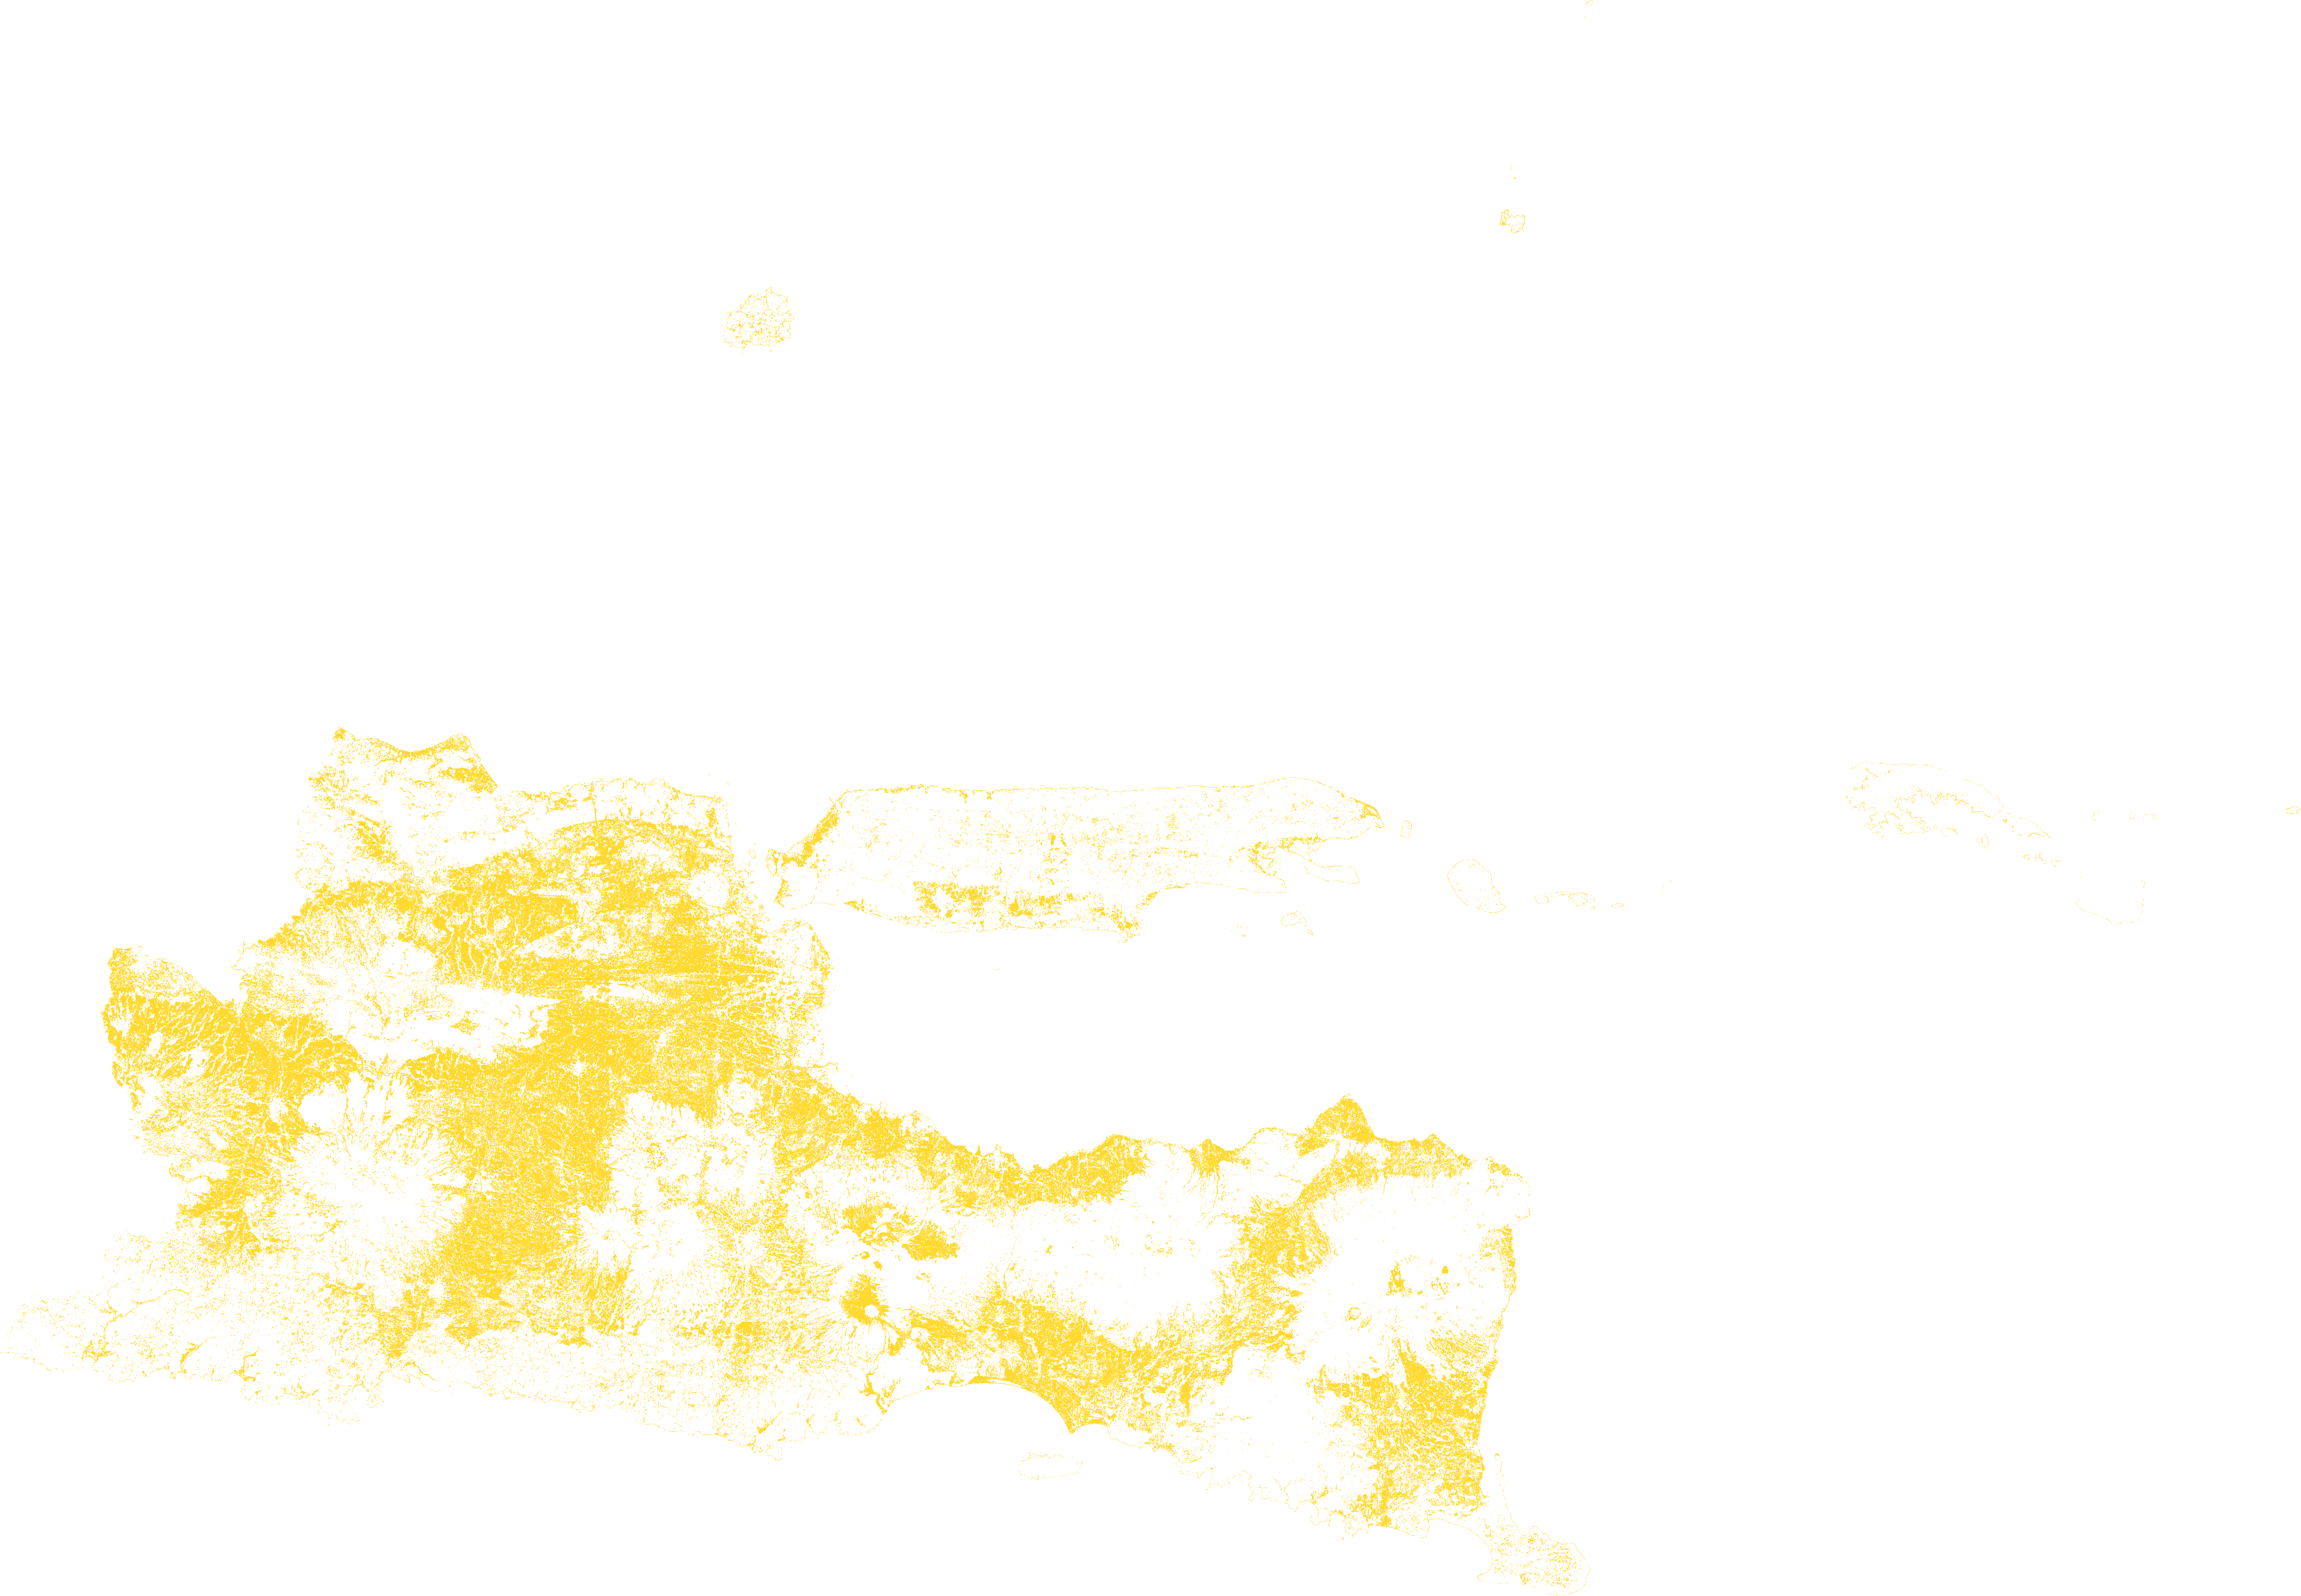
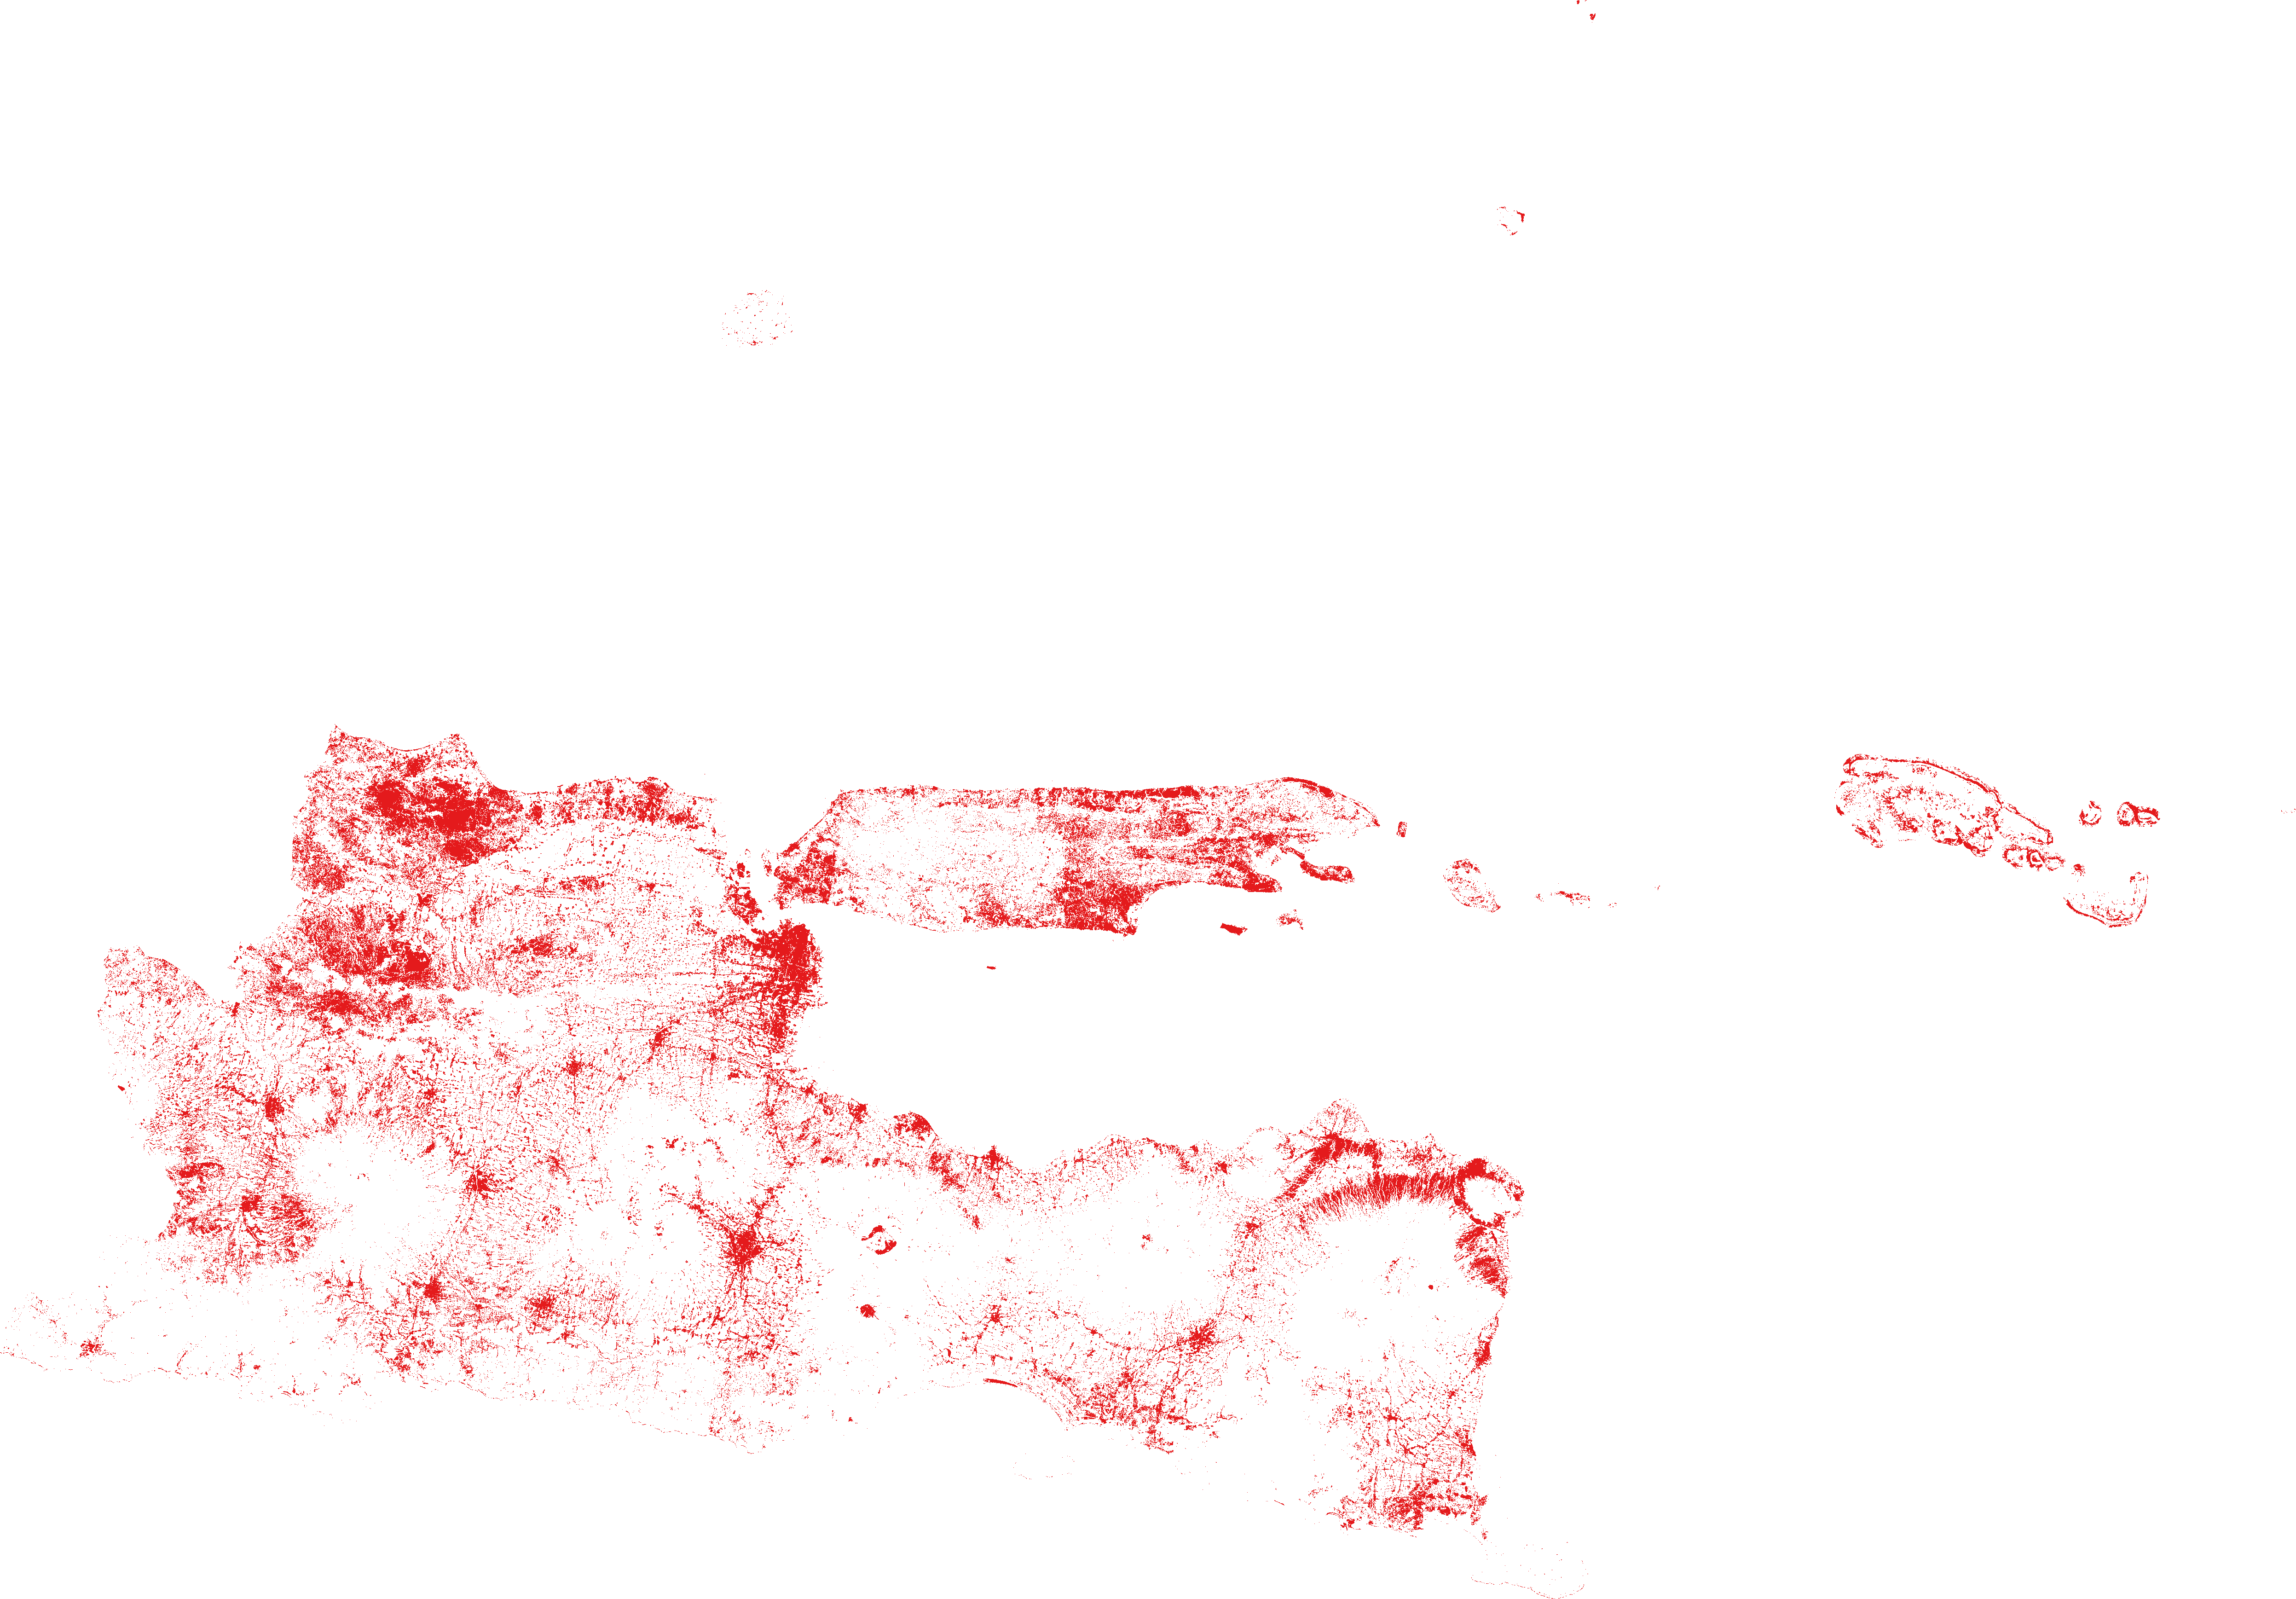
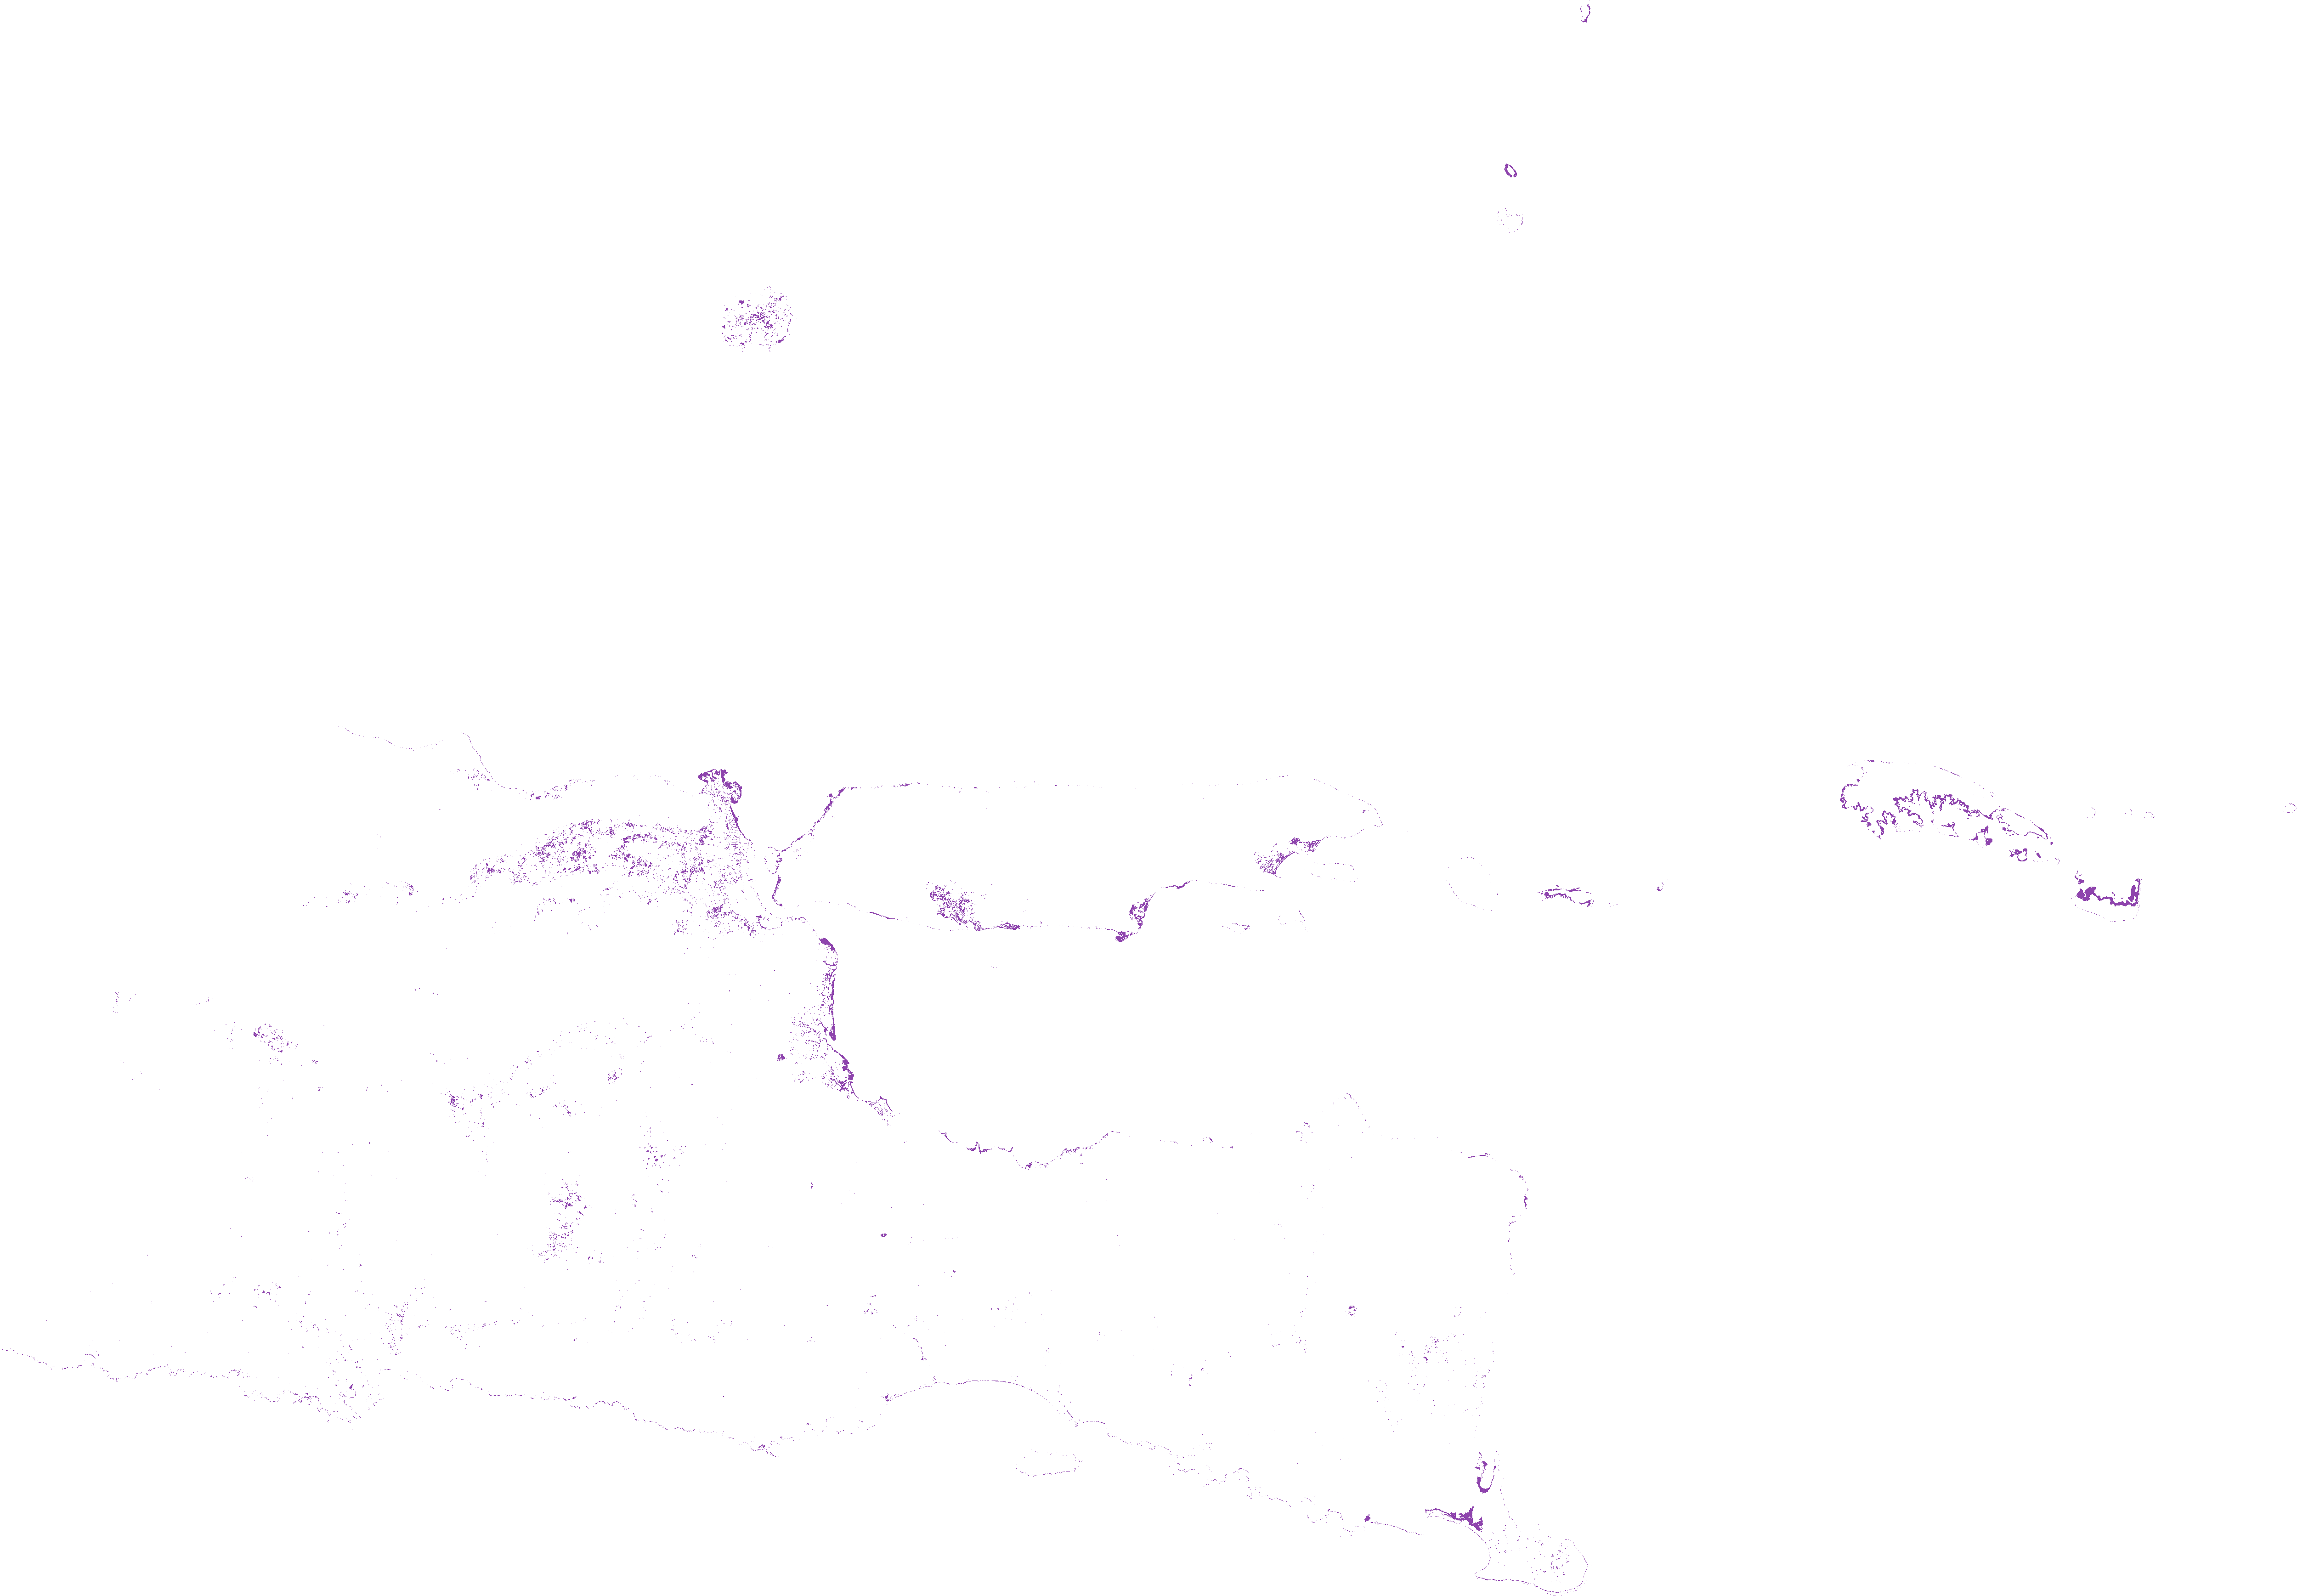
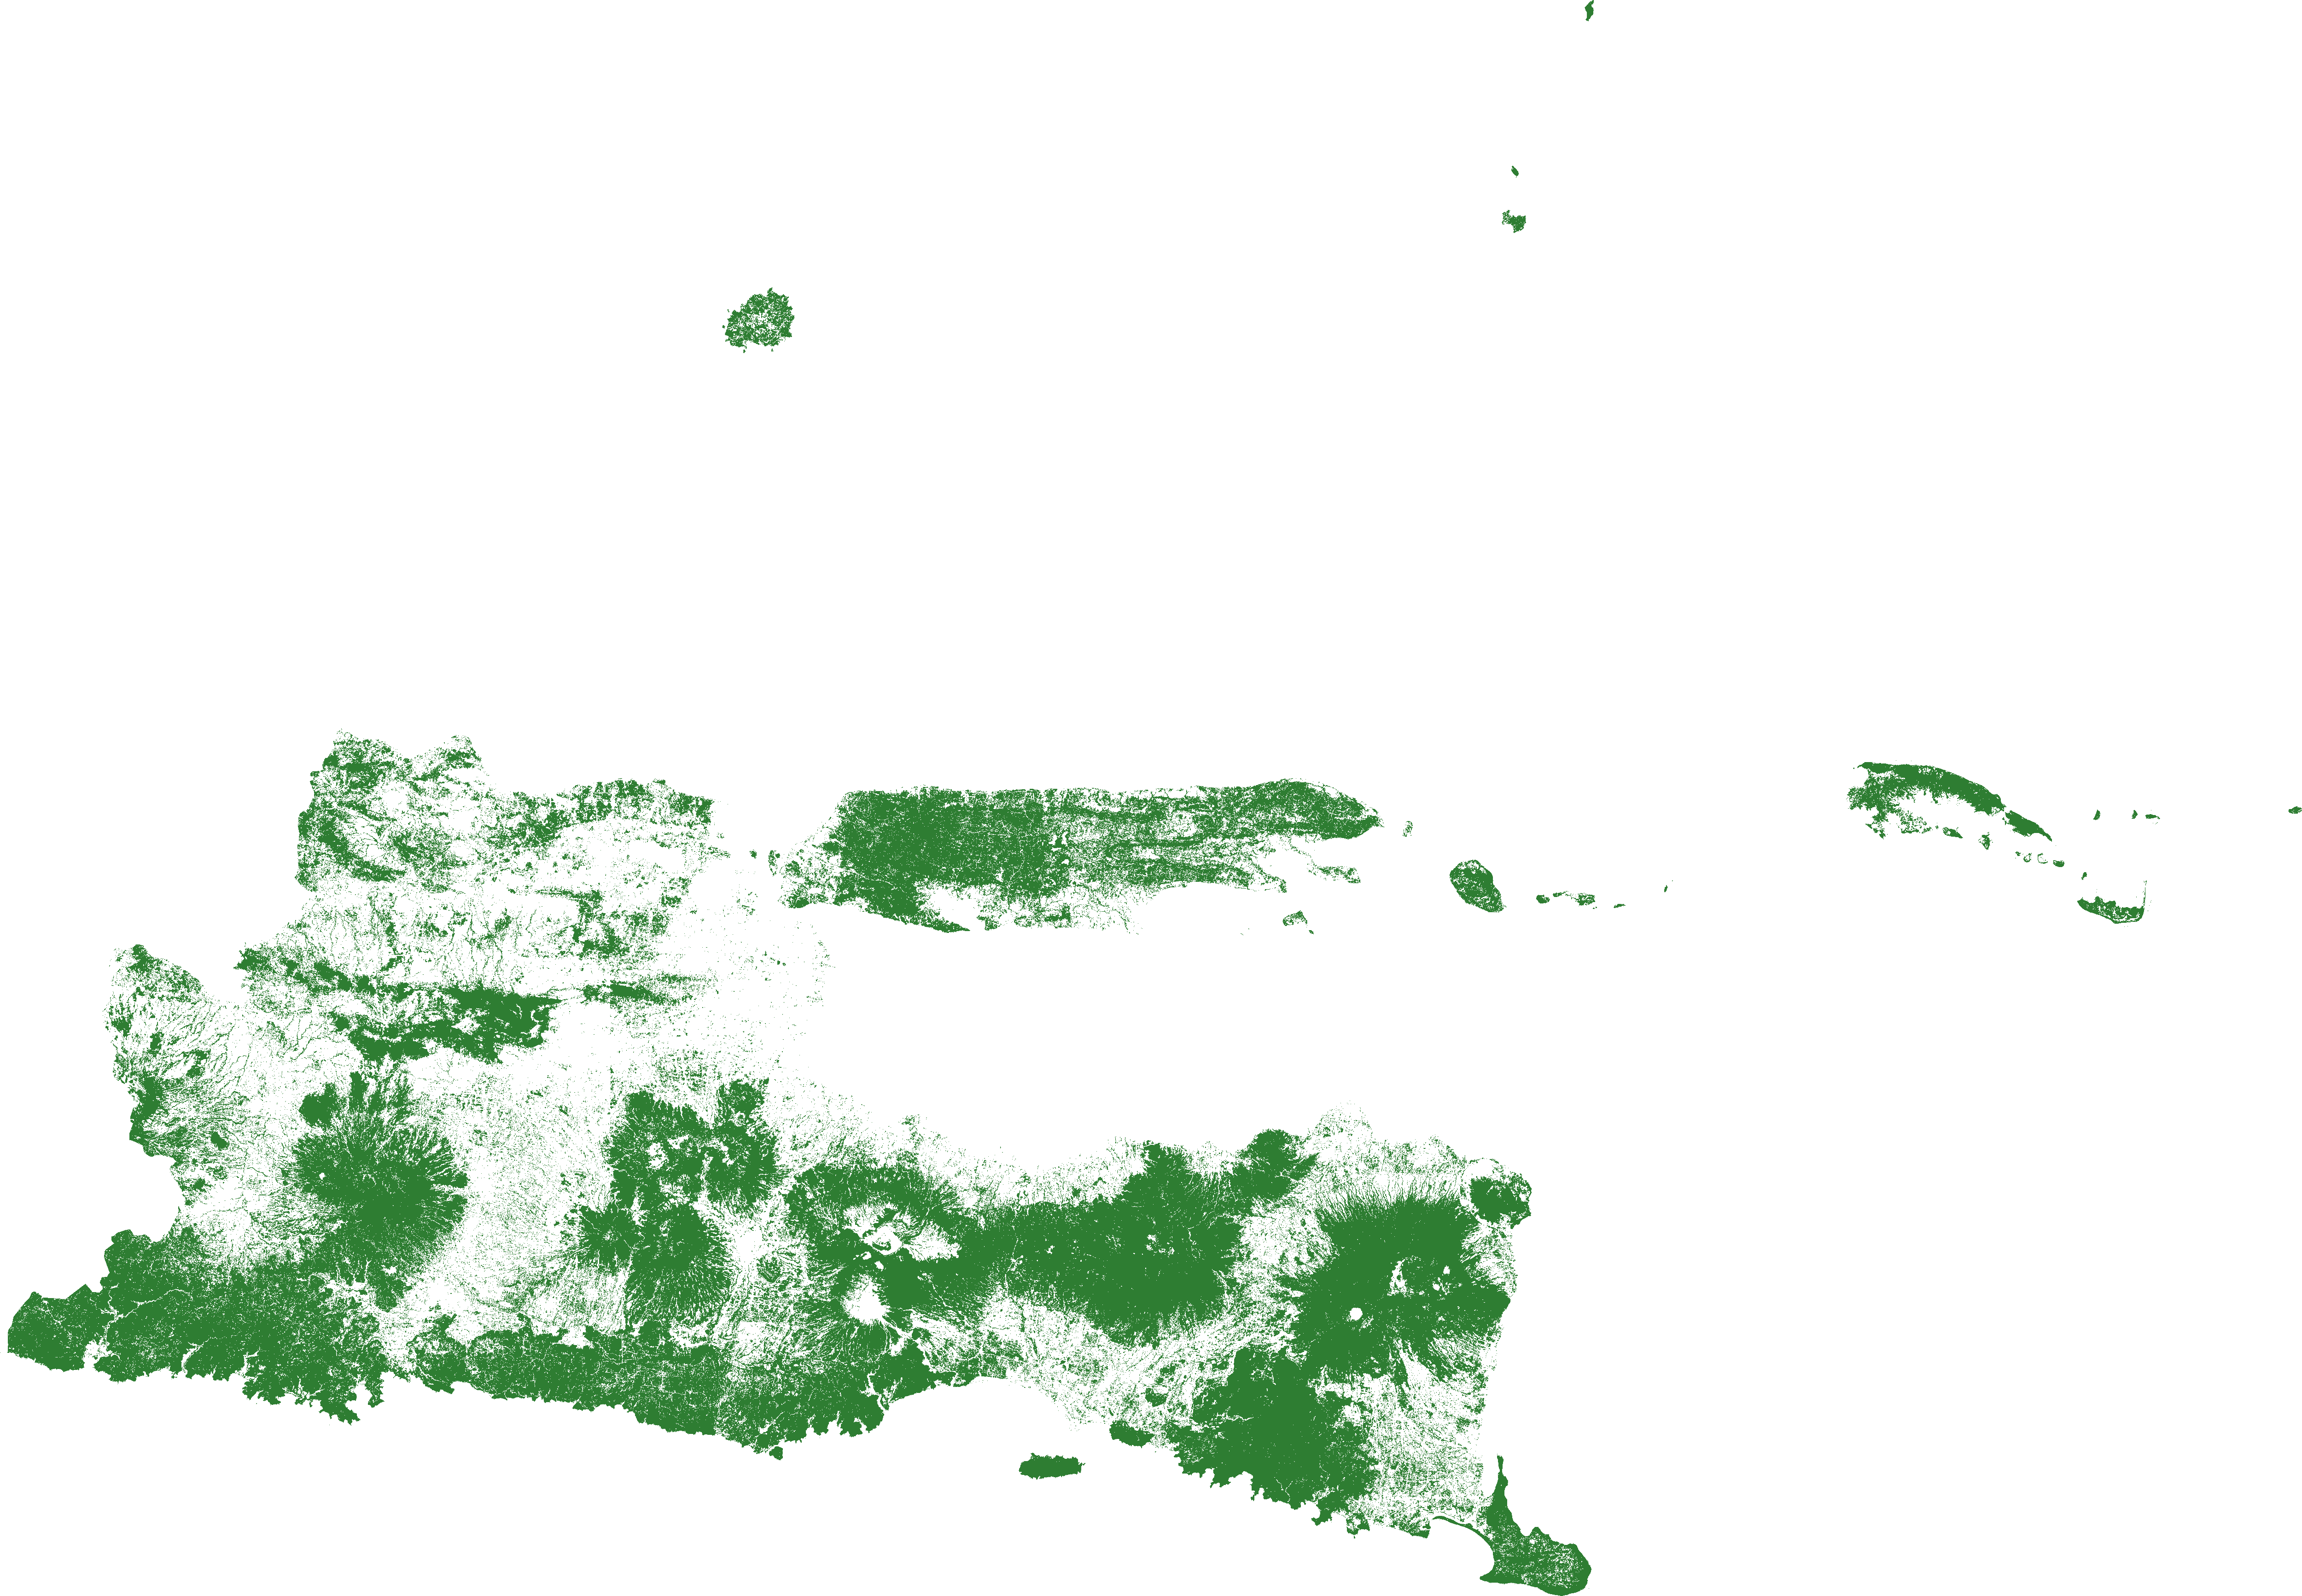
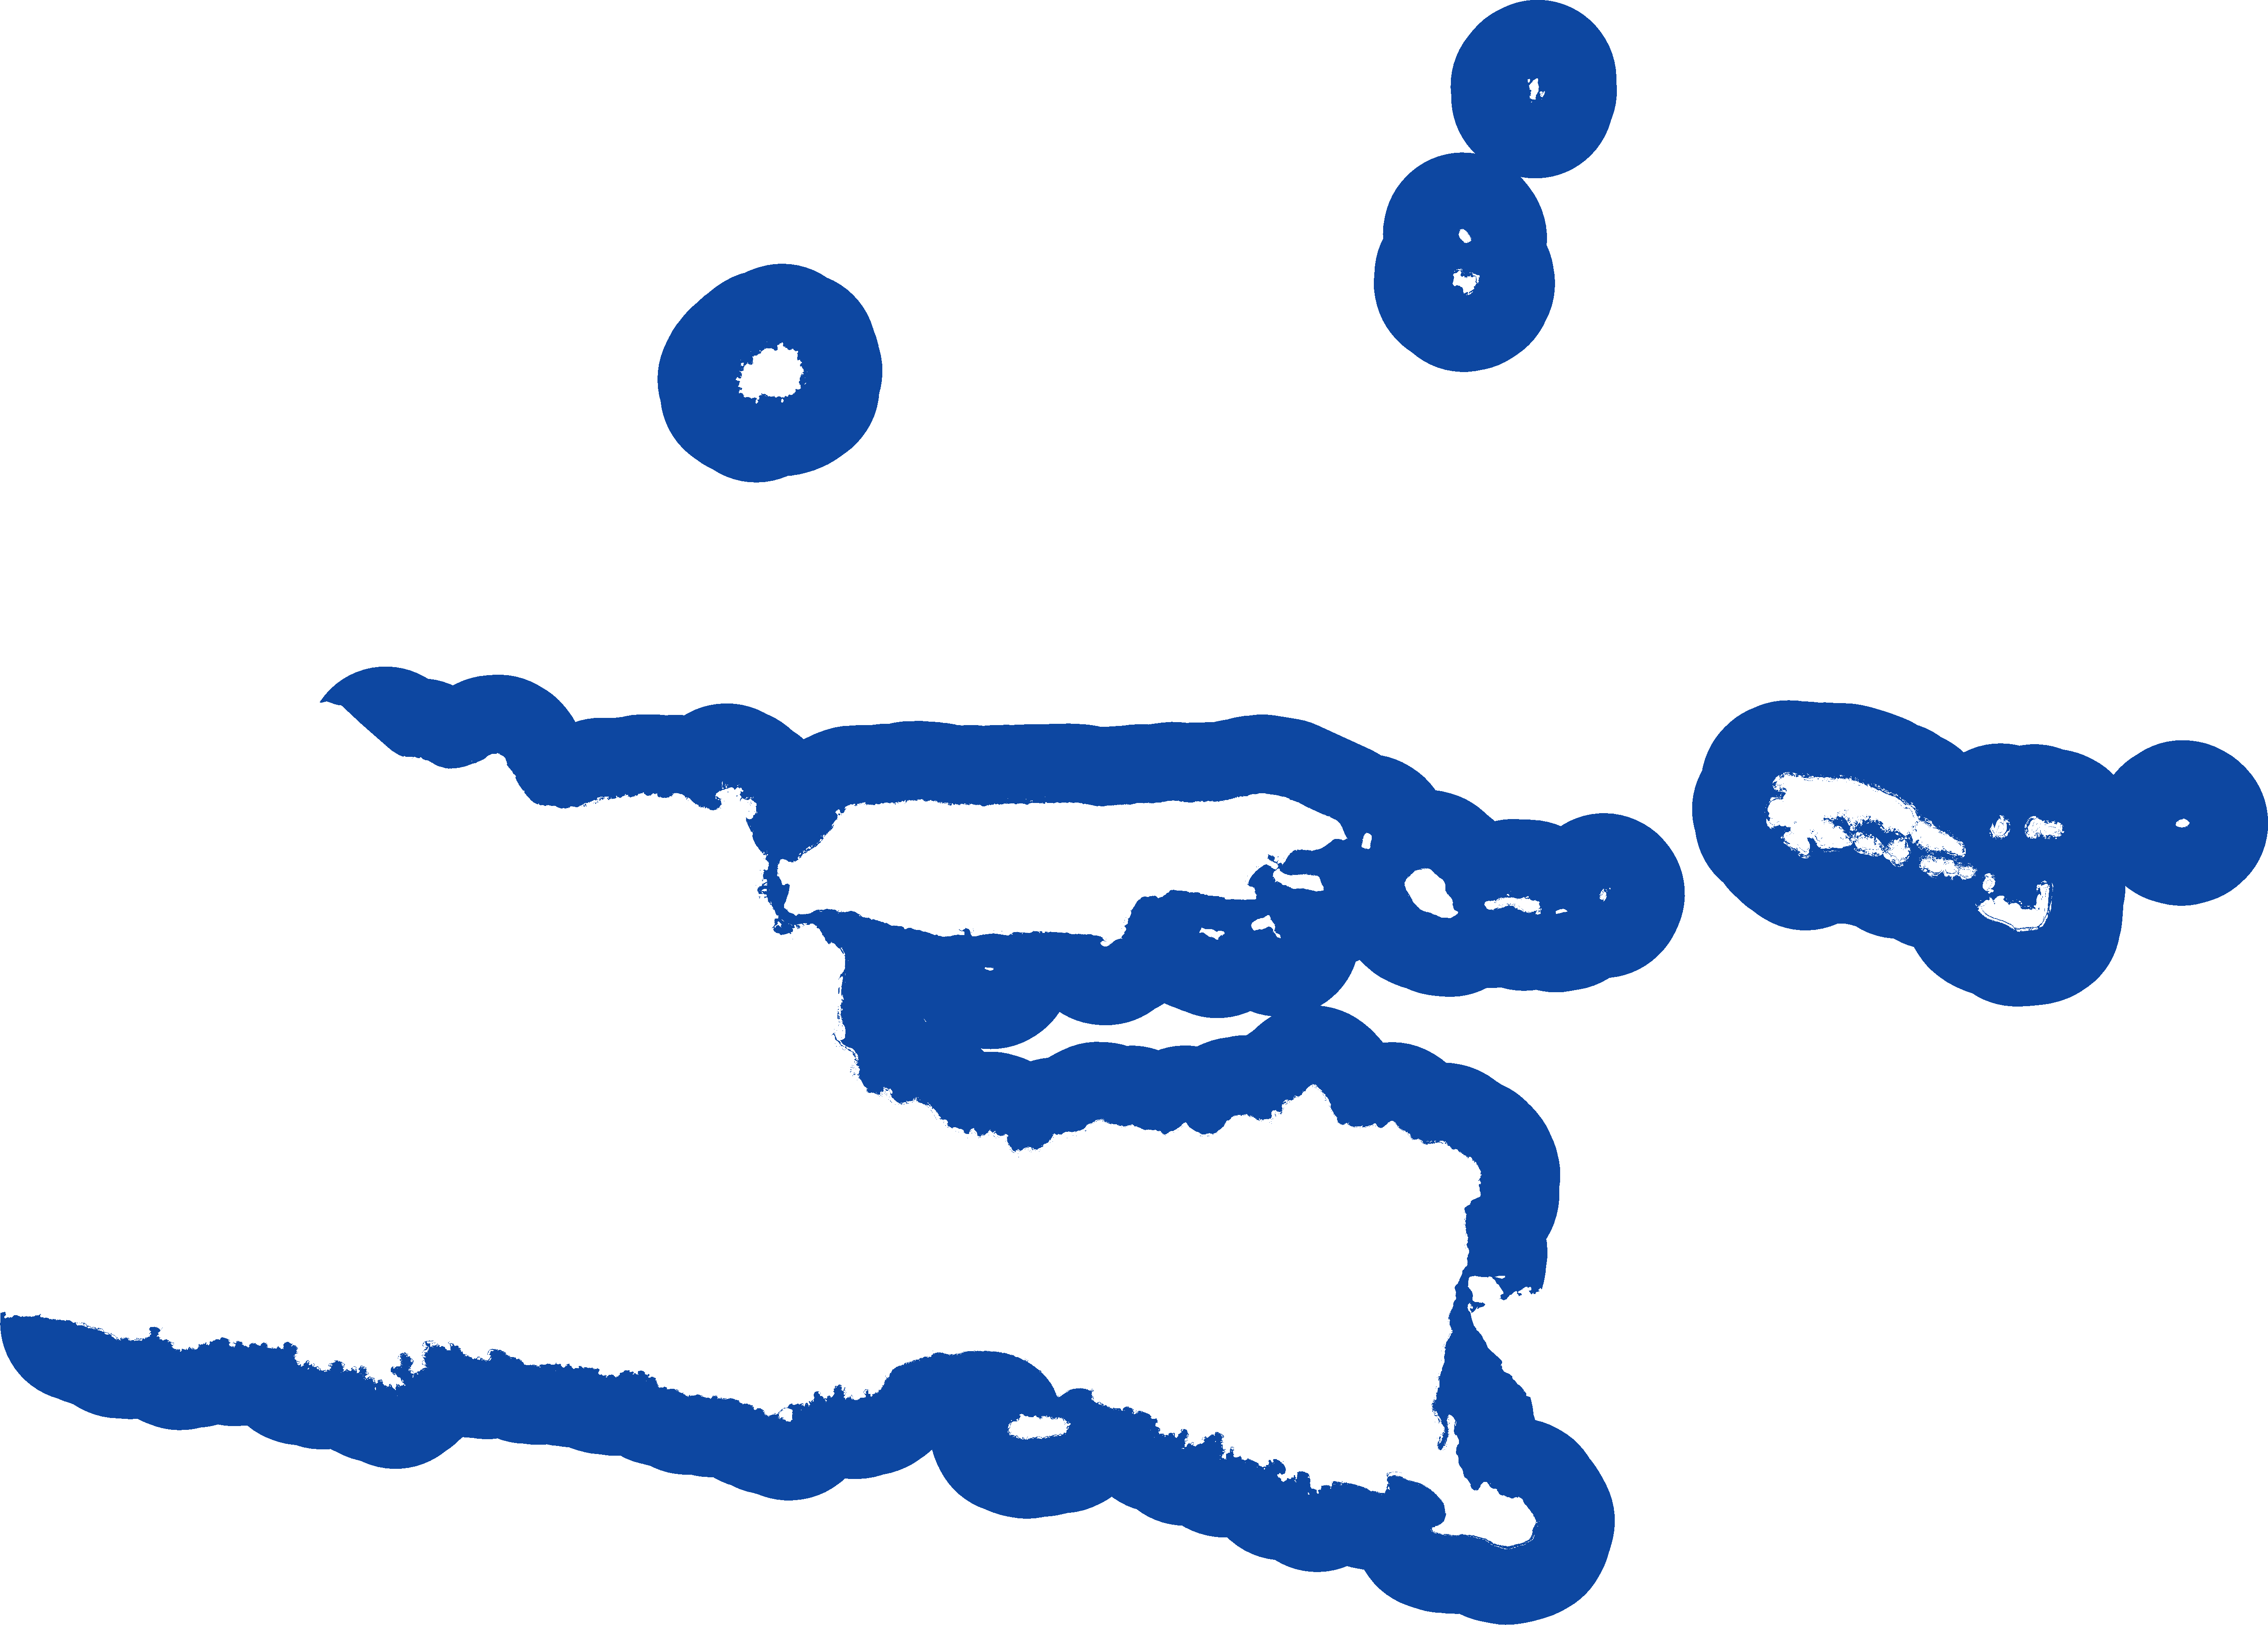
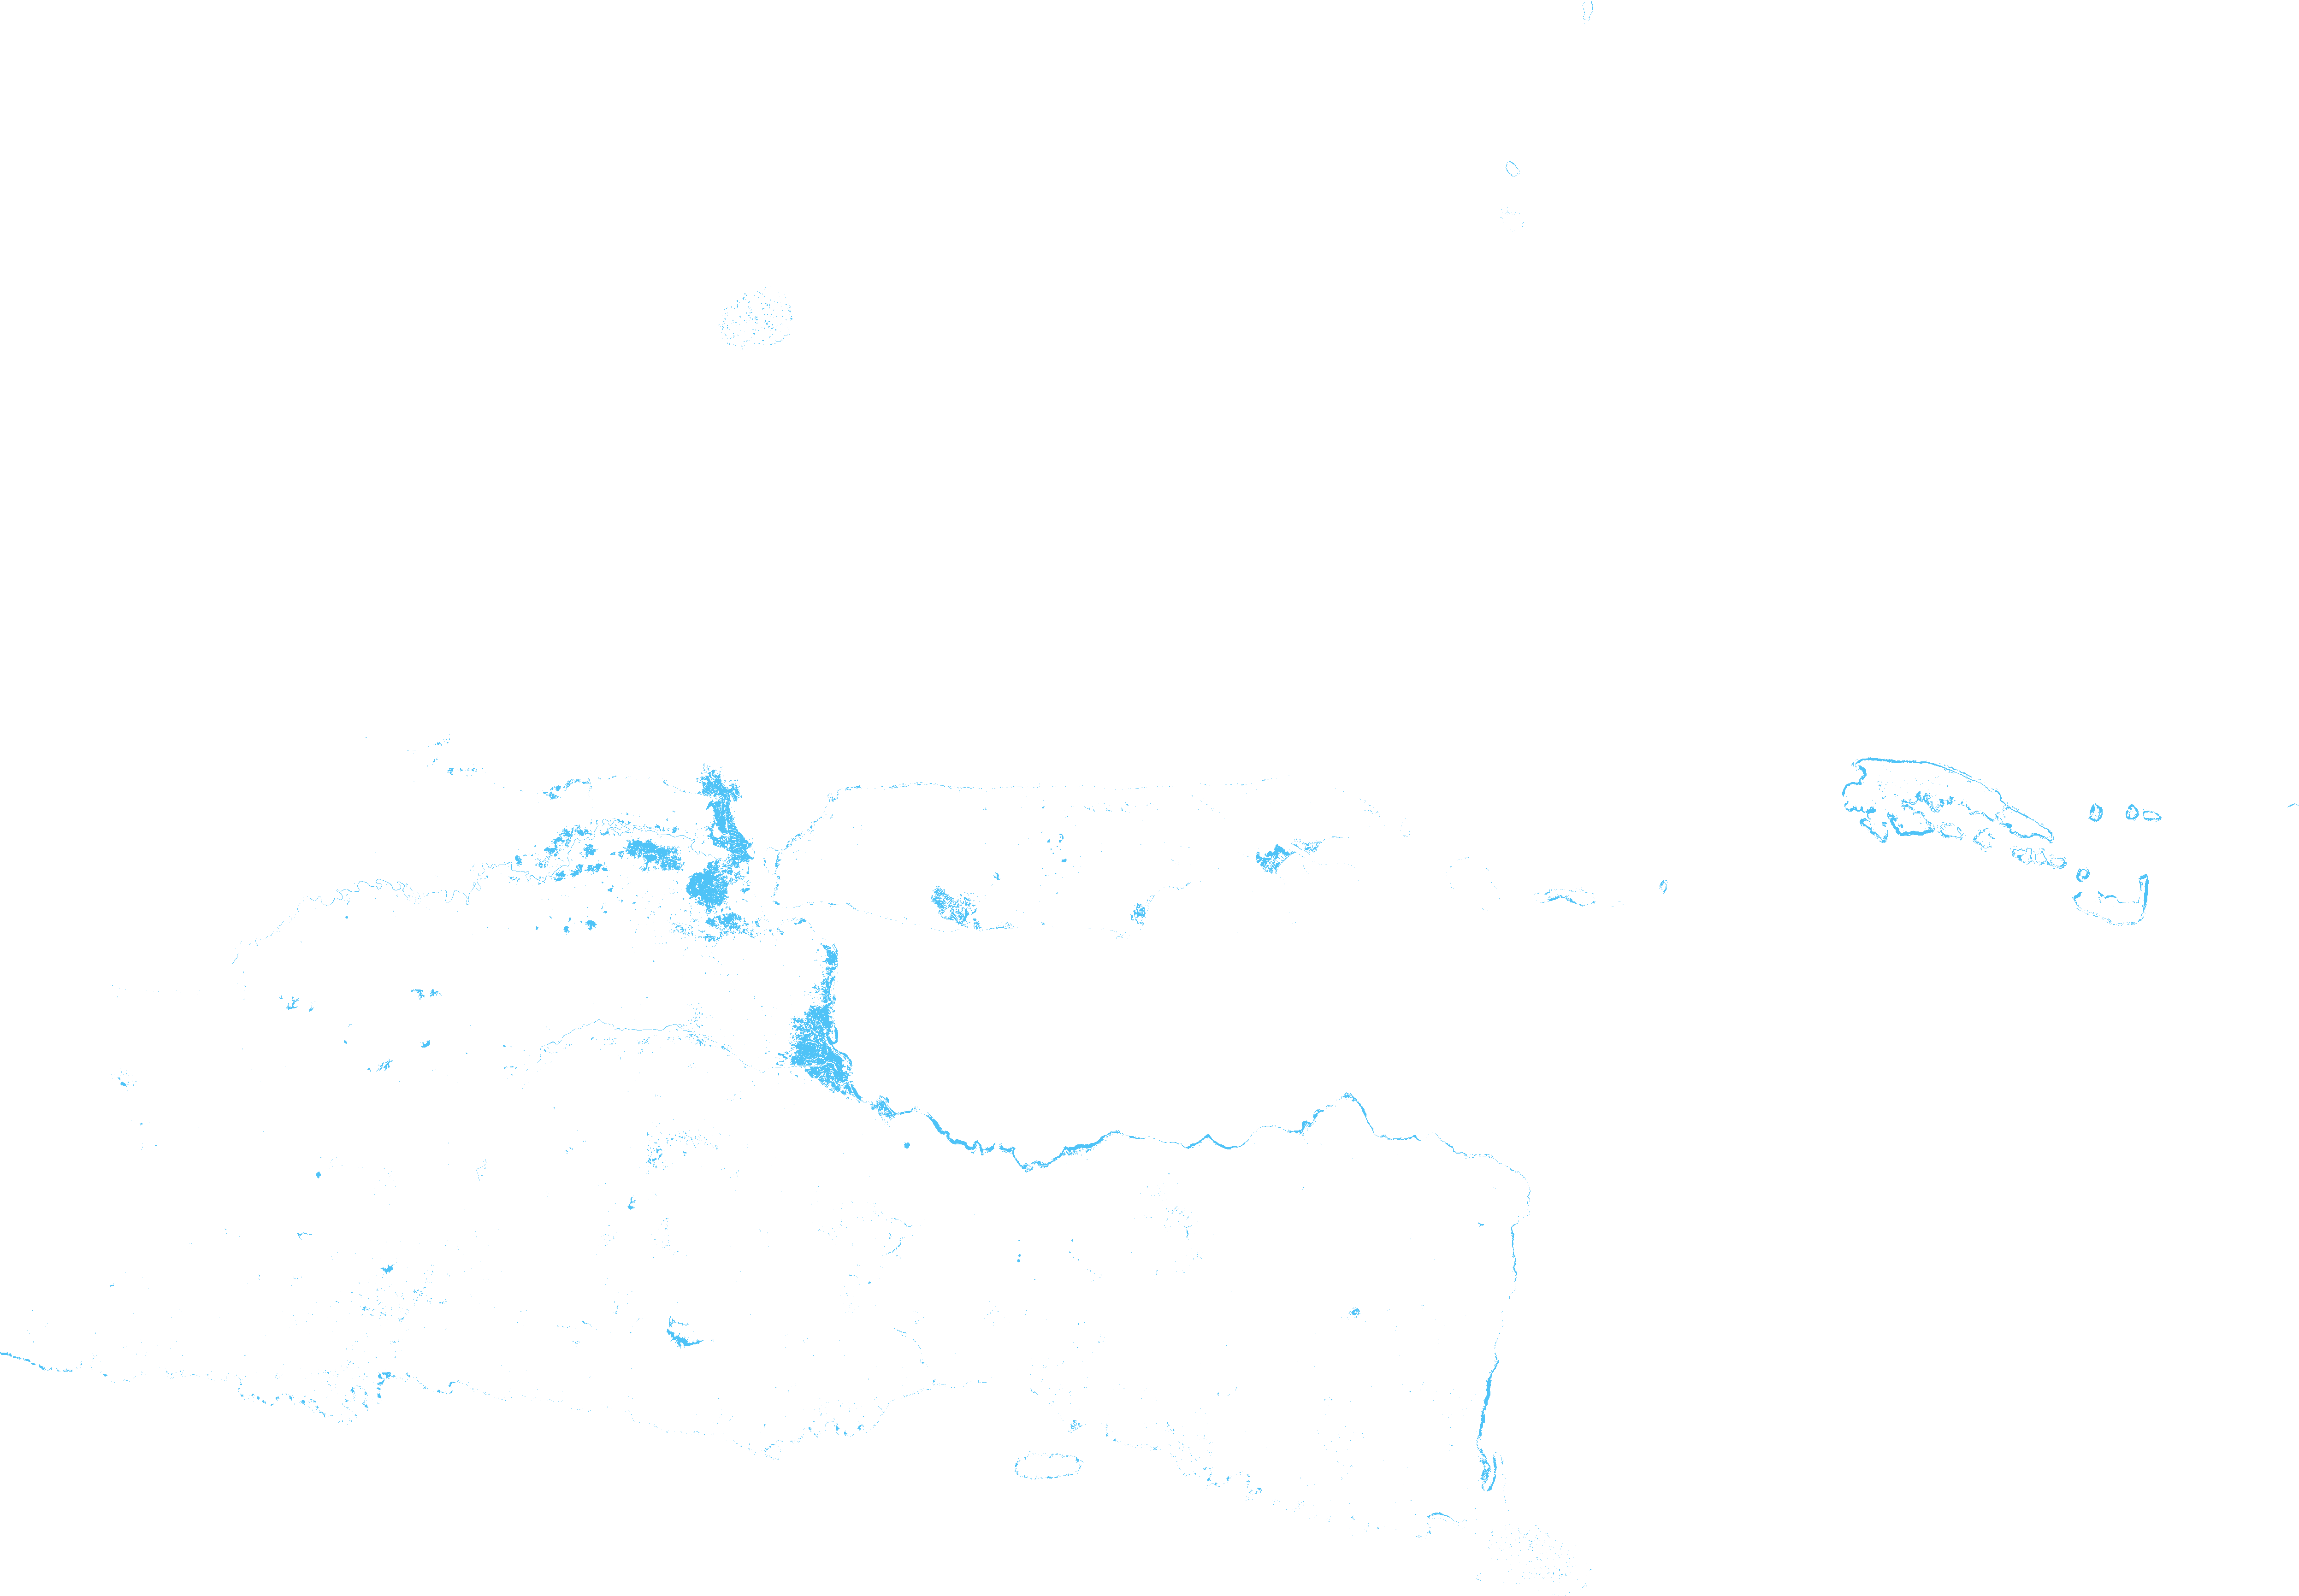

In [30]:
peta = peta_dasar(AOI)                      # AOI = [barat, selatan, timur, utara]

H, W = label_peta.shape
(s_, w_), (n_, e_) = batas_peta
dy, dx_ = (n_ - s_) / H, (e_ - w_) / W
for kid, k in KELAS.items():
    idx = NAMA_KELAS.index(k["nama"])        # label_peta menyimpan indeks kelas 0..5; -1 = tanpa data/awan
    baris, kolom = np.where(label_peta == idx)
    fg = folium.FeatureGroup(name=swatch(k["nama"], k["warna"]), show=True).add_to(peta)
    if len(baris) == 0:
        continue
    r0, r1, c0, c1 = baris.min(), baris.max() + 1, kolom.min(), kolom.max() + 1     # potong ke kotak pembatas kelas
    rgba_k = np.zeros((r1 - r0, c1 - c0, 4), dtype=np.uint8)
    rgba_k[label_peta[r0:r1, c0:c1] == idx] = hex_ke_rgb(k["warna"]) + [255]
    batas_k = [[n_ - r1 * dy, w_ + c0 * dx_], [n_ - r0 * dy, w_ + c1 * dx_]]
    ImageOverlay(image=rgba_k, bounds=batas_k, opacity=0.7, interactive=False, zindex=5).add_to(fg)

# Batas wilayah klasifikasi: Jawa Timur beserta perairan 12 mil laut
grup_aoi = folium.FeatureGroup(name="Batas wilayah Jawa Timur", show=True).add_to(peta)
folium.GeoJson(gpd.GeoSeries([AREA_JATIM], crs=4326).to_json(),
               style_function=lambda f: {"color": "white", "weight": 1.5, "fillOpacity": 0, "dashArray": "6"}).add_to(grup_aoi)

folium.LayerControl(position="topright", collapsed=False).add_to(peta)
berkas_peta = os.path.join(FOLDER_KERJA, "hasil_klasifikasi_jatim.html")
peta.save(berkas_peta)
print("Peta disimpan:", berkas_peta, "(dapat ditanam di web statis lewat <iframe>)")
peta

## 7.3 Implikasi Kebijakan

Luas hasil klasifikasi (tabel pada bagian 7.1) dapat dipakai sebagai bahan analisis kebijakan tata ruang dan lingkungan, bukan sebagai statistik resmi. Beberapa kaitannya:

| Kelas | Isu kebijakan yang relevan | Contoh rujukan (verifikasi nomor dan pasal sebelum dikutip) |
|---|---|---|
| Sawah | Perlindungan lahan pertanian pangan dan pengendalian alih fungsi lahan | UU 41/2009 tentang Perlindungan Lahan Pertanian Pangan Berkelanjutan |
| Bangunan | Pengendalian perkembangan kawasan terbangun, kesesuaian dengan rencana tata ruang | UU 26/2007 tentang Penataan Ruang; RTRW Provinsi Jawa Timur |
| Mangrove | Perlindungan dan rehabilitasi ekosistem mangrove pesisir | Perpres 120/2020 tentang Percepatan Rehabilitasi Mangrove |
| Lahan hijau | Ruang terbuka hijau, kawasan lindung, dan penyangga tangkapan air | UU 26/2007 (kawasan lindung dan RTH) |
| Laut dan Danau | Pengelolaan wilayah laut provinsi (12 mil laut) dan sumber daya air | UU 23/2014 tentang Pemerintahan Daerah |

Perbandingan ini baru bermakna bila ada dua periode citra (perubahan lahan) atau data rencana tata ruang untuk ditumpangsusunkan. Itu belum dilakukan pada notebook ini dan dapat menjadi pengembangan lanjutan.

In [31]:
_t = tab_luas["Luas (ha)"]
_p = tab_luas["Persentase (%)"]
display(Markdown("**Ringkasan luas hasil klasifikasi (skala peta %d m, setelah koreksi spasial bila diaktifkan):**\n\n" % SKALA_PETA +
                 "\n".join(f"* {n}: {_t[n]:,.0f} ha ({_p[n]:.2f}%)" for n in NAMA_KELAS) +
                 "\n\nCatatan: wilayah klasifikasi mencakup daratan Jawa Timur ditambah perairan 12 mil laut, sehingga persentase "
                 "Laut sangat dipengaruhi luas perairan tersebut. Untuk analisis daratan saja, bandingkan kelas daratan satu sama lain."))

**Ringkasan luas hasil klasifikasi (skala peta 120 m, setelah koreksi spasial bila diaktifkan):**

* Sawah: 1,423,359 ha (14.30%)
* Bangunan: 797,446 ha (8.01%)
* Mangrove: 63,994 ha (0.64%)
* Lahan hijau: 2,505,648 ha (25.17%)
* Perairan terbuka (laut): 5,038,099 ha (50.62%)
* Danau (ranu): 124,693 ha (1.25%)

Catatan: wilayah klasifikasi mencakup daratan Jawa Timur ditambah perairan 12 mil laut, sehingga persentase Laut sangat dipengaruhi luas perairan tersebut. Untuk analisis daratan saja, bandingkan kelas daratan satu sama lain.

# 8. Sistem Informasi: Streamlit dan Web Statis

## 8.1 Ekspor Data untuk Streamlit
Sel berikut menyimpan keluaran notebook ke folder `streamlit_app/data/` di folder kerja (Google Drive bila `SIMPAN_KE_DRIVE = True`, sehingga tidak perlu diproses ulang): satu gambar PNG transparan per kelas (agar kotak centang per kelas berfungsi pada peta), `meta.json` (metrik, tabel jumlah piksel, luas), dan CSV jumlah piksel per sampel. Resolusi PNG dikurangi dengan `FAKTOR_KURANG` agar peta ringan dimuat.

In [32]:
import json, shutil
from pathlib import Path
from PIL import Image

APP_DIR = Path(FOLDER_KERJA) / "streamlit_app"; DATA_APP = APP_DIR / "data"      # tersimpan di folder kerja (Drive)
DATA_APP.mkdir(parents=True, exist_ok=True)
FAKTOR_KURANG = 2                       # 2 = ambil tiap piksel kedua (240 m); 1 = resolusi penuh (file besar)

lab = label_peta[::FAKTOR_KURANG, ::FAKTOR_KURANG]
H2, W2 = lab.shape
(s_, w_), (n_, e_) = batas_peta
dy2, dx2 = (n_ - s_) / H2, (e_ - w_) / W2

lapisan = []
for kid, k in KELAS.items():
    idx = NAMA_KELAS.index(k["nama"])
    m = lab == idx
    if not m.any():
        continue
    r0, r1 = np.where(m.any(axis=1))[0][[0, -1]]
    c0, c1 = np.where(m.any(axis=0))[0][[0, -1]]
    rgba = np.zeros((r1 - r0 + 1, c1 - c0 + 1, 4), dtype=np.uint8)
    rgba[m[r0:r1 + 1, c0:c1 + 1]] = hex_ke_rgb(k["warna"]) + [255]
    nama_png = f"kelas_{kid}.png"
    Image.fromarray(rgba).save(DATA_APP / nama_png, optimize=True)
    lapisan.append({"kelas": k["nama"], "warna": k["warna"], "png": nama_png,
                    "bounds": [[n_ - (r1 + 1) * dy2, w_ + c0 * dx2], [n_ - r0 * dy2, w_ + (c1 + 1) * dx2]]})

def _tabel(t, dengan_indeks=True):
    return json.loads((t.reset_index() if dengan_indeks else t).to_json(orient="records"))

laporan = classification_report(y_test, pred_final, labels=NAMA_KELAS, zero_division=0, output_dict=True)
meta = {
    "judul": "Klasifikasi Penggunaan Lahan Jawa Timur (Sentinel-2)",
    "periode": [TANGGAL_MULAI, TANGGAL_AKHIR], "skala_peta_m": SKALA_PETA,
    "model_terbaik": MODEL_TERBAIK_NAMA, "akurasi": float(AKURASI_FINAL), "kappa": float(KAPPA_FINAL), "f1_macro": float(F1_FINAL),
    "fitur": list(FITUR_FINAL), "kelas": NAMA_KELAS, "warna": WARNA_KELAS,
    "jumlah_piksel": _tabel(tabel_piksel.rename_axis("kelas")), "perbandingan_model": _tabel(tab_model.round(4), False),
    "laporan_kelas": {n: {k: float(v) for k, v in laporan[n].items()} for n in NAMA_KELAS},
    "confusion_matrix": confusion_matrix(y_test, pred_final, labels=NAMA_KELAS).tolist(),
    "luas": _tabel(tab_luas.rename_axis("Kelas")), "lapisan": lapisan, "pusat": [(s_ + n_) / 2, (w_ + e_) / 2],
}
(DATA_APP / "meta.json").write_text(json.dumps(meta, ensure_ascii=False), encoding="utf-8")
tabel_per_sampel.to_csv(DATA_APP / "jumlah_piksel_per_sampel.csv")
(APP_DIR / "requirements.txt").write_text("streamlit>=1.35\nfolium>=0.17\npandas>=2.0\nnumpy>=1.26\n", encoding="utf-8")
import joblib
joblib.dump({"model": model_peta, "fitur": list(FITUR_FINAL), "kelas": NAMA_KELAS, "nama_model": MODEL_TERBAIK_NAMA},
            os.path.join(FOLDER_KERJA, "model_terbaik.joblib"))        # model akhir ikut disimpan ke Drive
print("Tersimpan di", APP_DIR, ":", sorted(p.name for p in DATA_APP.iterdir()))

Tersimpan di /content/drive/MyDrive/klasifikasi_jatim/streamlit_app : ['jumlah_piksel_per_sampel.csv', 'kelas_1.png', 'kelas_2.png', 'kelas_3.png', 'kelas_4.png', 'kelas_5.png', 'kelas_6.png', 'meta.json']


## 8.2 Aplikasi Streamlit (`app.py`)
Sel berikut menulis `streamlit_app/app.py`. Aplikasi memuat tiga tab: data dan jumlah piksel (per kelas dan per sampel), model dan akurasi, serta peta hasil dengan latar satelit Google dan kotak centang per kelas di pojok kanan atas.

In [33]:
APP_PY = r'''"""Aplikasi Streamlit: klasifikasi penggunaan lahan Jawa Timur (Sentinel-2).
Jalankan: streamlit run app.py   (membaca folder data/ hasil notebook)"""
import json
from pathlib import Path

import folium
import pandas as pd
import streamlit as st
import streamlit.components.v1 as components
from folium.plugins import Fullscreen
from folium.raster_layers import ImageOverlay

D = Path(__file__).parent / "data"
GOOGLE_SAT = "https://mt1.google.com/vt/lyrs=s&x={x}&y={y}&z={z}"
GOOGLE_HYB = "https://mt1.google.com/vt/lyrs=y&x={x}&y={y}&z={z}"

st.set_page_config(page_title="SIG Klasifikasi Lahan Jawa Timur", layout="wide")


@st.cache_data
def muat():
    return json.loads((D / "meta.json").read_text(encoding="utf-8"))


def swatch(nama, warna):
    return (f'<span style="background:{warna};opacity:.85;display:inline-block;width:12px;'
            f'height:12px;border:1px solid #333"></span> {nama}')


def buat_peta(meta, opacity):
    m = folium.Map(location=meta["pusat"], zoom_start=8, tiles=None, control_scale=True)
    folium.TileLayer(GOOGLE_SAT, attr="Google", name="Satelit Google", max_zoom=20).add_to(m)
    folium.TileLayer(GOOGLE_HYB, attr="Google", name="Satelit + label Google", max_zoom=20, show=False).add_to(m)
    folium.TileLayer("OpenStreetMap", name="OpenStreetMap", show=False).add_to(m)
    Fullscreen().add_to(m)
    for lap in meta["lapisan"]:   # satu lapisan per kelas -> kotak centang di pojok kanan atas
        fg = folium.FeatureGroup(name=swatch(lap["kelas"], lap["warna"]), show=True).add_to(m)
        ImageOverlay(image=str(D / lap["png"]), bounds=lap["bounds"], opacity=opacity,
                     interactive=False, zindex=5).add_to(fg)
    folium.LayerControl(position="topright", collapsed=False).add_to(m)
    return m


if not (D / "meta.json").exists():
    st.error("Folder data/ belum ada. Jalankan notebook sampai bagian 8.1 lalu salin streamlit_app/ ke sini.")
    st.stop()

meta = muat()
st.title(meta["judul"])
st.caption(f"UTS Proyek Sains Data | citra {meta['periode'][0]} s/d {meta['periode'][1]} | "
           f"resolusi peta {meta['skala_peta_m']} m")

tab_data, tab_model, tab_peta = st.tabs(["Data dan jumlah piksel", "Model dan akurasi", "Peta hasil"])

with tab_data:
    st.subheader("Jumlah piksel training dan testing per kelas")
    st.dataframe(pd.DataFrame(meta["jumlah_piksel"]).set_index("kelas"), use_container_width=True)
    st.subheader("Jumlah piksel per sampel")
    f_csv = D / "jumlah_piksel_per_sampel.csv"
    if f_csv.exists():
        per_sampel = pd.read_csv(f_csv)
        pilih = st.multiselect("Filter kelas", meta["kelas"], default=meta["kelas"])
        st.dataframe(per_sampel[per_sampel["kelas"].isin(pilih)], use_container_width=True, hide_index=True)
        st.download_button("Unduh CSV", f_csv.read_bytes(), "jumlah_piksel_per_sampel.csv")
    st.subheader("Fitur yang dipakai model")
    st.write(", ".join(meta["fitur"]))

with tab_model:
    c1, c2, c3, c4 = st.columns(4)
    c1.metric("Model terbaik", meta["model_terbaik"])
    c2.metric("Akurasi testing", f"{meta['akurasi']:.2%}")
    c3.metric("Kappa", f"{meta['kappa']:.3f}")
    c4.metric("F1 macro", f"{meta['f1_macro']:.3f}")
    st.subheader("Perbandingan model")
    st.dataframe(pd.DataFrame(meta["perbandingan_model"]), hide_index=True, use_container_width=True)
    st.subheader("Metrik per kelas (data testing)")
    st.dataframe(pd.DataFrame(meta["laporan_kelas"]).T.round(3), use_container_width=True)
    st.subheader("Confusion matrix")
    st.dataframe(pd.DataFrame(meta["confusion_matrix"], index=meta["kelas"], columns=meta["kelas"]),
                 use_container_width=True)

with tab_peta:
    opacity = st.slider("Transparansi lapisan klasifikasi", 0.2, 1.0, 0.7, 0.05)
    st.caption("Centang atau hilangkan centang kelas di pojok kanan atas peta.")
    components.html(buat_peta(meta, opacity)._repr_html_(), height=700)
    st.subheader("Luas hasil klasifikasi")
    st.dataframe(pd.DataFrame(meta["luas"]), hide_index=True, use_container_width=True)
'''
(APP_DIR / "app.py").write_text(APP_PY, encoding="utf-8")
print("Tersimpan:", APP_DIR / "app.py")

Tersimpan: /content/drive/MyDrive/klasifikasi_jatim/streamlit_app/app.py


## 8.3 Panduan Deployment (Penyebaran Model via Streamlit)

### 8.3.1 Deployment (Penyebaran Model via Streamlit)
Hasil notebook (gambar peta per kelas, metrik model, dan tabel jumlah piksel) disebarkan sebagai aplikasi web Streamlit. Aplikasi hanya membaca folder `data/` hasil bagian 8.1, sehingga tidak memerlukan akses ke Planetary Computer maupun proses klasifikasi ulang. Penyebaran dilakukan lewat Streamlit Community Cloud yang mengambil kode langsung dari repositori GitHub:

1. Unduh folder `streamlit_app/` dari Drive, lalu unggah isinya (`app.py`, `requirements.txt`, dan folder `data/`) ke repositori GitHub.
2. Buka share.streamlit.io, masuk dengan akun GitHub, lalu pilih **Create app**.
3. Isi *Repository* dengan `<username>/<nama-repositori>` (tanpa akhiran `.git`), *Branch* dengan `main`, dan *Main file path* dengan `app.py` (atau `streamlit_app/app.py` bila folder ikut terunggah utuh).
4. Klik **Deploy**. Proses pemasangan pustaka memakan waktu beberapa menit.

### 8.3.2 Akses Publik & URL Deployment
Aplikasi sudah dapat diakses publik pada tautan berikut:

**[https://sig-klasifikasi-jatimgit-jr9fczew66fhmldtpgufmi.streamlit.app/](https://sig-klasifikasi-jatimgit-jr9fczew66fhmldtpgufmi.streamlit.app/)**

Isi aplikasi: tab *Data dan jumlah piksel* (per kelas dan per sampel), tab *Model dan akurasi*, dan tab *Peta hasil* dengan latar satelit Google serta kotak centang per kelas di pojok kanan atas. Perubahan yang diunggah ke repositori GitHub akan diterapkan ke aplikasi secara otomatis. Aplikasi gratis dapat berhenti sementara bila lama tidak dibuka; bila itu terjadi, buka tautan dan tekan tombol untuk mengaktifkannya kembali.

### 8.3.3 Panduan Menjalankan Aplikasi Secara Lokal
Setelah folder `streamlit_app/` diunduh dari Drive, jalankan perintah berikut di terminal:
```bash
cd streamlit_app
pip install -r requirements.txt
streamlit run app.py
```
Browser terbuka otomatis di `http://localhost:8501`. Jika folder `data/` tidak ditemukan, jalankan ulang sel bagian 8.1 dan pastikan folder `data/` berada satu tempat dengan `app.py`.

# 9. Kesimpulan
Ringkasan berikut dibuat otomatis dari hasil eksekusi notebook.

In [34]:
terbaik_rasio = tab_rasio.sort_values("Akurasi rata-rata", ascending=False).iloc[0]
kelas_lemah = (pd.Series(f1_score(y_test, pred_final, labels=NAMA_KELAS, average=None, zero_division=0),
                         index=NAMA_KELAS).sort_values())
display(Markdown(f"""
**Ringkasan hasil**

* **Data:** {len(df)} sampel dari {df['kelas'].nunique()} kelas ({', '.join(f'{k}: {v}' for k, v in jml.items())}).
  Pembagian 80:20 menghasilkan **{len(X_train)} data training** dan **{len(X_test)} data testing**; karena 1 sampel = 1 piksel, itu setara **{N_PX_TRAIN} piksel training** dan **{N_PX_TEST} piksel testing**.
* **Fitur:** 10 band Sentinel-2A + 8 indeks spektral (NDVI, NDWI, MNDWI, NDBI, NDRE, EVI, SAVI, BSI).
* **Model:** {len(tab_model)} model dibandingkan ({', '.join(tab_model['Model'])}). Akurasi CV tertinggi: **{MODEL_TERBAIK_NAMA}** ({tab_model.loc[0, 'Akurasi CV']:.2%}), dengan skenario fitur terbaik
  **{FITUR_FINAL_NAMA}**. Model KNN dasar: k={BEST_K}, weights='{BEST_WEIGHTS}', metric='{BEST_METRIC}'.
* **Kinerja model final (data testing):** akurasi **{AKURASI_FINAL:.2%}**, Kappa **{KAPPA_FINAL:.3f}**,
  F1 macro **{F1_FINAL:.3f}**.
* **Eksperimen jumlah data latih:** akurasi mencapai nilai tertinggi (selisih ≤ 1 poin persentase) mulai **{n_cukup} sampel latih per kelas** (maksimum {akurasi_max:.2%}).
* **Eksperimen rasio split:** rata-rata akurasi tertinggi pada rasio **{terbaik_rasio['Rasio train:test']}**
  ({terbaik_rasio['Akurasi rata-rata']:.2%}).
* **Kelas dengan F1 terendah:** **{kelas_lemah.index[0]}** ({kelas_lemah.iloc[0]:.2f}),
  lihat *confusion matrix* untuk melihat kelas mana yang tertukar.
* **Peta:** hasil klasifikasi ditampilkan pada `hasil_klasifikasi_jatim.html` di atas citra Google Satellite.
"""))


**Ringkasan hasil**

* **Data:** 360 sampel dari 6 kelas (Sawah: 60, Bangunan: 60, Mangrove: 60, Lahan hijau: 60, Perairan terbuka (laut): 60, Danau (ranu): 60).
  Pembagian 80:20 menghasilkan **288 data training** dan **72 data testing**; karena 1 sampel = 1 piksel, itu setara **16574397 piksel training** dan **4143598 piksel testing**.
* **Fitur:** 10 band Sentinel-2A + 8 indeks spektral (NDVI, NDWI, MNDWI, NDBI, NDRE, EVI, SAVI, BSI).
* **Model:** 8 model dibandingkan (SVM (RBF), Extra Trees, KNN (hasil Grid Search), Random Forest, Hist Gradient Boosting, XGBoost, LightGBM, Naive Bayes (Gaussian)). Akurasi CV tertinggi: **SVM (RBF)** (93.64%), dengan skenario fitur terbaik
  **E. Band + indeks (18 fitur)**. Model KNN dasar: k=7, weights='distance', metric='euclidean'.
* **Kinerja model final (data testing):** akurasi **97.22%**, Kappa **0.967**,
  F1 macro **0.972**.
* **Eksperimen jumlah data latih:** akurasi mencapai nilai tertinggi (selisih ≤ 1 poin persentase) mulai **24 sampel latih per kelas** (maksimum 94.72%).
* **Eksperimen rasio split:** rata-rata akurasi tertinggi pada rasio **90:10**
  (93.89%).
* **Kelas dengan F1 terendah:** **Lahan hijau** (0.92),
  lihat *confusion matrix* untuk melihat kelas mana yang tertukar.
* **Peta:** hasil klasifikasi ditampilkan pada `hasil_klasifikasi_jatim.html` di atas citra Google Satellite.


### Catatan dan Keterbatasan
1. **Penskalaan Fitur (*Feature Scaling*)**: KNN, SVM, dan Naive Bayes bergantung pada jarak atau skala fitur sehingga memakai `StandardScaler` agar fitur bernilai besar tidak mendominasi fitur bernilai kecil. Model berbasis pohon (Random Forest, Extra Trees, Gradient Boosting) tidak memerlukannya.
2. **Keseimbangan Sampel**: Setiap kelas memakai 60 titik sampel (satu titik per poligon dari 60 poligon), sehingga jumlah sampel seimbang antarkelas (total 360 sampel) dan tidak ada kelas yang mendominasi pelatihan.
3. **Komputasi Prediksi Raster**: prediksi pada raster berjuta-juta piksel dilakukan per ubin (*tiling*) agar memori efisien dan permintaan citra ke Planetary Computer stabil. Waktu prediksi bergantung pada model terpilih (KNN dan SVM menghitung jarak/kernel ke data latih, model berbasis pohon umumnya lebih cepat).
4. **Kemiripan Spektral Perairan**: Danau dan laut terbuka sama-sama menyerap radiasi inframerah, sehingga memiliki respons spektral yang sangat mirip. Sampel laut yang tersebar pada berbagai zona (Laut Jawa, Samudera Hindia selatan, dan Selat Madura) membantu merepresentasikan variasi kekeruhan dan kondisi permukaan laut.
5. **Autokorelasi Spasial**: Titik sampel diambil dengan representatif 1 titik per poligon shapefile untuk meminimalkan autokorelasi spasial antartitik.
6. **Resolusi Raster**: Skala peta yang digunakan (120 m) adalah kompromi optimal antara detail spasial dan kecepatan pembacaan citra dari Planetary Computer.
7. **Cakupan Peta**: scene dipilih per tile MGRS agar seluruh ubin tertutup. Piksel yang tetap kosong karena awan sepanjang periode hanya diisi bila celahnya kecil (kelas terdekat, maksimum `ISI_MAKS_PX` piksel); celah yang lebih luas dilaporkan, bukan ditebak.
8. **Pemilihan Model**: model dipilih berdasarkan akurasi CV tertinggi pada 360 sampel. Selisih antarmodel yang kecil (di bawah simpangan baku CV) tidak berarti satu model pasti lebih baik pada data baru.
9. **Akurasi Titik vs Akurasi Peta**: akurasi testing (data titik sampel) hanya menguji piksel yang mirip dengan sampel. Tidak ada data referensi independen untuk seluruh peta, sehingga akurasi peta sebenarnya tidak diketahui. Contohnya, pada hasil mentah kelas Danau dapat mencapai sekitar 6% area kajian, jauh melebihi luas danau/waduk yang wajar; karena itu ditambahkan koreksi konteks spasial (bagian 7.1.1) yang merupakan aturan geografis, bukan hasil model.
10. **Kelas Tertutup (*Closed-set*)**: model hanya mengenal 6 kelas, sehingga tambak, tanah terbuka, kebun/hutan tanaman, dan awan sisa dipaksa masuk ke salah satunya (tambak cenderung menjadi Danau/Laut). Menambah kelas (misalnya tambak dan lahan terbuka) akan memperbaiki peta.
11. **Satu Piksel per Sampel**: setiap poligon hanya menyumbang satu piksel (bagian 5.2.1 menampilkan jumlah piksel yang sebenarnya tersedia di dalam poligon). Mengambil beberapa piksel per poligon dengan pembagian training/testing per poligon dapat menaikkan stabilitas model; hasil eksperimen jumlah data latih (bagian 6.7) membantu menentukan jumlah yang cukup.
12. **Rentang Waktu**: satu tahun komposit median menyamarkan fase tanam sawah (tergenang, tumbuh, bera), sehingga sawah dan lahan hijau dapat tertukar.
